# Carga de datos y análisis univariante

**Estación de Cabauw (BSRN), noviembre de 2023 a noviembre de 2024**

Este cuaderno une los 13 ficheros mensuales de la estación de Cabauw de la Baseline Surface Radiation Network (BSRN), publicados en PANGAEA (Knap, 2022), en un único conjunto minutal; comprueba su integridad temporal y describe cada variable por separado.

- **Entrada:** ficheros `CAB_radiation_AAAA-MM.tab`, de 2023-11 a 2024-11, que se seleccionan al ejecutar la sección 1.
- **Salida:** `radiation_data_completo.parquet` (570.240 registros minutales y 31 columnas), que usan los cuadernos posteriores.

**Contenido**

1. Carga y unión de los ficheros
2. Integridad temporal
3. Variables constantes
4. Radiación global descendente (SWD)
5. Radiación directa normal (DIR)
6. Radiación difusa (DIF)
7. Radiación de onda larga descendente (LWD)
8. Radiación de onda corta ascendente (SWU)
9. Radiación de onda larga ascendente (LWU)
10. Temperatura del aire (T2)
11. Humedad relativa (RH)
12. Valores faltantes
13. Fracción difusa (DIF/SWD)

## Configuración

In [1]:
!pip install -q missingno

import io
import re

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
import seaborn as sns
from google.colab import files

## 1. Carga y unión de los ficheros

Cada fichero `.tab` de PANGAEA comienza con una cabecera de metadatos de longitud variable; la tabla de datos empieza en la línea cuyo primer campo es `Date/Time`. Los ficheros se leen, se etiquetan con su fichero y mes de origen y se concatenan en orden cronológico.

In [2]:
def encontrar_fila_cabecera(texto, inicio_cabecera="Date/Time"):
    """
    Busca automáticamente la fila donde empieza la tabla de datos.
    En estos archivos, la cabecera empieza por 'Date/Time'.
    """
    for i, linea in enumerate(texto.splitlines()):
        if linea.startswith(inicio_cabecera):
            return i

    raise ValueError("No se ha encontrado la fila de cabecera que empieza por 'Date/Time'.")

In [3]:
def upload_radiation_files(set_datetime_index=False):
    """
    Carga varios archivos .tab de radiación, los une en un único DataFrame
    y devuelve también un resumen de carga.
    """

    uploaded = files.upload()

    dataframes = []
    resumen = []

    for filename, content in uploaded.items():

        texto = content.decode("utf-8")

        # Detectar automáticamente dónde empieza la tabla
        fila_cabecera = encontrar_fila_cabecera(texto)

        df_temp = pd.read_csv(
            io.StringIO(texto),
            sep="\t",
            skiprows=fila_cabecera,
            parse_dates=["Date/Time"]
        )

        # Añadir información del archivo de origen
        df_temp["source_file"] = filename

        # Extraer año-mes desde el nombre del archivo, por ejemplo 2024-01
        match = re.search(r"\d{4}-\d{2}", filename)
        df_temp["year_month"] = match.group(0) if match else None

        resumen.append({
            "archivo": filename,
            "filas": df_temp.shape[0],
            "columnas": df_temp.shape[1],
            "fecha_inicio": df_temp["Date/Time"].min(),
            "fecha_fin": df_temp["Date/Time"].max()
        })

        dataframes.append(df_temp)

        print(f'Archivo cargado: {filename} | Filas: {df_temp.shape[0]} | Columnas: {df_temp.shape[1]}')

    # Unir todos los archivos
    df = pd.concat(dataframes, ignore_index=True)

    # Ordenar por fecha
    df = df.sort_values("Date/Time").reset_index(drop=True)

    resumen_carga = pd.DataFrame(resumen)

    # Date/Time como índice (opcional)
    if set_datetime_index:
        df = df.set_index("Date/Time")

    return df, resumen_carga

In [4]:
df, resumen_carga = upload_radiation_files()

Saving CAB_radiation_2023-11.tab to CAB_radiation_2023-11.tab
Saving CAB_radiation_2023-12.tab to CAB_radiation_2023-12.tab
Saving CAB_radiation_2024-01.tab to CAB_radiation_2024-01.tab
Saving CAB_radiation_2024-02.tab to CAB_radiation_2024-02.tab
Saving CAB_radiation_2024-03.tab to CAB_radiation_2024-03.tab
Saving CAB_radiation_2024-04.tab to CAB_radiation_2024-04.tab
Saving CAB_radiation_2024-05.tab to CAB_radiation_2024-05.tab
Saving CAB_radiation_2024-06.tab to CAB_radiation_2024-06.tab
Saving CAB_radiation_2024-07.tab to CAB_radiation_2024-07.tab
Saving CAB_radiation_2024-08.tab to CAB_radiation_2024-08.tab
Saving CAB_radiation_2024-09.tab to CAB_radiation_2024-09.tab
Saving CAB_radiation_2024-10.tab to CAB_radiation_2024-10.tab
Saving CAB_radiation_2024-11.tab to CAB_radiation_2024-11.tab
Archivo cargado: CAB_radiation_2023-11.tab | Filas: 43200 | Columnas: 31
Archivo cargado: CAB_radiation_2023-12.tab | Filas: 44640 | Columnas: 31
Archivo cargado: CAB_radiation_2024-01.tab | Fil

In [5]:
df.head()

,Date/Time,Height [m],SWD [W/m**2],SWD std dev [W/m**2],SWD min [W/m**2],SWD max [W/m**2],DIR [W/m**2],DIR std dev [W/m**2],DIR min [W/m**2],DIR max [W/m**2],...,SWU max [W/m**2],LWU [W/m**2],LWU std dev [W/m**2],LWU min [W/m**2],LWU max [W/m**2],T2 [°C],RH [%],PoPoPoPo [hPa],source_file,year_month
0,2023-11-01 00:00:00,2,-1.0,0.1,-1.0,-1.0,1.0,0.0,1.0,1.0,...,0.0,369.0,0.1,369.0,370.0,11.7,94.0,1003.0,CAB_radiation_2023-11.tab,2023-11
1,2023-11-01 00:01:00,2,-1.0,0.1,-1.0,-1.0,1.0,0.0,1.0,1.0,...,0.0,370.0,0.1,369.0,370.0,11.7,94.0,1003.0,CAB_radiation_2023-11.tab,2023-11
2,2023-11-01 00:02:00,2,-1.0,0.1,-1.0,-1.0,1.0,0.0,1.0,1.0,...,0.0,369.0,0.1,369.0,369.0,11.7,94.2,1003.0,CAB_radiation_2023-11.tab,2023-11
3,2023-11-01 00:03:00,2,-1.0,0.1,-1.0,-1.0,1.0,0.0,1.0,1.0,...,0.0,369.0,0.1,369.0,369.0,11.7,94.0,1003.0,CAB_radiation_2023-11.tab,2023-11
4,2023-11-01 00:04:00,2,-1.0,0.1,-1.0,-1.0,1.0,0.0,1.0,1.0,...,0.0,369.0,0.1,369.0,369.0,11.7,94.2,1003.0,CAB_radiation_2023-11.tab,2023-11


In [6]:
# Conjunto consolidado en formato Parquet
df.to_parquet(
    "radiation_data_completo.parquet",
    index=False,
    compression="snappy"
)

files.download("radiation_data_completo.parquet")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 2. Integridad temporal

Se añaden variables de calendario y se comprueba que la serie es monótona, sin marcas duplicadas y sin minutos omitidos entre el primer y el último registro.

In [7]:
# Fecha como tipo datetime, pero sin hora
df["date"] = df["Date/Time"].dt.floor("D")

# Hora como texto
df["time"] = df["Date/Time"].dt.strftime("%H:%M:%S")

df[["Date/Time", "date", "time"]].head()

,Date/Time,date,time
0,2023-11-01 00:00:00,2023-11-01,00:00:00
1,2023-11-01 00:01:00,2023-11-01,00:01:00
2,2023-11-01 00:02:00,2023-11-01,00:02:00
3,2023-11-01 00:03:00,2023-11-01,00:03:00
4,2023-11-01 00:04:00,2023-11-01,00:04:00


In [8]:
df["year"] = df["Date/Time"].dt.year
df["month"] = df["Date/Time"].dt.month
df["day"] = df["Date/Time"].dt.day
df["hour"] = df["Date/Time"].dt.hour
df["minute"] = df["Date/Time"].dt.minute
df["day_of_week"] = df["Date/Time"].dt.day_name()

In [9]:
df = df.sort_values("Date/Time").reset_index(drop=True)

In [10]:
print("Fecha mínima:", df["Date/Time"].min())
print("Fecha máxima:", df["Date/Time"].max())

Fecha mínima: 2023-11-01 00:00:00
Fecha máxima: 2024-11-30 23:59:00


In [11]:
df["Date/Time"].is_monotonic_increasing

True

In [12]:
duplicados = df["Date/Time"].duplicated().sum()
print("Número de fechas duplicadas:", duplicados)

Número de fechas duplicadas: 0


In [13]:
rango_esperado = pd.date_range(
    start=df["Date/Time"].min(),
    end=df["Date/Time"].max(),
    freq="min"
)

print("Registros reales:", len(df))
print("Registros esperados:", len(rango_esperado))
print("Diferencia:", len(rango_esperado) - len(df))

Registros reales: 570240
Registros esperados: 570240
Diferencia: 0


## 3. Variables constantes

La altura de medida es constante (2 m) en todo el periodo y no aporta información, por lo que se descarta.

In [14]:
df[["Height [m]"]].describe()

,Height [m]
count,570240.0
mean,2.0
std,0.0
min,2.0
25%,2.0
50%,2.0
75%,2.0
max,2.0


In [15]:
df["Height [m]"].nunique()

1

In [16]:
df = df.drop(columns=["Height [m]"], errors="ignore")

## 4. Radiación global descendente (SWD)

La variable SWD [W/m²] presenta una distribución fuertemente asimétrica hacia la derecha, con una elevada concentración de valores próximos a cero y una cola larga hacia valores altos. Se observa un porcentaje elevado de valores negativos, aunque estos se concentran principalmente en magnitudes pequeñas, especialmente en -1 W/m². Esto sugiere que dichos valores podrían estar asociados a ruido instrumental, calibración o redondeo en periodos de baja irradiancia. La variable apenas presenta valores ausentes, por lo que el principal aspecto a revisar no es la completitud, sino el tratamiento de valores negativos y la separación entre periodos diurnos y nocturnos.

In [17]:
col_fecha = "Date/Time"
col_swd = "SWD [W/m**2]"

df[col_fecha] = pd.to_datetime(df[col_fecha])
df["hour"] = df[col_fecha].dt.hour

In [18]:
resumen_horario = (
    df.groupby("hour")[col_swd]
    .agg(
        count="count",
        mean="mean",
        median="median",
        min="min",
        max="max"
    )
    .reindex(range(24))
)

resumen_horario

,count,mean,median,min,max
hour,,,,,
0,23760,-0.765067,-1.0,-3.0,0.0
1,23755,-0.750789,-1.0,-3.0,0.0
2,23760,-0.735816,-1.0,-3.0,3.0
3,23760,0.313931,-1.0,-3.0,52.0
4,23756,10.072234,0.0,-3.0,187.0
5,23743,39.116076,0.0,-3.0,439.0
6,23659,87.056680,25.0,-3.0,664.0
7,23586,155.295853,84.5,-2.0,923.0
8,23570,228.592787,152.0,0.0,988.0


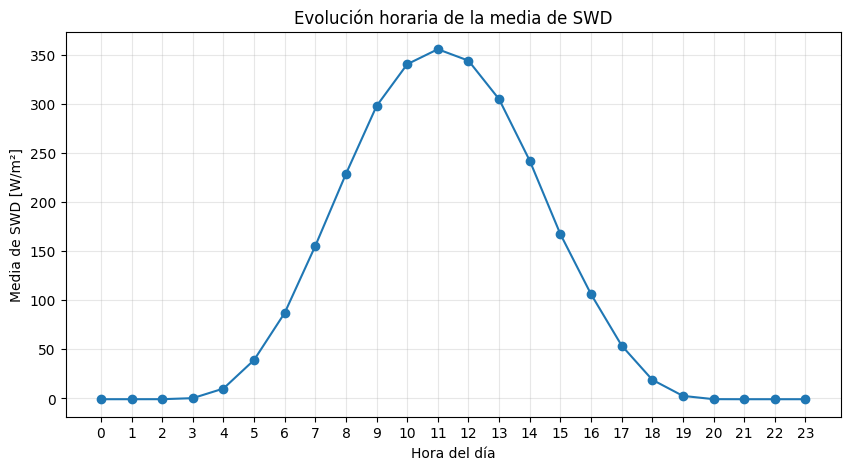

In [19]:
plt.figure(figsize=(10, 5))

plt.plot(
    resumen_horario.index,
    resumen_horario["mean"],
    marker="o"
)

plt.title("Evolución horaria de la media de SWD")
plt.xlabel("Hora del día")
plt.ylabel("Media de SWD [W/m²]")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)

plt.show()

In [20]:
negativos_por_hora = (
    df[df[col_swd] < 0]
    .groupby("hour")
    .size()
    .reindex(range(24), fill_value=0)
)

negativos_por_hora

,0
hour,
0,17161
1,16869
2,16530
3,13673
4,11009
5,8428
6,5659
7,1111
8,0


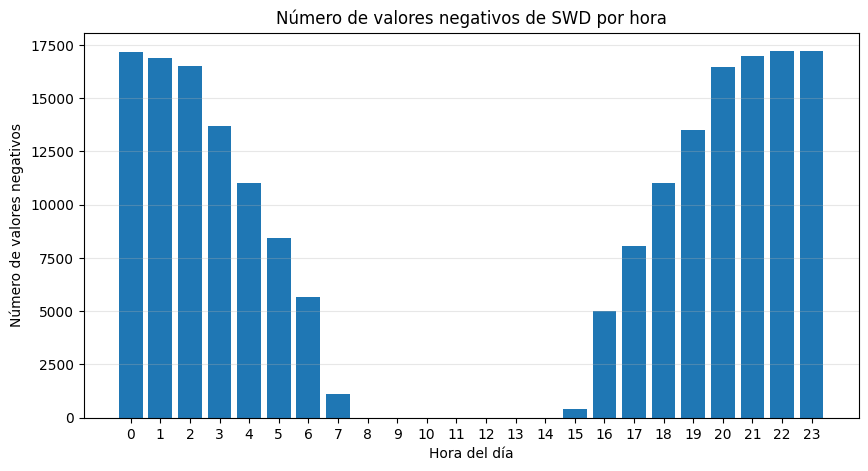

In [21]:
plt.figure(figsize=(10, 5))

plt.bar(
    negativos_por_hora.index,
    negativos_por_hora.values
)

plt.title("Número de valores negativos de SWD por hora")
plt.xlabel("Hora del día")
plt.ylabel("Número de valores negativos")
plt.xticks(range(24))
plt.grid(True, axis="y", alpha=0.3)

plt.show()

In [22]:
total_por_hora = (
    df.groupby("hour")
    .size()
    .reindex(range(24), fill_value=0)
)

porcentaje_negativos_por_hora = (
    negativos_por_hora / total_por_hora * 100
).fillna(0)

porcentaje_negativos_por_hora

,0
hour,
0,72.226431
1,70.997475
2,69.570707
3,57.546296
4,46.334175
5,35.471380
6,23.817340
7,4.675926
8,0.000000


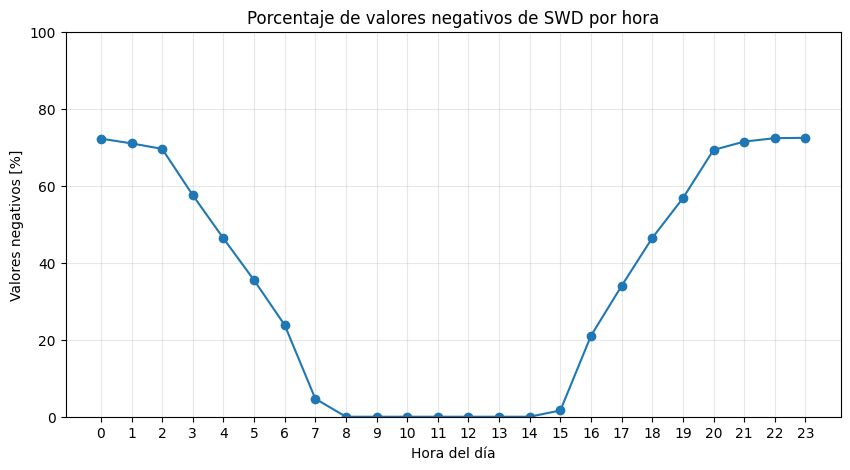

In [23]:
plt.figure(figsize=(10, 5))

plt.plot(
    porcentaje_negativos_por_hora.index,
    porcentaje_negativos_por_hora.values,
    marker="o"
)

plt.title("Porcentaje de valores negativos de SWD por hora")
plt.xlabel("Hora del día")
plt.ylabel("Valores negativos [%]")
plt.xticks(range(24))
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)

plt.show()

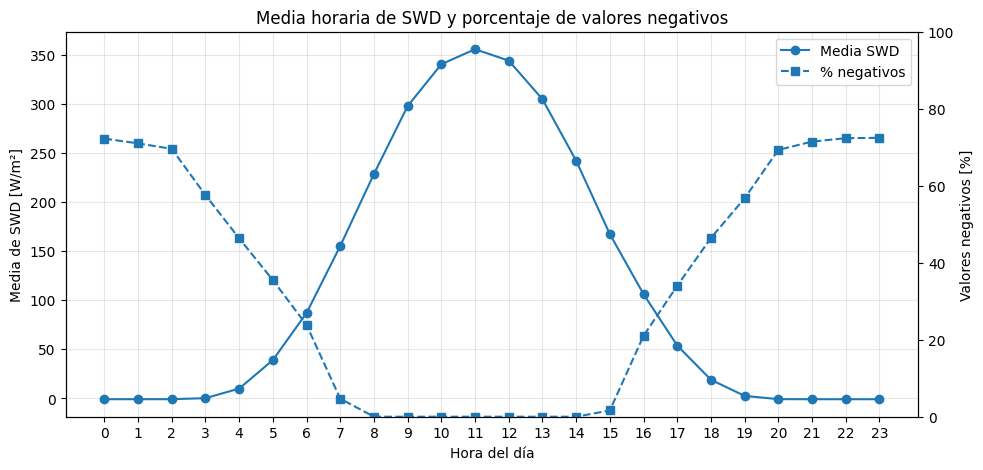

In [24]:
fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.plot(
    resumen_horario.index,
    resumen_horario["mean"],
    marker="o",
    label="Media SWD"
)

ax1.set_xlabel("Hora del día")
ax1.set_ylabel("Media de SWD [W/m²]")
ax1.set_xticks(range(24))
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()

ax2.plot(
    porcentaje_negativos_por_hora.index,
    porcentaje_negativos_por_hora.values,
    marker="s",
    linestyle="--",
    label="% negativos"
)

ax2.set_ylabel("Valores negativos [%]")
ax2.set_ylim(0, 100)

plt.title("Media horaria de SWD y porcentaje de valores negativos")

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines_1 + lines_2,
    labels_1 + labels_2,
    loc="upper right"
)

plt.show()

Los valores negativos de SWD se concentran principalmente durante la noche y en las horas de baja irradiancia, desapareciendo prácticamente durante las horas centrales del día. Dado que la radiación solar descendente no debería tomar valores negativos desde el punto de vista físico, estos valores pueden interpretarse como pequeñas desviaciones instrumentales alrededor del cero, probablemente asociadas a ruido de medición, calibración o comportamiento nocturno del sensor.

### Valores negativos, nulos y positivos por hora

In [25]:
col_swd = "SWD [W/m**2]"

df["estado_swd"] = np.select(
    [
        df[col_swd] < 0,
        df[col_swd] == 0,
        df[col_swd] > 0
    ],
    [
        "Negativo",
        "Cero",
        "Positivo"
    ],
    default="Missing"
)

In [26]:
tabla_estado_hora = (
    df.groupby(["hour", "estado_swd"])
    .size()
    .unstack(fill_value=0)
    .reindex(range(24), fill_value=0)
)

tabla_estado_hora

estado_swd,Cero,Missing,Negativo,Positivo
hour,,,,
0,6599,0,17161,0
1,6886,5,16869,0
2,7222,0,16530,8
3,6750,0,13673,3337
4,5061,4,11009,7686
5,3878,17,8428,11437
6,2563,101,5659,15437
7,1348,174,1111,21127
8,37,190,0,23533


In [27]:
tabla_estado_hora_pct = (
    tabla_estado_hora
    .div(tabla_estado_hora.sum(axis=1), axis=0)
    * 100
)

tabla_estado_hora_pct

estado_swd,Cero,Missing,Negativo,Positivo
hour,,,,
0,27.773569,0.000000,72.226431,0.000000
1,28.981481,0.021044,70.997475,0.000000
2,30.395623,0.000000,69.570707,0.033670
3,28.409091,0.000000,57.546296,14.044613
4,21.300505,0.016835,46.334175,32.348485
5,16.321549,0.071549,35.471380,48.135522
6,10.787037,0.425084,23.817340,64.970539
7,5.673401,0.732323,4.675926,88.918350
8,0.155724,0.799663,0.000000,99.044613


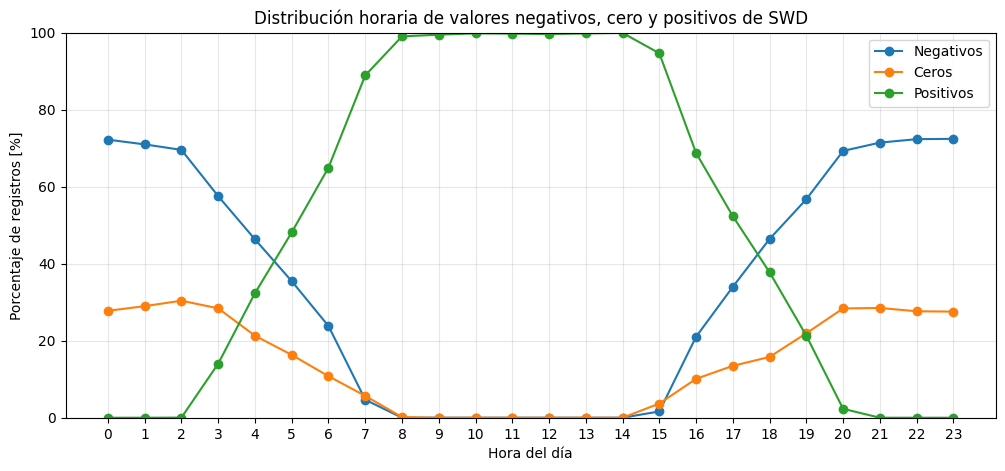

In [28]:
plt.figure(figsize=(12, 5))

plt.plot(tabla_estado_hora_pct.index, tabla_estado_hora_pct.get("Negativo", 0), marker="o", label="Negativos")
plt.plot(tabla_estado_hora_pct.index, tabla_estado_hora_pct.get("Cero", 0), marker="o", label="Ceros")
plt.plot(tabla_estado_hora_pct.index, tabla_estado_hora_pct.get("Positivo", 0), marker="o", label="Positivos")

plt.title("Distribución horaria de valores negativos, cero y positivos de SWD")
plt.xlabel("Hora del día")
plt.ylabel("Porcentaje de registros [%]")
plt.xticks(range(24))
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

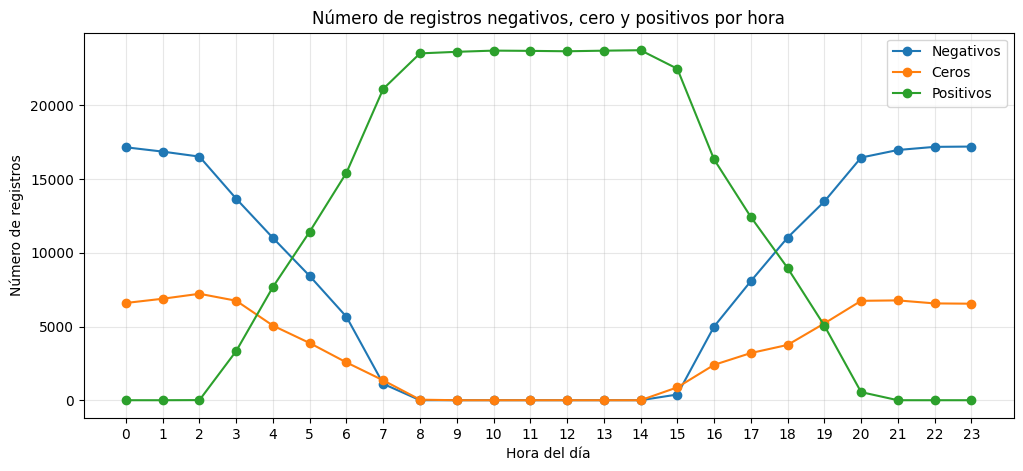

In [29]:
plt.figure(figsize=(12, 5))

plt.plot(tabla_estado_hora.index, tabla_estado_hora.get("Negativo", 0), marker="o", label="Negativos")
plt.plot(tabla_estado_hora.index, tabla_estado_hora.get("Cero", 0), marker="o", label="Ceros")
plt.plot(tabla_estado_hora.index, tabla_estado_hora.get("Positivo", 0), marker="o", label="Positivos")

plt.title("Número de registros negativos, cero y positivos por hora")
plt.xlabel("Hora del día")
plt.ylabel("Número de registros")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

Una parte muy importante de los registros corresponde a horas sin radiación o con radiación casi nula.

### SWD mínimo

Resumen estadístico horario para SWD min:


,count,mean,median,min,max
hour,,,,,
0,23760,-0.868603,-1.0,-3.0,0.0
1,23755,-0.868365,-1.0,-3.0,0.0
2,23760,-0.853998,-1.0,-4.0,3.0
3,23760,0.183207,-1.0,-4.0,51.0
4,23756,9.652004,-1.0,-3.0,183.0
5,23743,37.620520,0.0,-3.0,422.0
6,23659,83.289235,25.0,-3.0,639.0
7,23586,146.513907,82.0,-2.0,848.0
8,23570,214.262707,144.0,-1.0,973.0


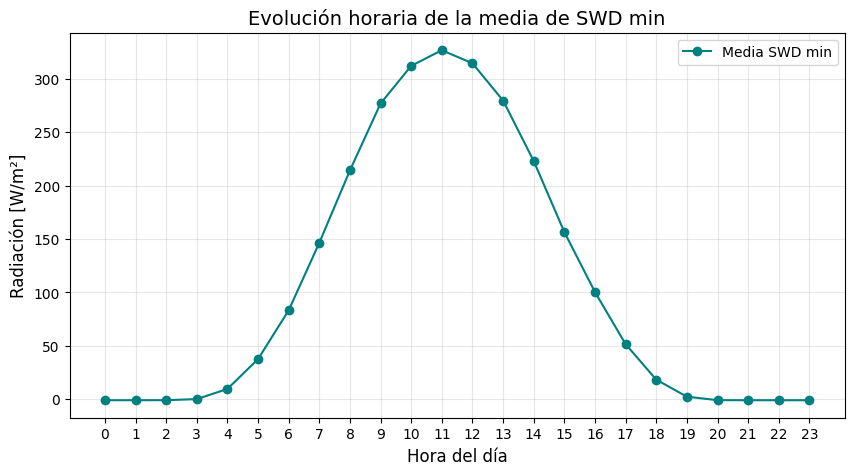

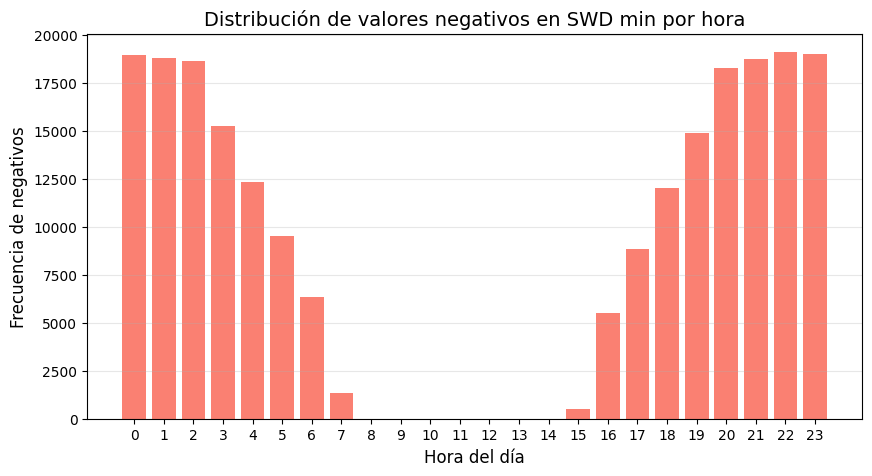

In [30]:
col_swd_min = 'SWD min [W/m**2]'

# 1. Resumen estadístico por hora
resumen_horario_min = (
    df.groupby('hour')[col_swd_min]
    .agg(
        count='count',
        mean='mean',
        median='median',
        min='min',
        max='max'
    )
    .reindex(range(24))
)

print("Resumen estadístico horario para SWD min:")
display(resumen_horario_min)

# 2. Visualización de la media horaria
plt.figure(figsize=(10, 5))
plt.plot(resumen_horario_min.index, resumen_horario_min['mean'], marker='o', color='teal', label='Media SWD min')
plt.title("Evolución horaria de la media de SWD min", fontsize=14)
plt.xlabel("Hora del día", fontsize=12)
plt.ylabel("Radiación [W/m²]", fontsize=12)
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# 3. Análisis de valores negativos por hora
negativos_min_hora = (
    df[df[col_swd_min] < 0]
    .groupby('hour')
    .size()
    .reindex(range(24), fill_value=0)
)

plt.figure(figsize=(10, 5))
plt.bar(negativos_min_hora.index, negativos_min_hora.values, color='salmon')
plt.title("Distribución de valores negativos en SWD min por hora", fontsize=14)
plt.xlabel("Hora del día", fontsize=12)
plt.ylabel("Frecuencia de negativos", fontsize=12)
plt.xticks(range(24))
plt.grid(True, axis='y', alpha=0.3)
plt.show()

Los resultados muestran un comportamiento muy similar a la variable media, pero con niveles ligeramente inferiores, como es de esperar:

- **Perfil horario:** La media de los valores mínimos sigue el ciclo solar, alcanzando su pico entre las 11:00 y las 12:00 (aprox. 326 W/m²).
- **Valores negativos:** Se observa una presencia masiva de valores negativos durante la noche (horas 20:00 a 07:00). Al igual que con la variable principal, estos valores oscilan mayoritariamente entre -1 y -4 W/m², lo que confirma que el ruido instrumental afecta a todo el bloque de variables de radiación de onda corta.

### SWD máximo

Resumen estadístico horario para SWD max:


,count,mean,median,min,max
hour,,,,,
0,23760,-0.674790,-1.0,-3.0,0.0
1,23755,-0.653925,-1.0,-3.0,0.0
2,23760,-0.642761,-1.0,-3.0,3.0
3,23760,0.434680,-1.0,-3.0,54.0
4,23756,10.480216,0.0,-3.0,197.0
5,23743,40.622120,0.0,-3.0,459.0
6,23659,90.939938,26.0,-3.0,675.0
7,23586,164.027983,87.0,-2.0,954.0
8,23570,243.561646,158.0,0.0,1084.0


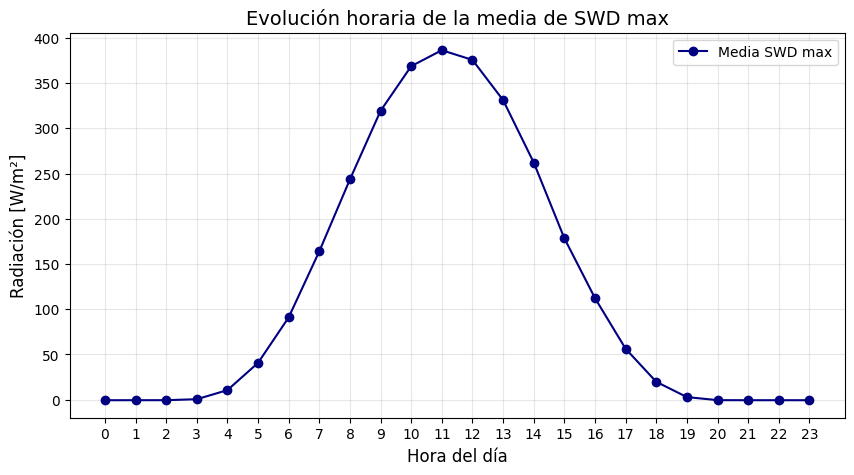

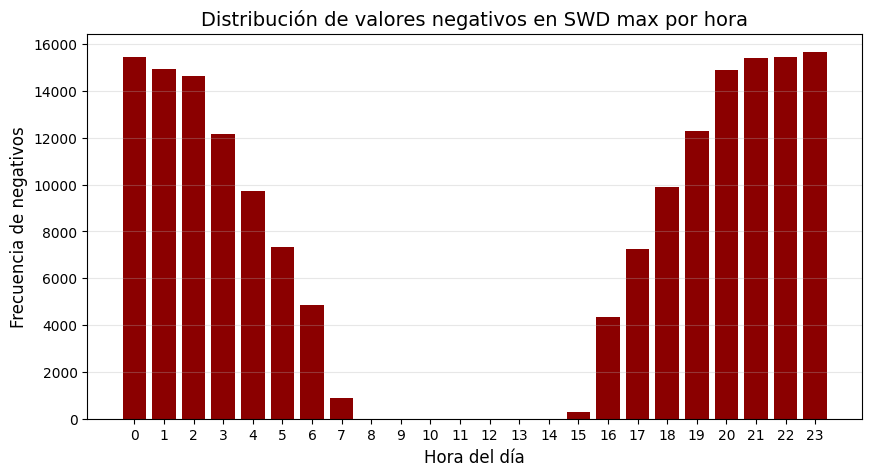

In [31]:
col_swd_max = 'SWD max [W/m**2]'

# 1. Resumen estadístico por hora
resumen_horario_max = (
    df.groupby('hour')[col_swd_max]
    .agg(
        count='count',
        mean='mean',
        median='median',
        min='min',
        max='max'
    )
    .reindex(range(24))
)

print("Resumen estadístico horario para SWD max:")
display(resumen_horario_max)

# 2. Visualización de la media horaria
plt.figure(figsize=(10, 5))
plt.plot(resumen_horario_max.index, resumen_horario_max['mean'], marker='o', color='navy', label='Media SWD max')
plt.title("Evolución horaria de la media de SWD max", fontsize=14)
plt.xlabel("Hora del día", fontsize=12)
plt.ylabel("Radiación [W/m²]", fontsize=12)
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# 3. Análisis de valores negativos por hora
negativos_max_hora = (
    df[df[col_swd_max] < 0]
    .groupby('hour')
    .size()
    .reindex(range(24), fill_value=0)
)

plt.figure(figsize=(10, 5))
plt.bar(negativos_max_hora.index, negativos_max_hora.values, color='darkred')
plt.title("Distribución de valores negativos en SWD max por hora", fontsize=14)
plt.xlabel("Hora del día", fontsize=12)
plt.ylabel("Frecuencia de negativos", fontsize=12)
plt.xticks(range(24))
plt.grid(True, axis='y', alpha=0.3)
plt.show()

- **Distribución horaria:** Al igual que SWD y SWD min, los máximos siguen el ciclo solar, alcanzando su pico medio entre las 11:00 y las 12:00 (aprox. 386 W/m²). El valor máximo absoluto registrado en este bloque es de 1407 W/m².
- **Ruido instrumental:** Se confirman valores negativos durante la noche (20:00 a 07:00), con magnitudes entre -1 y -4 W/m². Esto es consistente con el ruido electrónico observado en las otras componentes de onda corta.

### Desviación típica de SWD

Resumen estadístico horario para SWD std dev:


,count,mean,median,min,max
hour,,,,,
0,23760,0.061044,0.1,0.0,0.2
1,23755,0.060387,0.1,0.0,0.2
2,23760,0.060825,0.1,0.0,0.2
3,23760,0.075926,0.1,0.0,2.6
4,23756,0.250901,0.1,0.0,34.1
5,23743,0.929562,0.1,0.0,87.2
6,23659,2.392350,0.2,0.0,147.4
7,23586,5.458653,0.6,0.0,258.1
8,23570,9.178286,1.1,0.0,305.6


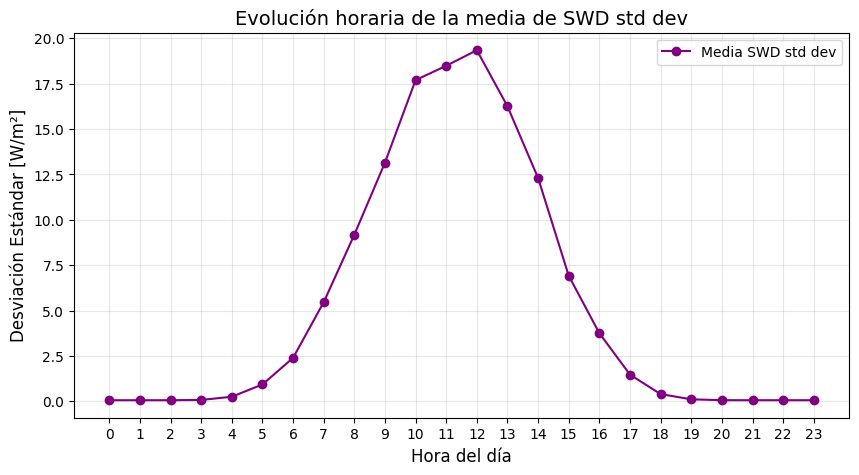

No se detectaron valores negativos en SWD std dev, lo cual es físicamente correcto.


In [32]:
col_swd_std = 'SWD std dev [W/m**2]'

# 1. Resumen estadístico por hora
resumen_horario_std = (
    df.groupby('hour')[col_swd_std]
    .agg(
        count='count',
        mean='mean',
        median='median',
        min='min',
        max='max'
    )
    .reindex(range(24))
)

print("Resumen estadístico horario para SWD std dev:")
display(resumen_horario_std)

# 2. Visualización de la media horaria
plt.figure(figsize=(10, 5))
plt.plot(resumen_horario_std.index, resumen_horario_std['mean'], marker='o', color='purple', label='Media SWD std dev')
plt.title("Evolución horaria de la media de SWD std dev", fontsize=14)
plt.xlabel("Hora del día", fontsize=12)
plt.ylabel("Desviación Estándar [W/m²]", fontsize=12)
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# 3. Comprobación de valores negativos
negativos_std_hora = (
    df[df[col_swd_std] < 0]
    .groupby('hour')
    .size()
    .reindex(range(24), fill_value=0)
)

if negativos_std_hora.sum() > 0:
    plt.figure(figsize=(10, 5))
    plt.bar(negativos_std_hora.index, negativos_std_hora.values, color='orchid')
    plt.title("Distribución de valores negativos en SWD std dev por hora", fontsize=14)
    plt.xlabel("Hora del día", fontsize=12)
    plt.ylabel("Frecuencia de negativos", fontsize=12)
    plt.xticks(range(24))
    plt.grid(True, axis='y', alpha=0.3)
    plt.show()
else:
    print("No se detectaron valores negativos en SWD std dev, lo cual es físicamente correcto.")

- **Coherencia física:** A diferencia de las otras variables de radiación, no se detectaron valores negativos en la desviación estándar, lo cual es físicamente correcto ya que una desviación no puede ser menor que cero.
- **Distribución horaria:** La variabilidad (desviación estándar) aumenta durante las horas del día, alcanzando su punto máximo entre las 11:00 y las 12:00 (media de ~19.3 W/m²). Esto refleja que la fluctuación de la radiación es mayor cuando la intensidad del sol es más alta.
- **Periodo nocturno:** Durante la noche, la desviación estándar es prácticamente nula o muy cercana a 0.1, lo que indica que las lecturas son constantes (aunque sean ruido instrumental).

### Coherencia entre los estadísticos del bloque SWD

Análisis de coherencia sobre 569311 registros válidos:
- Registros que fallan min <= media <= max: 0
- Registros que fallan std dev >= 0: 0


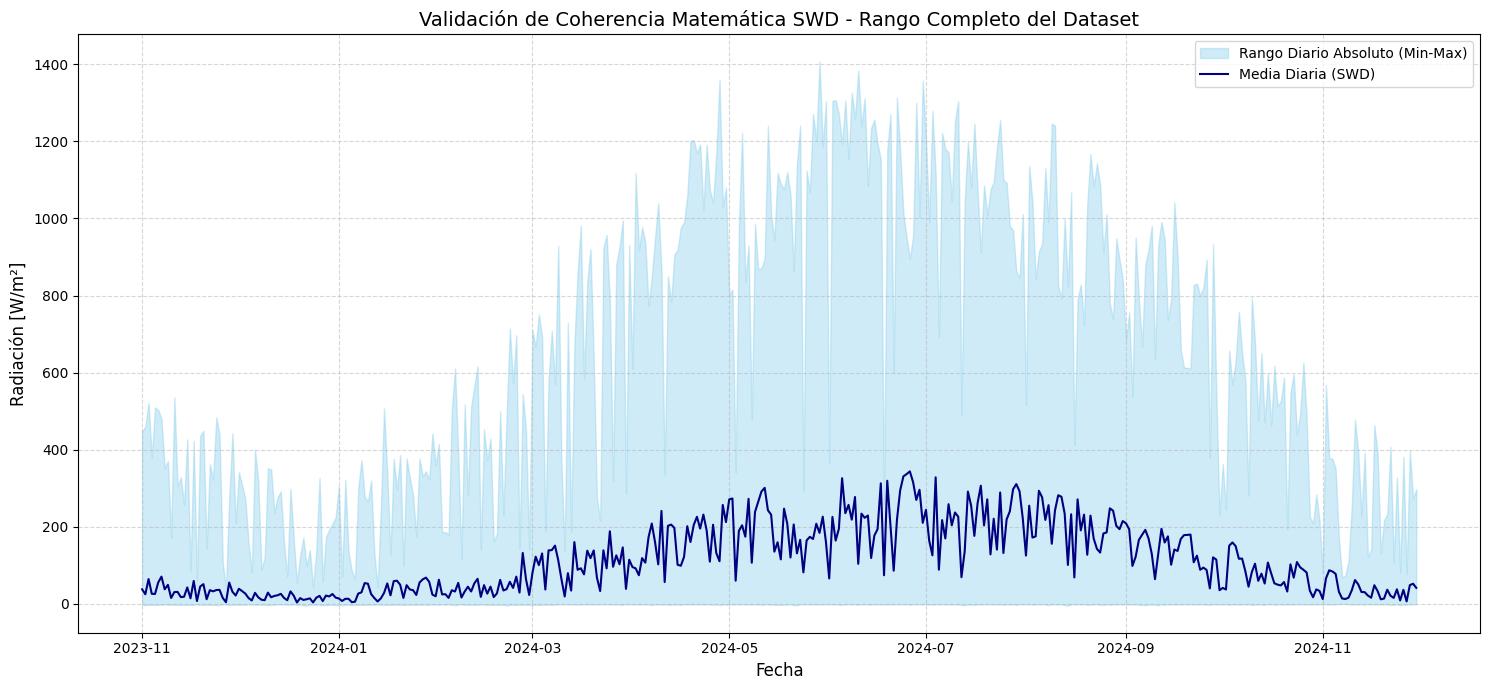


CONCLUSIÓN: Se confirma la coherencia matemática en TODO el dataset.


In [33]:
# 1. Coherencia entre estadísticos en todo el periodo
cols_swd = ['SWD [W/m**2]', 'SWD min [W/m**2]', 'SWD max [W/m**2]', 'SWD std dev [W/m**2]']
df_swd = df[cols_swd].dropna()

# Verificación lógica: min <= mean <= max
violaciones_rango = df_swd[~((df_swd['SWD min [W/m**2]'] <= df_swd['SWD [W/m**2]']) &
                             (df_swd['SWD [W/m**2]'] <= df_swd['SWD max [W/m**2]']))]

# Verificación lógica: std >= 0
violaciones_std = df_swd[df_swd['SWD std dev [W/m**2]'] < 0]

print(f"Análisis de coherencia sobre {len(df_swd)} registros válidos:")
print(f"- Registros que fallan min <= media <= max: {len(violaciones_rango)}")
print(f"- Registros que fallan std dev >= 0: {len(violaciones_std)}")

# 2. Rango diario y media diaria
df_diario = df.groupby('date')[cols_swd].agg({
    'SWD [W/m**2]': 'mean',
    'SWD min [W/m**2]': 'min',
    'SWD max [W/m**2]': 'max'
})

plt.figure(figsize=(15, 7))

# Sombreado del rango absoluto diario
plt.fill_between(df_diario.index,
                 df_diario['SWD min [W/m**2]'],
                 df_diario['SWD max [W/m**2]'],
                 color='skyblue', alpha=0.4, label='Rango Diario Absoluto (Min-Max)')

# Línea de la media diaria
plt.plot(df_diario.index, df_diario['SWD [W/m**2]'], color='navy', lw=1.5, label='Media Diaria (SWD)')

plt.title("Validación de Coherencia Matemática SWD - Rango Completo del Dataset", fontsize=14)
plt.xlabel("Fecha", fontsize=12)
plt.ylabel("Radiación [W/m²]", fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

if len(violaciones_rango) == 0 and len(violaciones_std) == 0:
    print("\nCONCLUSIÓN: Se confirma la coherencia matemática en TODO el dataset.")
else:
    print(f"\nADVERTENCIA: Se han detectado {len(violaciones_rango)} inconsistencias.")

La evolución media horaria de los cuatro estadísticos permite comprobar visualmente que se cumple min ≤ media ≤ max.

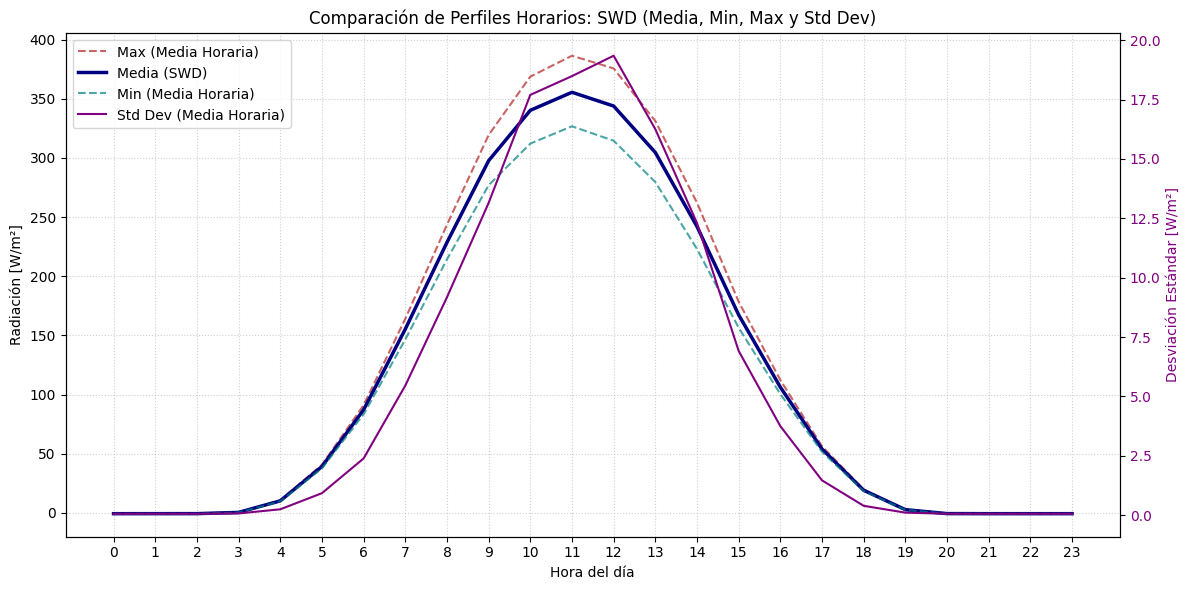

In [34]:
# Medias horarias de los cuatro estadísticos del bloque
perfil_comparativo = df.groupby('hour')[['SWD [W/m**2]', 'SWD min [W/m**2]', 'SWD max [W/m**2]', 'SWD std dev [W/m**2]']].mean()

fig, ax1 = plt.subplots(figsize=(12, 6))

# Eje principal: media, mínimo y máximo
ax1.plot(perfil_comparativo.index, perfil_comparativo['SWD max [W/m**2]'], label='Max (Media Horaria)', color='firebrick', linestyle='--', alpha=0.7)
ax1.plot(perfil_comparativo.index, perfil_comparativo['SWD [W/m**2]'], label='Media (SWD)', color='navy', linewidth=2.5)
ax1.plot(perfil_comparativo.index, perfil_comparativo['SWD min [W/m**2]'], label='Min (Media Horaria)', color='teal', linestyle='--', alpha=0.7)

ax1.set_xlabel('Hora del día')
ax1.set_ylabel('Radiación [W/m²]')
ax1.set_xticks(range(24))
ax1.grid(True, linestyle=':', alpha=0.6)

# Eje secundario para la desviación típica, de menor escala
ax2 = ax1.twinx()
ax2.plot(perfil_comparativo.index, perfil_comparativo['SWD std dev [W/m**2]'], label='Std Dev (Media Horaria)', color='purple', linewidth=1.5)
ax2.set_ylabel('Desviación Estándar [W/m²]', color='purple')
ax2.tick_params(axis='y', labelcolor='purple')

plt.title('Comparación de Perfiles Horarios: SWD (Media, Min, Max y Std Dev)')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
plt.show()

El gráfico muestra una coherencia completa en el bloque SWD:

- **Envolvente lógica:** La curva de la media (azul) se mantiene estrictamente contenida entre el mínimo (verde) y el máximo (rojo) a lo largo de las 24 horas.
- **Variabilidad escalable:** La desviación estándar (púrpura, eje derecho) es casi nula durante la noche y crece proporcionalmente con la intensidad de la radiación diurna, reflejando que a mayor energía hay mayor fluctuación potencial.
- **Ruido nocturno:** El gráfico confirma que los valores negativos ocurren de forma simultánea en la media, el mínimo y el máximo durante las horas sin sol, reforzando la hipótesis del ruido instrumental.

### Distribución mensual del bloque SWD

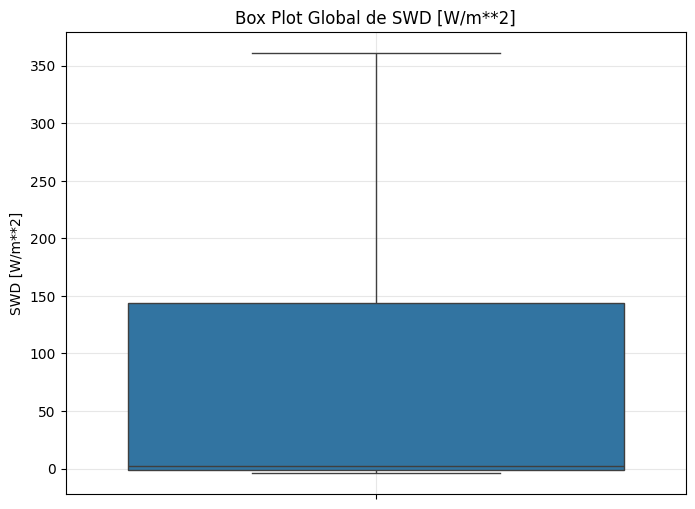

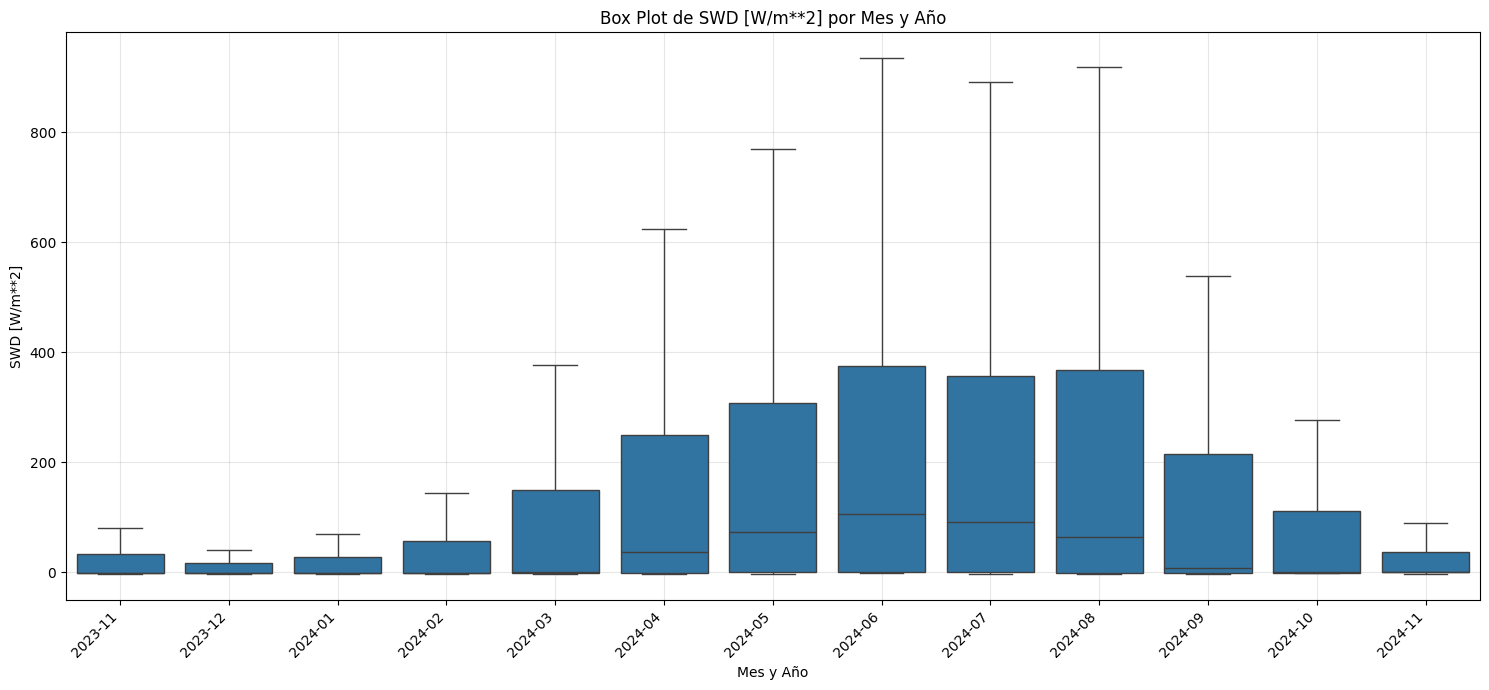

In [35]:
col_swd = "SWD [W/m**2]"

# Box plot global para SWD
plt.figure(figsize=(8, 6))
sns.boxplot(y=df[col_swd], showfliers=False)
plt.title(f"Box Plot Global de {col_swd}")
plt.ylabel(col_swd)
plt.grid(True, alpha=0.3)
plt.show()

# Box plot de SWD por agregación mensual y anual
plt.figure(figsize=(15, 7))
sns.boxplot(data=df, x="year_month", y=col_swd, showfliers=False, order=sorted(df['year_month'].unique()))
plt.title(f"Box Plot de {col_swd} por Mes y Año")
plt.xlabel("Mes y Año")
plt.ylabel(col_swd)
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

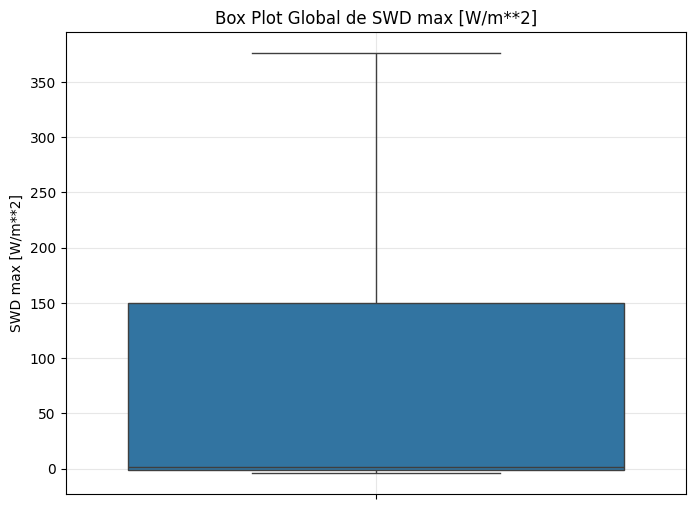

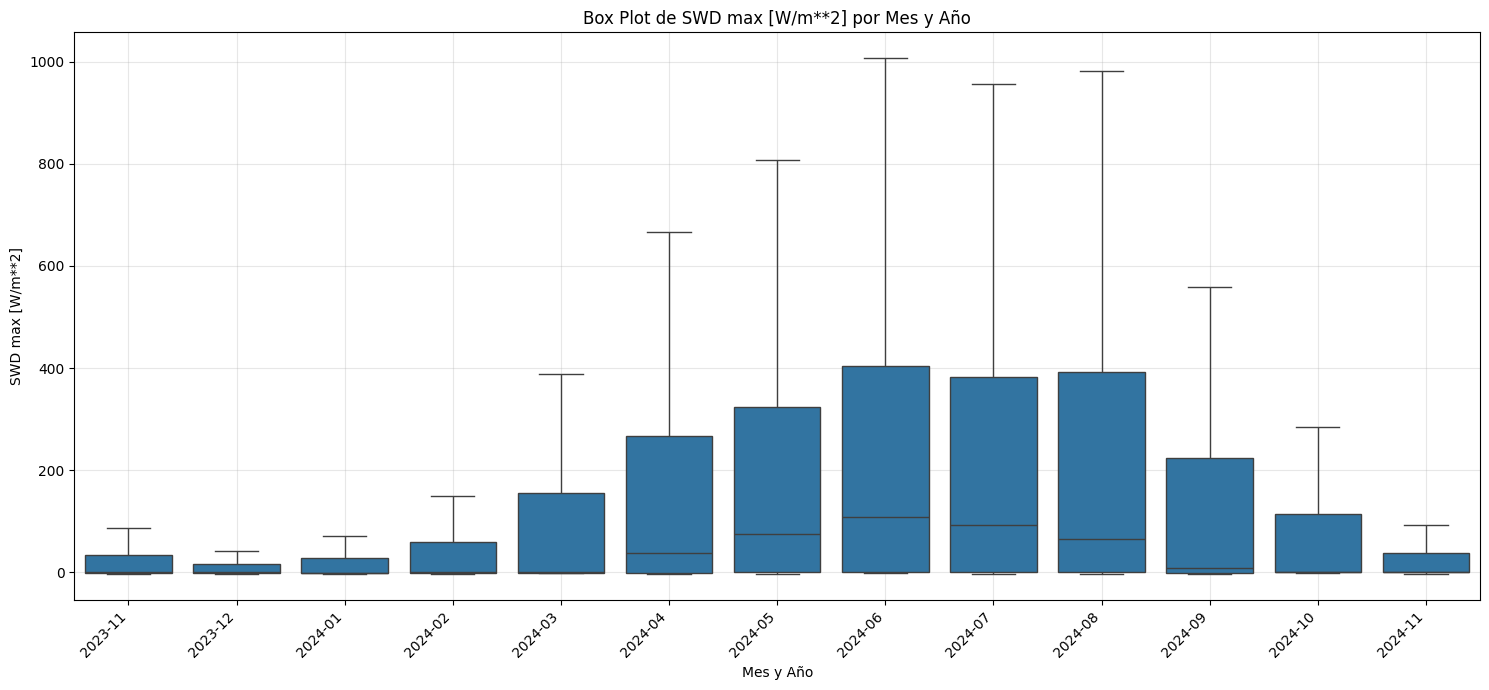

In [36]:
col_swd_max = "SWD max [W/m**2]"

# Box plot global para SWD max
plt.figure(figsize=(8, 6))
sns.boxplot(y=df[col_swd_max], showfliers=False)
plt.title(f"Box Plot Global de {col_swd_max}")
plt.ylabel(col_swd_max)
plt.grid(True, alpha=0.3)
plt.show()

# Box plot de SWD max por agregación mensual y anual
plt.figure(figsize=(15, 7))
sns.boxplot(data=df, x="year_month", y=col_swd_max, showfliers=False, order=sorted(df['year_month'].unique()))
plt.title(f"Box Plot de {col_swd_max} por Mes y Año")
plt.xlabel("Mes y Año")
plt.ylabel(col_swd_max)
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

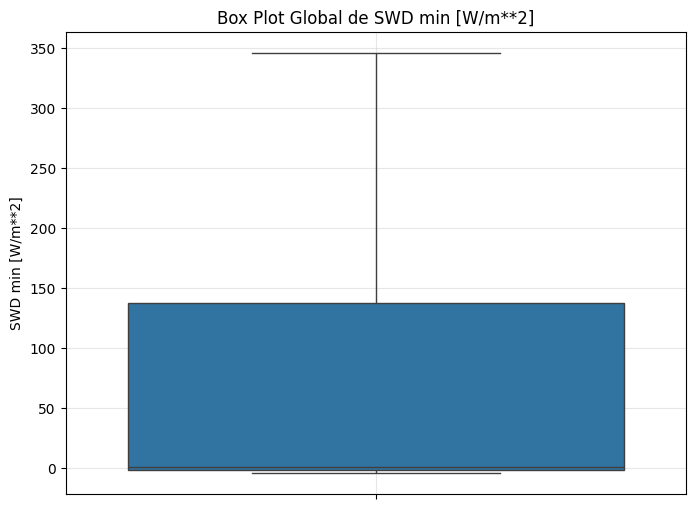

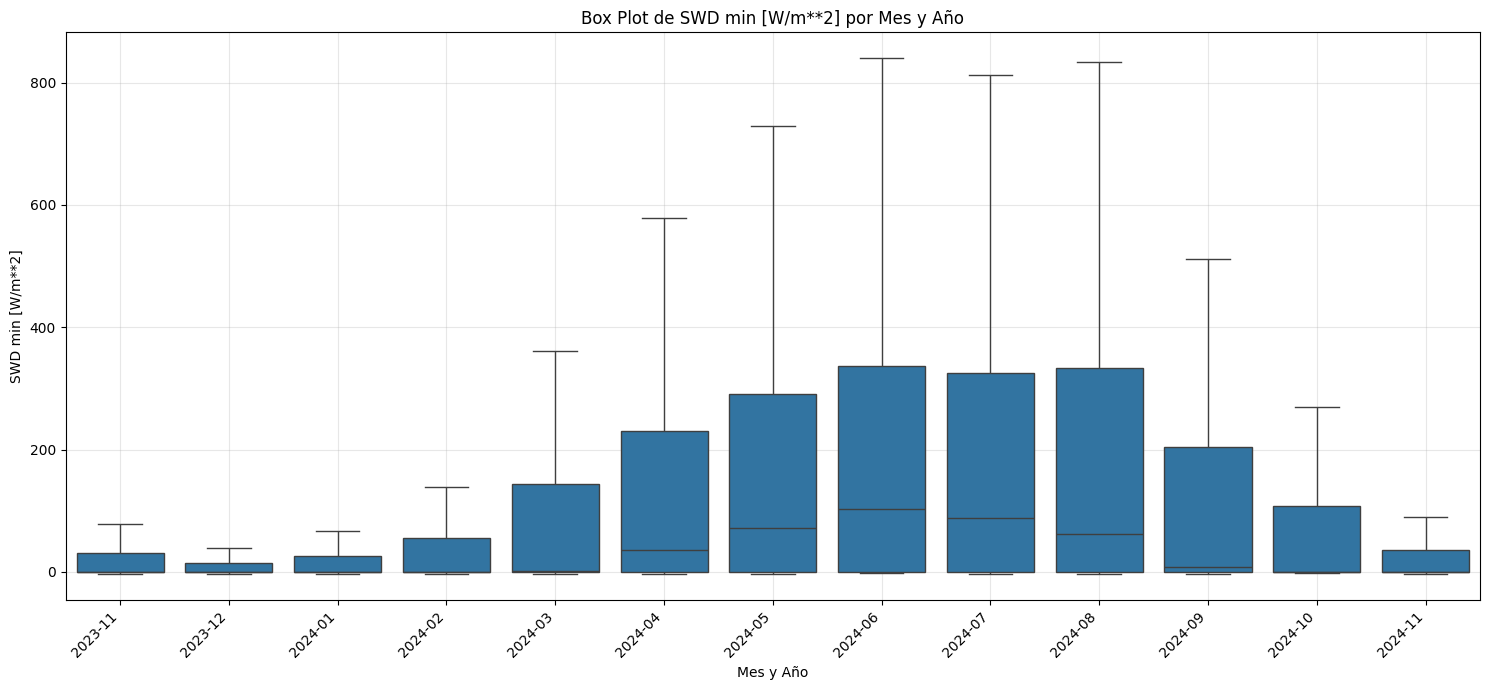

In [37]:
col_swd_min = "SWD min [W/m**2]"

# Box plot global para SWD min
plt.figure(figsize=(8, 6))
sns.boxplot(y=df[col_swd_min], showfliers=False)
plt.title(f"Box Plot Global de {col_swd_min}")
plt.ylabel(col_swd_min)
plt.grid(True, alpha=0.3)
plt.show()

# Box plot de SWD min por agregación mensual y anual
plt.figure(figsize=(15, 7))
sns.boxplot(data=df, x="year_month", y=col_swd_min, showfliers=False, order=sorted(df['year_month'].unique()))
plt.title(f"Box Plot de {col_swd_min} por Mes y Año")
plt.xlabel("Mes y Año")
plt.ylabel(col_swd_min)
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

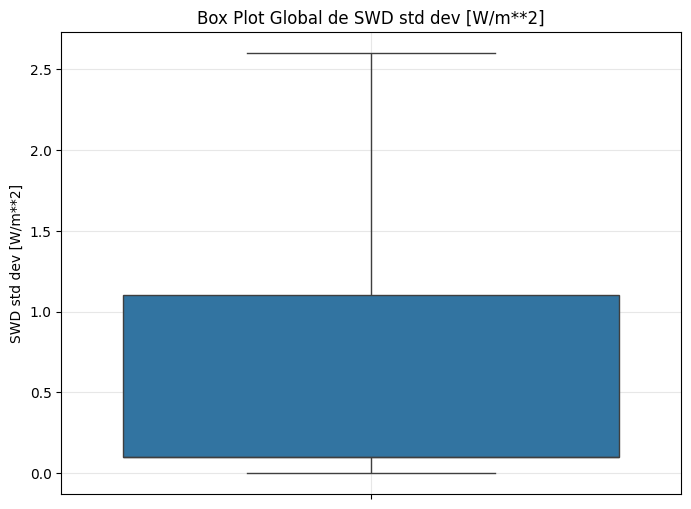

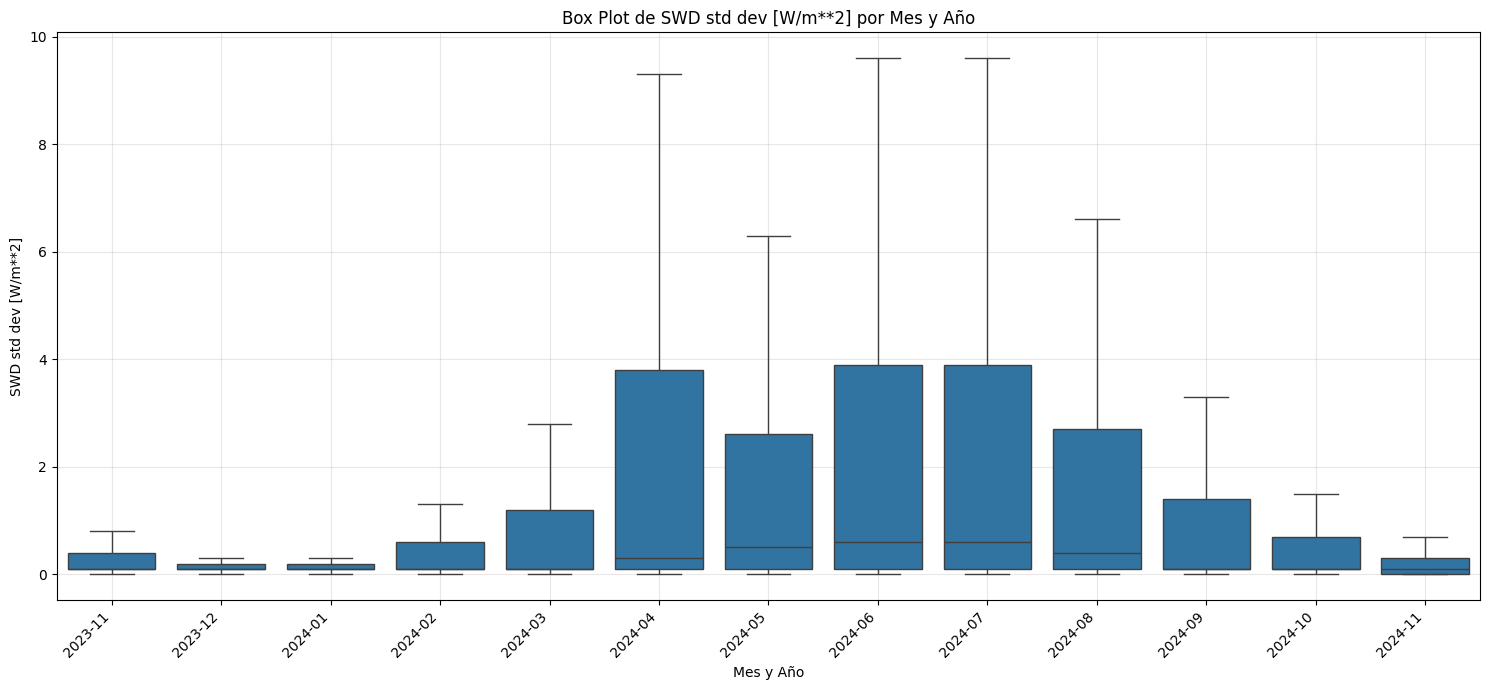

In [38]:
col_swd_std = "SWD std dev [W/m**2]"

# Box plot global para SWD std dev
plt.figure(figsize=(8, 6))
sns.boxplot(y=df[col_swd_std], showfliers=False)
plt.title(f"Box Plot Global de {col_swd_std}")
plt.ylabel(col_swd_std)
plt.grid(True, alpha=0.3)
plt.show()

# Box plot de SWD std dev por agregación mensual y anual
plt.figure(figsize=(15, 7))
sns.boxplot(data=df, x="year_month", y=col_swd_std, showfliers=False, order=sorted(df['year_month'].unique()))
plt.title(f"Box Plot de {col_swd_std} por Mes y Año")
plt.xlabel("Mes y Año")
plt.ylabel(col_swd_std)
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Radiación directa normal (DIR)

In [39]:
col_DIR = "DIR [W/m**2]"

resumen_horario_DIR = (
    df.groupby("hour")[col_DIR]
    .agg(
        count="count",
        mean="mean",
        median="median",
        min="min",
        max="max"
    )
    .reindex(range(24))
)

resumen_horario_DIR

,count,mean,median,min,max
hour,,,,,
0,23340,0.401671,0.0,-1.0,2.0
1,23335,0.397514,0.0,-1.0,2.0
2,23340,0.391731,0.0,-2.0,2.0
3,23338,1.379081,0.0,-2.0,173.0
4,23338,19.914346,1.0,-1.0,541.0
5,23330,61.880069,1.0,-2.0,687.0
6,23277,112.508914,1.0,-1.0,809.0
7,23070,161.314824,1.0,-1.0,855.0
8,23140,209.000994,3.0,-2.0,909.0


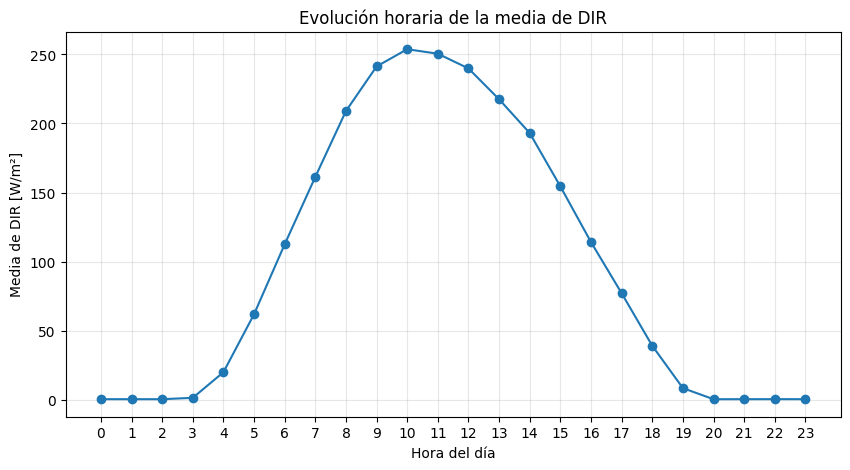

In [40]:
plt.figure(figsize=(10, 5))

plt.plot(
    resumen_horario_DIR.index,
    resumen_horario_DIR["mean"],
    marker="o"
)

plt.title("Evolución horaria de la media de DIR")
plt.xlabel("Hora del día")
plt.ylabel("Media de DIR [W/m²]")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)

plt.show()

In [41]:
negativos_por_hora_DIR = (
    df[df[col_DIR] < 0]
    .groupby("hour")
    .size()
    .reindex(range(24), fill_value=0)
)

negativos_por_hora_DIR

,0
hour,
0,253
1,174
2,196
3,152
4,115
5,143
6,195
7,208
8,185


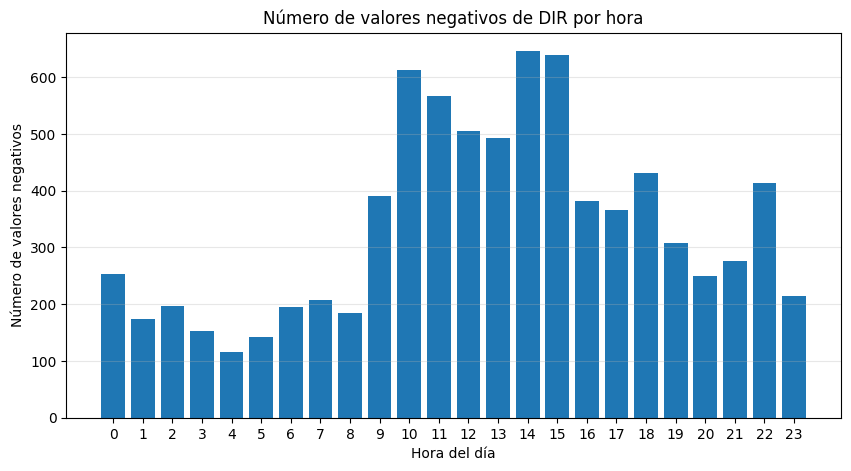

In [42]:
plt.figure(figsize=(10, 5))

plt.bar(
    negativos_por_hora_DIR.index,
    negativos_por_hora_DIR.values
)

plt.title("Número de valores negativos de DIR por hora")
plt.xlabel("Hora del día")
plt.ylabel("Número de valores negativos")
plt.xticks(range(24))
plt.grid(True, axis="y", alpha=0.3)

plt.show()

In [43]:
total_por_hora = (
    df.groupby("hour")
    .size()
    .reindex(range(24), fill_value=0)
)

porcentaje_negativos_por_hora_DIR = (
    negativos_por_hora_DIR / total_por_hora * 100
).fillna(0)

porcentaje_negativos_por_hora_DIR

,0
hour,
0,1.064815
1,0.732323
2,0.824916
3,0.639731
4,0.484007
5,0.601852
6,0.820707
7,0.875421
8,0.778620


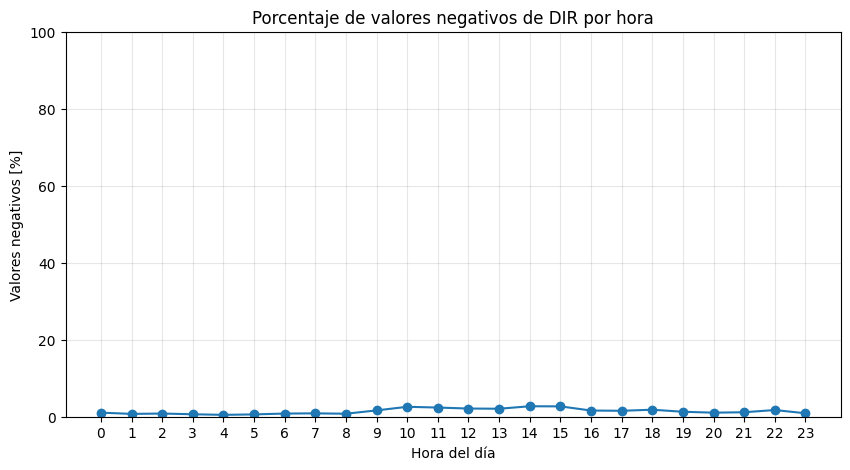

In [44]:
plt.figure(figsize=(10, 5))

plt.plot(
    porcentaje_negativos_por_hora_DIR.index,
    porcentaje_negativos_por_hora_DIR.values,
    marker="o"
)

plt.title("Porcentaje de valores negativos de DIR por hora")
plt.xlabel("Hora del día")
plt.ylabel("Valores negativos [%]")
plt.xticks(range(24))
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)

plt.show()

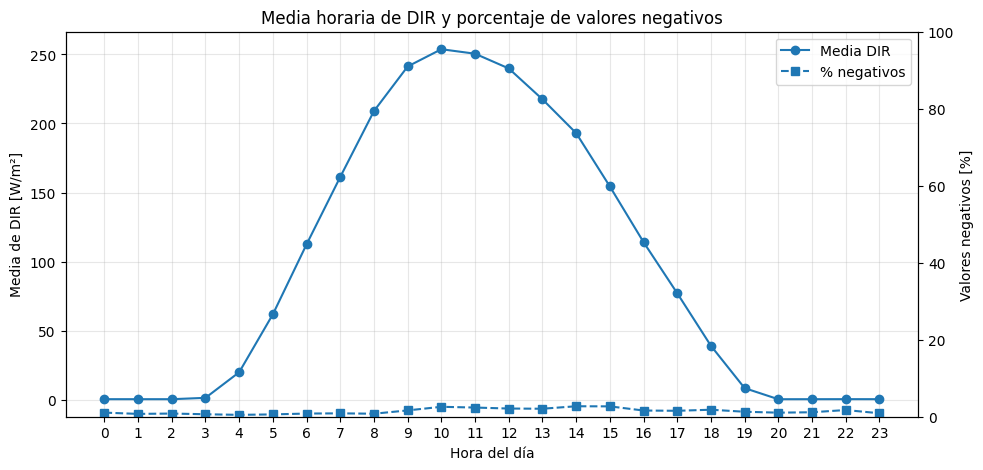

In [45]:
fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.plot(
    resumen_horario_DIR.index,
    resumen_horario_DIR["mean"],
    marker="o",
    label="Media DIR"
)

ax1.set_xlabel("Hora del día")
ax1.set_ylabel("Media de DIR [W/m²]")
ax1.set_xticks(range(24))
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()

ax2.plot(
    porcentaje_negativos_por_hora_DIR.index,
    porcentaje_negativos_por_hora_DIR.values,
    marker="s",
    linestyle="--",
    label="% negativos"
)

ax2.set_ylabel("Valores negativos [%]")
ax2.set_ylim(0, 100)

plt.title("Media horaria de DIR y porcentaje de valores negativos")

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines_1 + lines_2,
    labels_1 + labels_2,
    loc="upper right"
)

plt.show()

In [46]:
col_DIR = "DIR [W/m**2]"

df["estado_DIR"] = np.select(
    [
        df[col_DIR] < 0,
        df[col_DIR] == 0,
        df[col_DIR] > 0
    ],
    [
        "Negativo",
        "Cero",
        "Positivo"
    ],
    default="Missing"
)

In [47]:
tabla_estado_hora_DIR = (
    df.groupby(["hour", "estado_DIR"])
    .size()
    .unstack(fill_value=0)
    .reindex(range(24), fill_value=0)
)

tabla_estado_hora_DIR

estado_DIR,Cero,Missing,Negativo,Positivo
hour,,,,
0,13822,420,253,9265
1,14079,425,174,9082
2,14068,420,196,9076
3,13345,422,152,9841
4,10118,422,115,13105
5,8137,430,143,15050
6,6039,483,195,17043
7,4705,690,208,18157
8,3711,620,185,19244


In [48]:
tabla_estado_hora_pct_DIR = (
    tabla_estado_hora_DIR
    .div(tabla_estado_hora_DIR.sum(axis=1), axis=0)
    * 100
)

tabla_estado_hora_pct_DIR

estado_DIR,Cero,Missing,Negativo,Positivo
hour,,,,
0,58.173401,1.767677,1.064815,38.994108
1,59.255051,1.788721,0.732323,38.223906
2,59.208754,1.767677,0.824916,38.198653
3,56.165825,1.776094,0.639731,41.418350
4,42.584175,1.776094,0.484007,55.155724
5,34.246633,1.809764,0.601852,63.341751
6,25.416667,2.032828,0.820707,71.729798
7,19.802189,2.904040,0.875421,76.418350
8,15.618687,2.609428,0.778620,80.993266


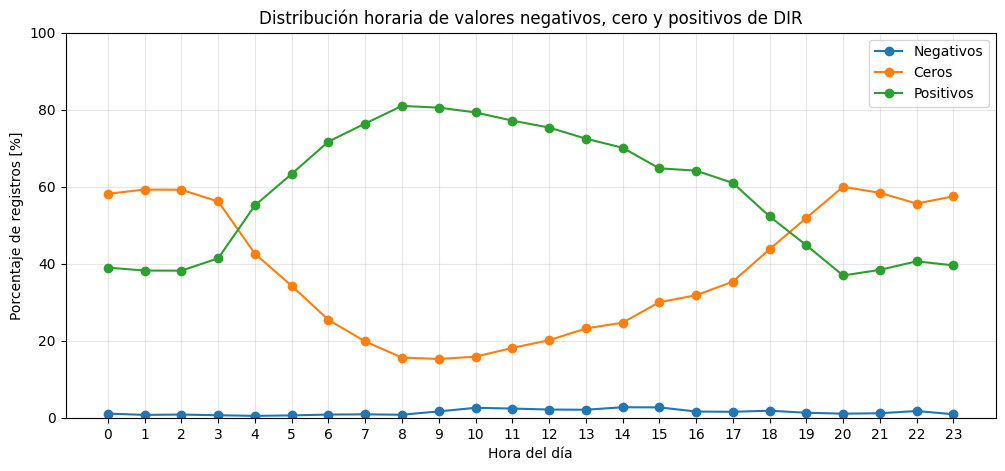

In [49]:
plt.figure(figsize=(12, 5))

plt.plot(tabla_estado_hora_pct_DIR.index, tabla_estado_hora_pct_DIR.get("Negativo", 0), marker="o", label="Negativos")
plt.plot(tabla_estado_hora_pct_DIR.index, tabla_estado_hora_pct_DIR.get("Cero", 0), marker="o", label="Ceros")
plt.plot(tabla_estado_hora_pct_DIR.index, tabla_estado_hora_pct_DIR.get("Positivo", 0), marker="o", label="Positivos")

plt.title("Distribución horaria de valores negativos, cero y positivos de DIR")
plt.xlabel("Hora del día")
plt.ylabel("Porcentaje de registros [%]")
plt.xticks(range(24))
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

La variable `DIR [W/m²]`, correspondiente a la irradiancia directa, presenta una distribución fuertemente asimétrica hacia la derecha, caracterizada por una elevada concentración de valores nulos o muy próximos a cero y una cola larga hacia valores elevados. Esta estructura se observa claramente en el histograma, donde la mayor parte de las observaciones se acumulan en los primeros intervalos, mientras que únicamente una proporción reducida de registros alcanza valores altos de irradiancia directa. La media de la variable se sitúa en 98,01 W/m², mientras que la mediana es de solo 1 W/m², lo que confirma la existencia de una distribución muy desequilibrada y dominada por periodos de baja o nula radiación directa.

Desde el punto de vista estadístico, la variable presenta un mínimo de -4 W/m² y un máximo de 969 W/m². El primer cuartil es igual a 0 W/m², la mediana es 1 W/m² y el tercer cuartil únicamente alcanza 3 W/m², mientras que el percentil 95 asciende hasta 712 W/m². Esta diferencia entre los cuantiles centrales y los valores altos refleja que la irradiancia directa permanece en niveles muy bajos durante una parte importante del periodo analizado, pero puede alcanzar valores elevados en momentos concretos del día, especialmente bajo condiciones de cielo despejado y elevada incidencia solar.

En cuanto a los valores más frecuentes, se observa que el valor 0 representa aproximadamente el 38,0 % de los registros, seguido del valor 1 W/m², con un 31,2 %. Esto implica que cerca de siete de cada diez observaciones se concentran únicamente en los valores 0 y 1 W/m². Este comportamiento es coherente con la naturaleza de la radiación directa, ya que durante la noche, en condiciones de nubosidad o en momentos de baja elevación solar, la componente directa puede ser nula o muy reducida.

La variable presenta también 8.112 valores negativos, lo que supone aproximadamente el 1,4 % del total. Estos valores negativos son de baja magnitud, con un mínimo de -4 W/m², y se concentran principalmente en valores próximos a cero, especialmente en -1 W/m². Desde un punto de vista físico, la irradiancia directa no debería adoptar valores negativos, por lo que estas observaciones pueden interpretarse como pequeñas desviaciones instrumentales alrededor del cero, posiblemente asociadas a ruido de medición, calibración del sensor o redondeo en situaciones de irradiancia muy baja. Por tanto, no parecen representar errores extremos, sino valores residuales cercanos al límite inferior físico de la variable.

El análisis horario muestra un patrón diario coherente con el ciclo solar. La media de `DIR` aumenta progresivamente desde las primeras horas de la mañana, alcanza sus valores máximos en las horas centrales del día y desciende posteriormente durante la tarde. Este comportamiento confirma que la variable recoge adecuadamente la dinámica esperada de la irradiancia directa. Los valores positivos predominan durante las horas diurnas, especialmente entre la mañana y primeras horas de la tarde, mientras que los valores cero son más frecuentes durante la noche, el amanecer y el atardecer. No obstante, se siguen observando ceros durante algunas horas diurnas, lo cual puede estar relacionado con condiciones de nubosidad o ausencia de radiación directa pese a existir radiación solar global.

Respecto a los valores negativos, su presencia es reducida en términos porcentuales y se mantiene en niveles bajos a lo largo del día. Aunque aparecen repartidos en distintas franjas horarias, su magnitud es muy pequeña, por lo que se consideran compatibles con ruido instrumental alrededor del cero. En fases posteriores de preprocesamiento, una posible decisión razonable sería truncar estos valores negativos a cero, respetando así la restricción física de no negatividad de la irradiancia solar.

Por último, `DIR` presenta 12.300 valores ausentes, equivalentes aproximadamente al 2,2 % del total de registros. Aunque este porcentaje no es excesivamente elevado, resulta superior al observado en otras variables como `SWD`, por lo que será necesario analizar posteriormente si estos valores perdidos aparecen de forma aislada o si comparten patrón temporal con otras variables meteorológicas o radiométricas. Por este motivo, el tratamiento definitivo de los valores ausentes se abordará dentro del análisis conjunto de completitud del dataset.

### DIR mínimo

Resumen estadístico horario para DIR min:


,count,mean,median,min,max
hour,,,,,
0,23340,0.234919,0.0,-2.0,2.0
1,23335,0.236126,0.0,-1.0,2.0
2,23340,0.225107,0.0,-3.0,2.0
3,23338,1.140629,0.0,-2.0,170.0
4,23338,18.363313,0.0,-1.0,539.0
5,23330,57.531933,1.0,-2.0,685.0
6,23277,103.856339,1.0,-2.0,807.0
7,23070,145.135501,1.0,-1.0,853.0
8,23140,186.132455,1.0,-2.0,906.0


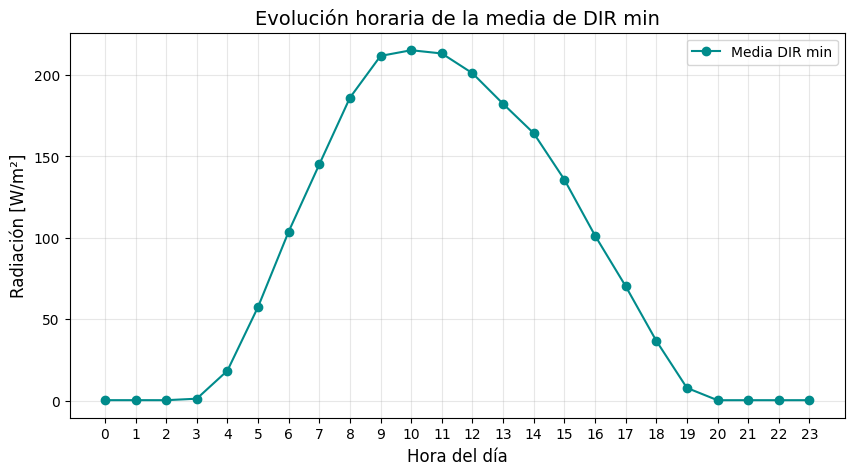

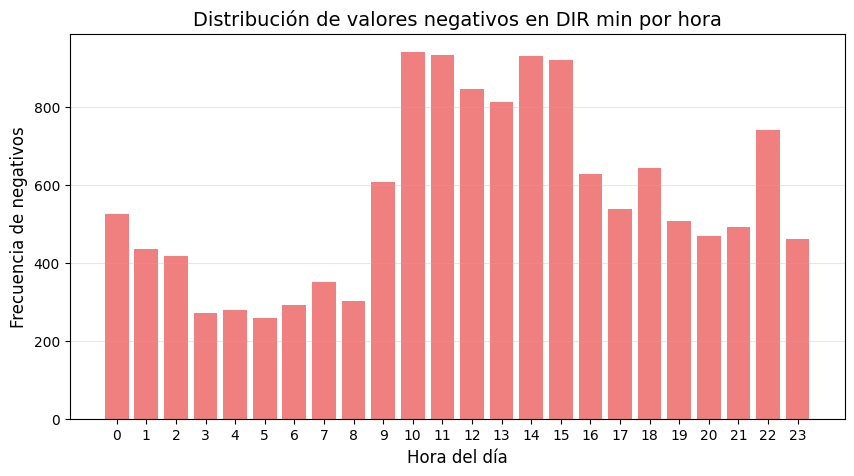

In [50]:
col_dir_min = 'DIR min [W/m**2]'

# 1. Resumen estadístico por hora
resumen_horario_dir_min = (
    df.groupby('hour')[col_dir_min]
    .agg(
        count='count',
        mean='mean',
        median='median',
        min='min',
        max='max'
    )
    .reindex(range(24))
)

print("Resumen estadístico horario para DIR min:")
display(resumen_horario_dir_min)

# 2. Visualización de la media horaria
plt.figure(figsize=(10, 5))
plt.plot(resumen_horario_dir_min.index, resumen_horario_dir_min['mean'], marker='o', color='darkcyan', label='Media DIR min')
plt.title("Evolución horaria de la media de DIR min", fontsize=14)
plt.xlabel("Hora del día", fontsize=12)
plt.ylabel("Radiación [W/m²]", fontsize=12)
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# 3. Análisis de valores negativos por hora
negativos_dir_min_hora = (
    df[df[col_dir_min] < 0]
    .groupby('hour')
    .size()
    .reindex(range(24), fill_value=0)
)

plt.figure(figsize=(10, 5))
plt.bar(negativos_dir_min_hora.index, negativos_dir_min_hora.values, color='lightcoral')
plt.title("Distribución de valores negativos en DIR min por hora", fontsize=14)
plt.xlabel("Hora del día", fontsize=12)
plt.ylabel("Frecuencia de negativos", fontsize=12)
plt.xticks(range(24))
plt.grid(True, axis='y', alpha=0.3)
plt.show()

Tras analizar la componente mínima de la radiación directa (DIR min), se observan patrones muy alineados con el resto del bloque de radiación:

1.  **Ciclo Solar Coherente:** La media de los valores mínimos comienza a despegar a partir de la hora 4-5, alcanzando su punto máximo en las horas centrales del día (aprox. 11:00-12:00), lo que valida la sensibilidad del sensor a la radiación directa incluso en sus registros mínimos.
2.  **Persistencia del Ruido Nocturno:** Se detecta una presencia constante de valores negativos durante las horas sin sol (especialmente entre las 20:00 y las 07:00). Al igual que en SWD, estos valores suelen ser de pequeña magnitud (entre -1 y -4 W/m²).

### DIR máximo

Resumen estadístico horario para DIR max:


,count,mean,median,min,max
hour,,,,,
0,23340,0.527207,1.0,-1.0,2.0
1,23335,0.511335,0.0,-1.0,2.0
2,23340,0.514439,0.0,-2.0,2.0
3,23338,1.591053,1.0,-2.0,176.0
4,23338,21.408004,1.0,-1.0,543.0
5,23330,66.181783,1.0,-2.0,714.0
6,23277,121.346995,1.0,-1.0,810.0
7,23070,177.300347,1.0,-1.0,865.0
8,23140,232.765341,4.0,-1.0,914.0


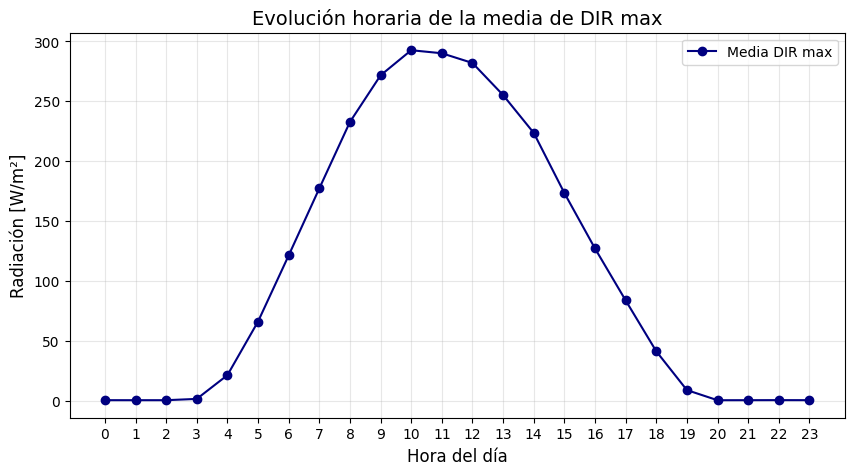

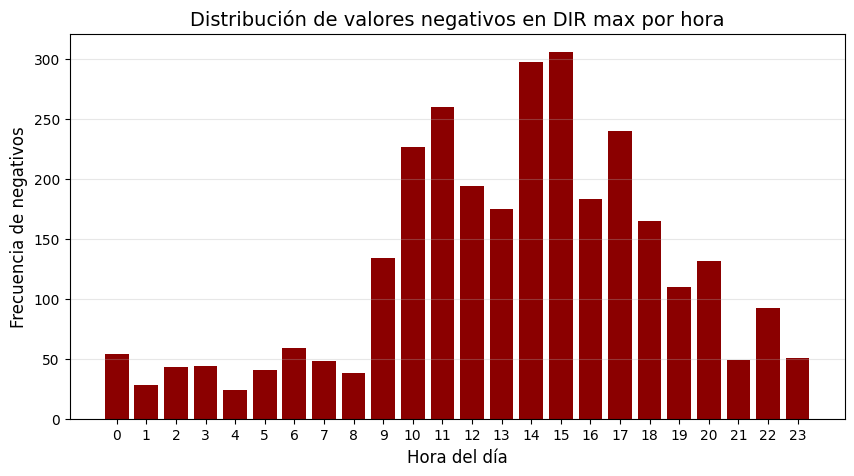

In [51]:
col_dir_max = 'DIR max [W/m**2]'

# 1. Resumen estadístico por hora
resumen_horario_dir_max = (
    df.groupby('hour')[col_dir_max]
    .agg(
        count='count',
        mean='mean',
        median='median',
        min='min',
        max='max'
    )
    .reindex(range(24))
)

print("Resumen estadístico horario para DIR max:")
display(resumen_horario_dir_max)

# 2. Visualización de la media horaria
plt.figure(figsize=(10, 5))
plt.plot(resumen_horario_dir_max.index, resumen_horario_dir_max['mean'], marker='o', color='navy', label='Media DIR max')
plt.title("Evolución horaria de la media de DIR max", fontsize=14)
plt.xlabel("Hora del día", fontsize=12)
plt.ylabel("Radiación [W/m²]", fontsize=12)
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# 3. Análisis de valores negativos por hora
negativos_dir_max_hora = (
    df[df[col_dir_max] < 0]
    .groupby('hour')
    .size()
    .reindex(range(24), fill_value=0)
)

plt.figure(figsize=(10, 5))
plt.bar(negativos_dir_max_hora.index, negativos_dir_max_hora.values, color='darkred')
plt.title("Distribución de valores negativos en DIR max por hora", fontsize=14)
plt.xlabel("Hora del día", fontsize=12)
plt.ylabel("Frecuencia de negativos", fontsize=12)
plt.xticks(range(24))
plt.grid(True, axis='y', alpha=0.3)
plt.show()

### Desviación típica de DIR

Resumen estadístico horario para DIR std dev:


,count,mean,median,min,max
hour,,,,,
0,23340,0.071885,0.1,0.0,0.2
1,23335,0.071789,0.1,0.0,0.2
2,23340,0.071782,0.1,0.0,0.8
3,23338,0.125443,0.1,0.0,24.3
4,23338,0.930080,0.1,0.0,171.6
5,23330,2.702340,0.1,0.0,277.6
6,23277,5.516076,0.1,0.0,310.3
7,23070,10.088288,0.1,0.0,412.4
8,23140,14.747666,0.4,0.0,415.8


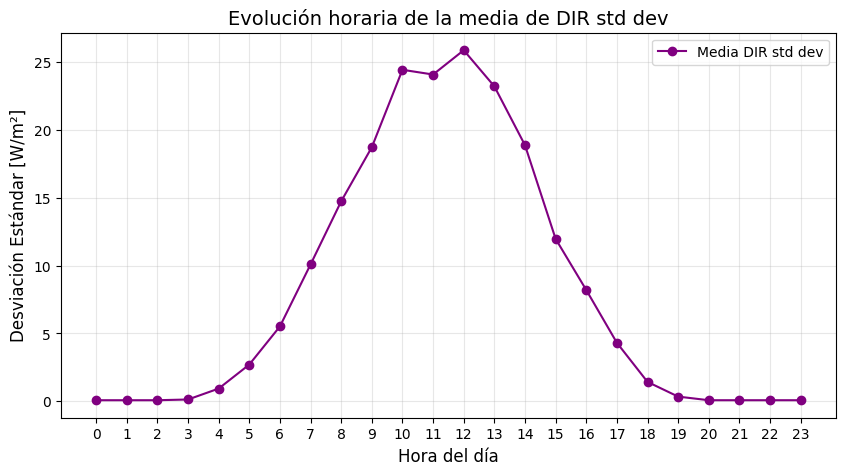

In [52]:
col_dir_std = 'DIR std dev [W/m**2]'

# 1. Resumen estadístico por hora
resumen_horario_dir_std = (
    df.groupby('hour')[col_dir_std]
    .agg(
        count='count',
        mean='mean',
        median='median',
        min='min',
        max='max'
    )
    .reindex(range(24))
)

print("Resumen estadístico horario para DIR std dev:")
display(resumen_horario_dir_std)

# 2. Visualización de la media horaria
plt.figure(figsize=(10, 5))
plt.plot(resumen_horario_dir_std.index, resumen_horario_dir_std['mean'], marker='o', color='purple', label='Media DIR std dev')
plt.title("Evolución horaria de la media de DIR std dev", fontsize=14)
plt.xlabel("Hora del día", fontsize=12)
plt.ylabel("Desviación Estándar [W/m²]", fontsize=12)
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

### Coherencia entre los estadísticos del bloque DIR

Registros analizados: 557940
Violaciones de la lógica min <= media <= max: 0


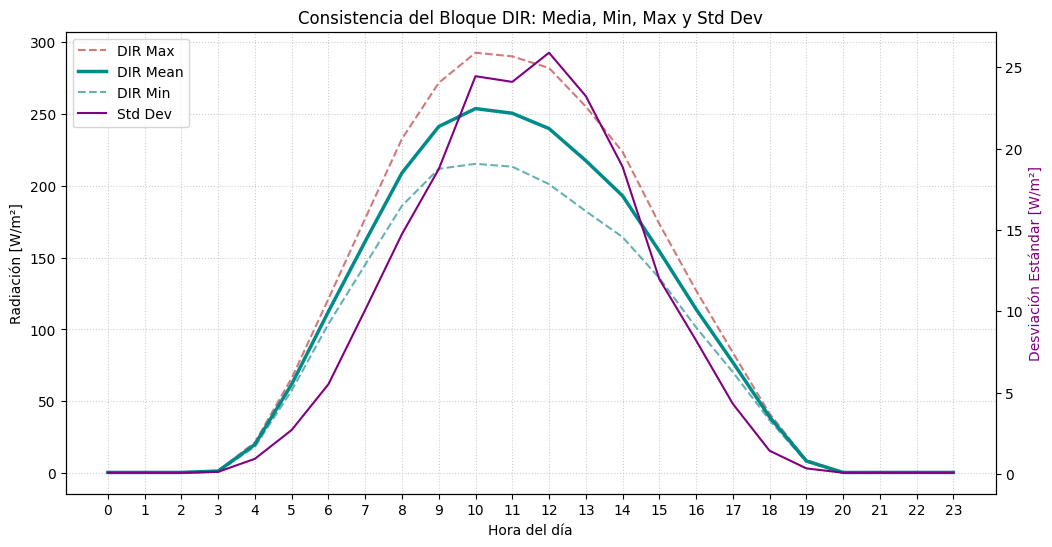

In [53]:
# 1. Validación de rangos lógicos: min <= mean <= max
cols_dir = ['DIR [W/m**2]', 'DIR min [W/m**2]', 'DIR max [W/m**2]', 'DIR std dev [W/m**2]']
df_dir_valid = df[cols_dir].dropna()

violaciones_dir = df_dir_valid[~((df_dir_valid['DIR min [W/m**2]'] <= df_dir_valid['DIR [W/m**2]']) &
                                 (df_dir_valid['DIR [W/m**2]'] <= df_dir_valid['DIR max [W/m**2]']))]

print(f"Registros analizados: {len(df_dir_valid)}")
print(f"Violaciones de la lógica min <= media <= max: {len(violaciones_dir)}")

# 2. Gráfico comparativo de perfiles horarios
perfil_dir = df.groupby('hour')[cols_dir].mean()

fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.plot(perfil_dir.index, perfil_dir['DIR max [W/m**2]'], label='DIR Max', color='firebrick', linestyle='--', alpha=0.6)
ax1.plot(perfil_dir.index, perfil_dir['DIR [W/m**2]'], label='DIR Mean', color='darkcyan', linewidth=2.5)
ax1.plot(perfil_dir.index, perfil_dir['DIR min [W/m**2]'], label='DIR Min', color='teal', linestyle='--', alpha=0.6)

ax1.set_xlabel('Hora del día')
ax1.set_ylabel('Radiación [W/m²]')
ax1.set_xticks(range(24))
ax1.grid(True, linestyle=':', alpha=0.6)

ax2 = ax1.twinx()
ax2.plot(perfil_dir.index, perfil_dir['DIR std dev [W/m**2]'], label='Std Dev', color='purple', linewidth=1.5)
ax2.set_ylabel('Desviación Estándar [W/m²]', color='purple')

plt.title('Consistencia del Bloque DIR: Media, Min, Max y Std Dev')
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')
plt.show()

## 6. Radiación difusa (DIF)

Variable objetivo del trabajo.

In [54]:
resumen_horario_DIF = (
    df.groupby("hour")["DIF [W/m**2]"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        min="min",
        max="max"
    )
    .reindex(range(24))
)

resumen_horario_DIF

,count,mean,median,min,max
hour,,,,,
0,23340,-0.866495,-1.0,-3.0,0.0
1,23335,-0.868995,-1.0,-3.0,0.0
2,23340,-0.873265,-1.0,-4.0,2.0
3,23336,0.151868,-1.0,-4.0,43.0
4,23319,7.740984,-1.0,-3.0,154.0
5,23319,26.138642,0.0,-3.0,230.0
6,23314,52.777044,27.0,-3.0,348.0
7,23247,89.423237,67.0,-2.0,467.0
8,23213,129.627666,100.0,-1.0,649.0


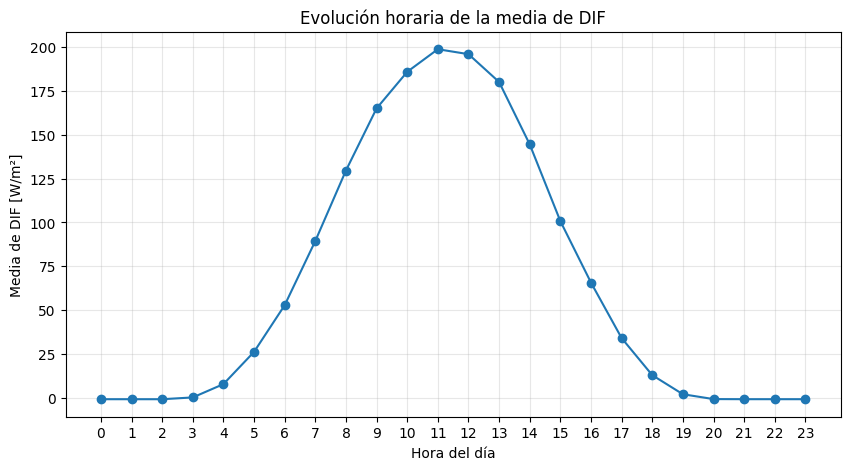

In [55]:
plt.figure(figsize=(10, 5))

plt.plot(
    resumen_horario_DIF.index,
    resumen_horario_DIF["mean"],
    marker="o"
)

plt.title("Evolución horaria de la media de DIF")
plt.xlabel("Hora del día")
plt.ylabel("Media de DIF [W/m²]")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)

plt.show()

In [56]:
negativos_por_hora_DIF = (
    df[df["DIF [W/m**2]"] < 0]
    .groupby("hour")
    .size()
    .reindex(range(24), fill_value=0)
)

negativos_por_hora_DIF

,0
hour,
0,19646
1,19656
2,19732
3,15876
4,12006
5,8872
6,5221
7,736
8,2


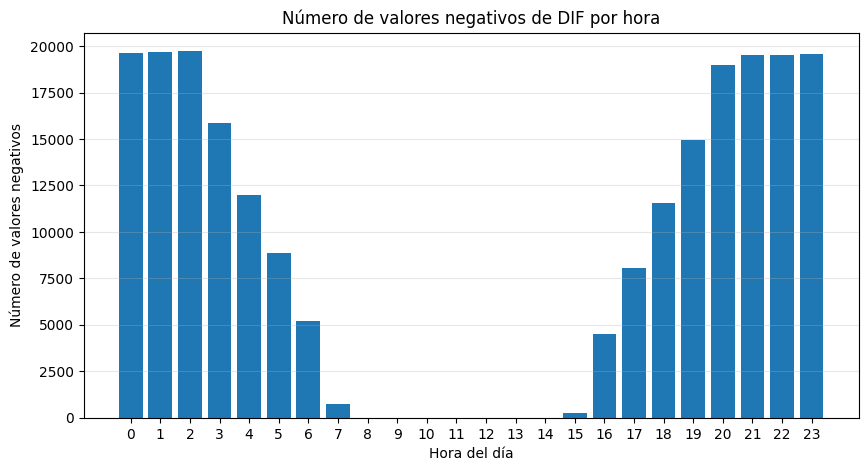

In [57]:
plt.figure(figsize=(10, 5))

plt.bar(
    negativos_por_hora_DIF.index,
    negativos_por_hora_DIF.values
)

plt.title("Número de valores negativos de DIF por hora")
plt.xlabel("Hora del día")
plt.ylabel("Número de valores negativos")
plt.xticks(range(24))
plt.grid(True, axis="y", alpha=0.3)

plt.show()

In [58]:
total_por_hora = (
    df.groupby("hour")
    .size()
    .reindex(range(24), fill_value=0)
)

porcentaje_negativos_por_hora_DIF = (
    negativos_por_hora_DIF / total_por_hora * 100
).fillna(0)

porcentaje_negativos_por_hora_DIF

,0
hour,
0,82.685185
1,82.727273
2,83.047138
3,66.818182
4,50.530303
5,37.340067
6,21.973906
7,3.097643
8,0.008418


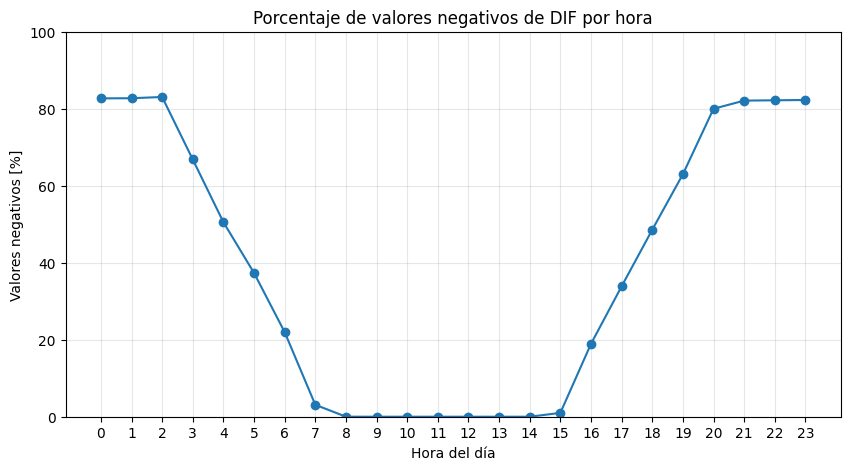

In [59]:
plt.figure(figsize=(10, 5))

plt.plot(
    porcentaje_negativos_por_hora_DIF.index,
    porcentaje_negativos_por_hora_DIF.values,
    marker="o"
)

plt.title("Porcentaje de valores negativos de DIF por hora")
plt.xlabel("Hora del día")
plt.ylabel("Valores negativos [%]")
plt.xticks(range(24))
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)

plt.show()

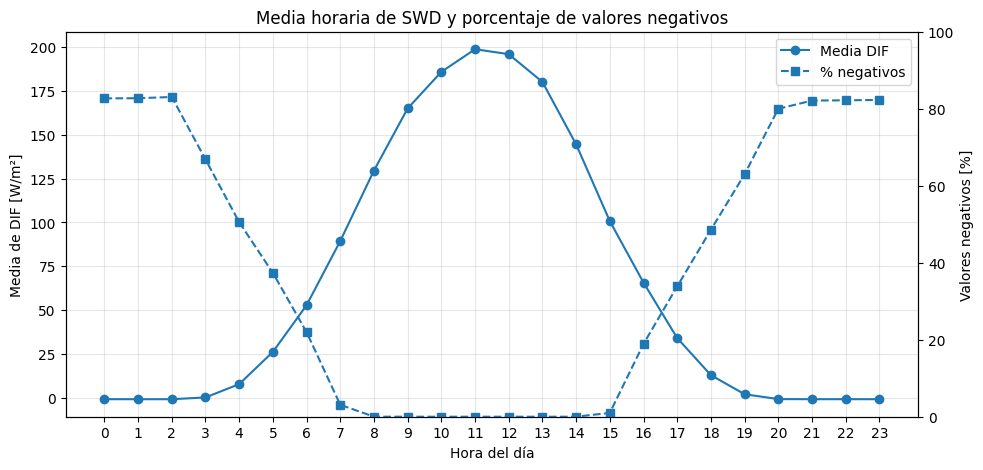

In [60]:
fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.plot(
    resumen_horario_DIF.index,
    resumen_horario_DIF["mean"],
    marker="o",
    label="Media DIF"
)

ax1.set_xlabel("Hora del día")
ax1.set_ylabel("Media de DIF [W/m²]")
ax1.set_xticks(range(24))
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()

ax2.plot(
    porcentaje_negativos_por_hora_DIF.index,
    porcentaje_negativos_por_hora_DIF.values,
    marker="s",
    linestyle="--",
    label="% negativos"
)

ax2.set_ylabel("Valores negativos [%]")
ax2.set_ylim(0, 100)

plt.title("Media horaria de SWD y porcentaje de valores negativos")

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines_1 + lines_2,
    labels_1 + labels_2,
    loc="upper right"
)

plt.show()

In [61]:
df["estado_dif"] = np.select(
    [
        df["DIF [W/m**2]"] < 0,
        df["DIF [W/m**2]"] == 0,
        df["DIF [W/m**2]"] > 0
    ],
    [
        "Negativo",
        "Cero",
        "Positivo"
    ],
    default="Missing"
)

In [62]:
tabla_estado_hora_DIF = (
    df.groupby(["hour", "estado_dif"])
    .size()
    .unstack(fill_value=0)
    .reindex(range(24), fill_value=0)
)

tabla_estado_hora_DIF

estado_dif,Cero,Missing,Negativo,Positivo
hour,,,,
0,3694,420,19646,0
1,3679,425,19656,0
2,3603,420,19732,5
3,4357,424,15876,3103
4,3769,441,12006,7544
5,3114,441,8872,11333
6,2684,446,5221,15409
7,1359,513,736,21152
8,33,547,2,23178


In [63]:
tabla_estado_hora_pct_DIF = (
    tabla_estado_hora_DIF
    .div(tabla_estado_hora_DIF.sum(axis=1), axis=0)
    * 100
)

tabla_estado_hora_pct_DIF

estado_dif,Cero,Missing,Negativo,Positivo
hour,,,,
0,15.547138,1.767677,82.685185,0.000000
1,15.484007,1.788721,82.727273,0.000000
2,15.164141,1.767677,83.047138,0.021044
3,18.337542,1.784512,66.818182,13.059764
4,15.862795,1.856061,50.530303,31.750842
5,13.106061,1.856061,37.340067,47.697811
6,11.296296,1.877104,21.973906,64.852694
7,5.719697,2.159091,3.097643,89.023569
8,0.138889,2.302189,0.008418,97.550505


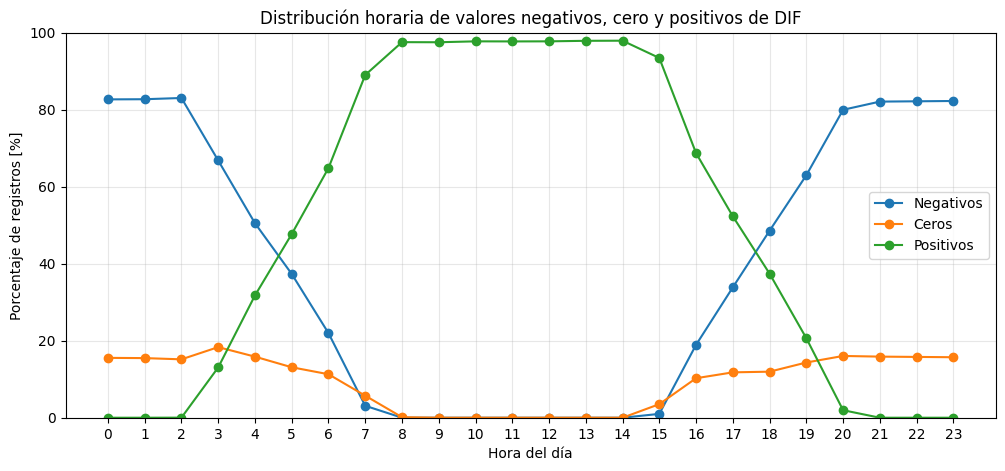

In [64]:
plt.figure(figsize=(12, 5))

plt.plot(tabla_estado_hora_pct_DIF.index, tabla_estado_hora_pct_DIF.get("Negativo", 0), marker="o", label="Negativos")
plt.plot(tabla_estado_hora_pct_DIF.index, tabla_estado_hora_pct_DIF.get("Cero", 0), marker="o", label="Ceros")
plt.plot(tabla_estado_hora_pct_DIF.index, tabla_estado_hora_pct_DIF.get("Positivo", 0), marker="o", label="Positivos")

plt.title("Distribución horaria de valores negativos, cero y positivos de DIF")
plt.xlabel("Hora del día")
plt.ylabel("Porcentaje de registros [%]")
plt.xticks(range(24))
plt.ylim(0, 100)
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

La variable `DIF [W/m²]`, correspondiente a la irradiancia difusa, presenta una distribución fuertemente asimétrica hacia la derecha, con una elevada concentración de valores próximos a cero y una cola larga hacia valores altos. Esta forma de la distribución es coherente con la naturaleza de la variable, ya que la radiación difusa es muy baja o inexistente durante la noche, mientras que durante las horas diurnas puede alcanzar valores elevados en función de la posición solar y de las condiciones atmosféricas, especialmente en situaciones de nubosidad o dispersión de la radiación solar.

Desde el punto de vista estadístico, la variable presenta un valor mínimo de -4 W/m² y un máximo de 723 W/m². La media se sitúa en 65,96 W/m², mientras que la mediana es únicamente de 2 W/m², lo que confirma una distribución muy desequilibrada y dominada por registros de baja irradiancia. El primer cuartil es igual a -1 W/m² y el tercer cuartil alcanza 101 W/m², mientras que el percentil 95 se sitúa en 300 W/m². Esta diferencia entre la mediana, los cuartiles y los percentiles superiores evidencia que la variable permanece en valores muy bajos durante una parte importante del periodo analizado, pero puede alcanzar niveles considerablemente más altos durante las horas centrales del día.

En cuanto a los valores más frecuentes, destaca especialmente el valor -1 W/m², que representa aproximadamente el 37,4 % de los registros. También aparece una proporción relevante de valores iguales a 0 W/m², con un 9,4 % del total. Por tanto, una parte muy importante de la variable se concentra en torno al cero, aunque con una particularidad relevante: en el caso de `DIF`, el valor más frecuente no es exactamente cero, sino -1 W/m². Dado que la irradiancia difusa no debería tomar valores negativos desde el punto de vista físico, estos valores negativos deben interpretarse como pequeñas desviaciones instrumentales alrededor del cero, probablemente asociadas a ruido de medición, calibración del sensor o redondeo durante periodos nocturnos o de irradiancia muy baja.

La variable presenta 218.624 valores negativos, equivalentes aproximadamente al 38,3 % del total de registros. Aunque este porcentaje es elevado, la mayoría de estos valores se concentran en magnitudes muy pequeñas, principalmente en -1 W/m², seguido de valores mucho menos frecuentes como -2, -3 y -4 W/m². Por tanto, no parecen corresponder a errores extremos, sino a un comportamiento sistemático del sensor alrededor del límite inferior físico de la variable. En fases posteriores de preprocesamiento, una opción razonable sería truncar estos valores negativos a cero, especialmente al tratarse de la variable objetivo del estudio y no ser físicamente admisibles valores negativos de irradiancia difusa.

El análisis horario muestra un patrón diario claramente coherente con el ciclo solar. La media de `DIF` aumenta progresivamente desde las primeras horas de la mañana, alcanza su máximo en torno a las horas centrales del día, especialmente entre las 11:00 y las 12:00, y desciende posteriormente durante la tarde hasta aproximarse nuevamente a cero durante la noche. Este comportamiento confirma que la variable recoge adecuadamente la dinámica esperada de la radiación difusa.

La distribución horaria de valores negativos refuerza esta interpretación. Durante la noche y las horas de baja irradiancia, el porcentaje de valores negativos es muy elevado, superando el 80 % en varias franjas horarias nocturnas. Sin embargo, durante las horas centrales del día los valores negativos prácticamente desaparecen, y la variable queda dominada por registros positivos. Esto indica que los valores negativos están principalmente asociados a periodos sin radiación solar significativa y no a anomalías durante el periodo diurno útil.

Respecto a los valores nulos, estos representan aproximadamente el 9,4 % de los registros. Su presencia se concentra principalmente en periodos de baja radiación, aunque en menor proporción que los valores negativos. A diferencia de lo observado en otras variables, en `DIF` parece existir una tendencia del sensor a registrar valores ligeramente negativos en lugar de ceros exactos durante una parte importante de los periodos nocturnos.

Por último, la variable presenta 11.605 valores ausentes, equivalentes aproximadamente al 2,0 % del total de registros. Este porcentaje no es excesivamente elevado, aunque sí requiere un análisis posterior junto con el resto de variables del dataset para comprobar si los valores perdidos aparecen de forma aislada o si responden a patrones comunes de ausencia asociados a fallos temporales del sistema de medición o adquisición de datos. Por este motivo, el tratamiento definitivo de los valores ausentes se abordará en el análisis conjunto de completitud del dataset.

En conjunto, `DIF [W/m²]` se considera una variable fundamental para el estudio, al representar la componente de radiación que se pretende predecir. Su comportamiento temporal es coherente con el ciclo solar, pero presenta una proporción elevada de valores negativos de baja magnitud, concentrados principalmente en periodos nocturnos. Estos valores deberán tratarse cuidadosamente en la fase de preprocesamiento para garantizar la coherencia física de la variable objetivo antes de aplicar los modelos predictivos.

### DIF mínimo

Resumen estadístico horario para DIF min:


,count,mean,median,min,max
hour,,,,,
0,23340,-0.948500,-1.0,-3.0,0.0
1,23335,-0.943304,-1.0,-3.0,0.0
2,23340,-0.952571,-1.0,-4.0,2.0
3,23336,0.042295,-1.0,-4.0,42.0
4,23319,7.476693,-1.0,-3.0,145.0
5,23319,25.602856,0.0,-3.0,226.0
6,23314,51.730505,26.0,-3.0,331.0
7,23247,87.501699,66.0,-2.0,464.0
8,23213,126.686512,98.0,-1.0,624.0


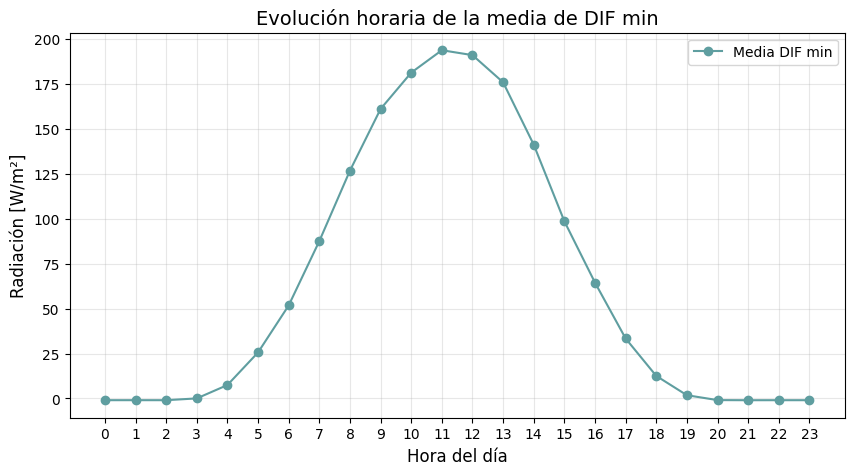

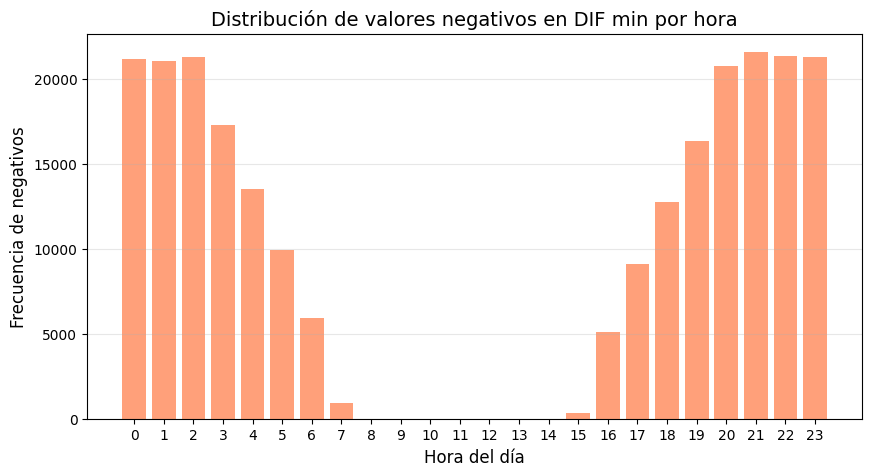

In [65]:
col_dif_min = 'DIF min [W/m**2]'

# 1. Resumen estadístico por hora
resumen_horario_dif_min = (
    df.groupby('hour')[col_dif_min]
    .agg(
        count='count',
        mean='mean',
        median='median',
        min='min',
        max='max'
    )
    .reindex(range(24))
)

print("Resumen estadístico horario para DIF min:")
display(resumen_horario_dif_min)

# 2. Visualización de la media horaria
plt.figure(figsize=(10, 5))
plt.plot(resumen_horario_dif_min.index, resumen_horario_dif_min['mean'], marker='o', color='cadetblue', label='Media DIF min')
plt.title("Evolución horaria de la media de DIF min", fontsize=14)
plt.xlabel("Hora del día", fontsize=12)
plt.ylabel("Radiación [W/m²]", fontsize=12)
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# 3. Distribución de negativos
negativos_dif_min_hora = (
    df[df[col_dif_min] < 0]
    .groupby('hour')
    .size()
    .reindex(range(24), fill_value=0)
)

plt.figure(figsize=(10, 5))
plt.bar(negativos_dif_min_hora.index, negativos_dif_min_hora.values, color='lightsalmon')
plt.title("Distribución de valores negativos en DIF min por hora", fontsize=14)
plt.xlabel("Hora del día", fontsize=12)
plt.ylabel("Frecuencia de negativos", fontsize=12)
plt.xticks(range(24))
plt.grid(True, axis='y', alpha=0.3)
plt.show()

### DIF máximo

Resumen estadístico horario para DIF max:


,count,mean,median,min,max
hour,,,,,
0,23340,-0.772922,-1.0,-3.0,0.0
1,23335,-0.775530,-1.0,-3.0,0.0
2,23340,-0.773693,-1.0,-3.0,3.0
3,23336,0.283339,-1.0,-3.0,44.0
4,23319,8.017882,0.0,-3.0,157.0
5,23319,26.699044,0.0,-3.0,235.0
6,23314,53.838509,28.0,-3.0,354.0
7,23247,91.382802,69.0,-2.0,468.0
8,23213,132.637531,102.0,0.0,671.0


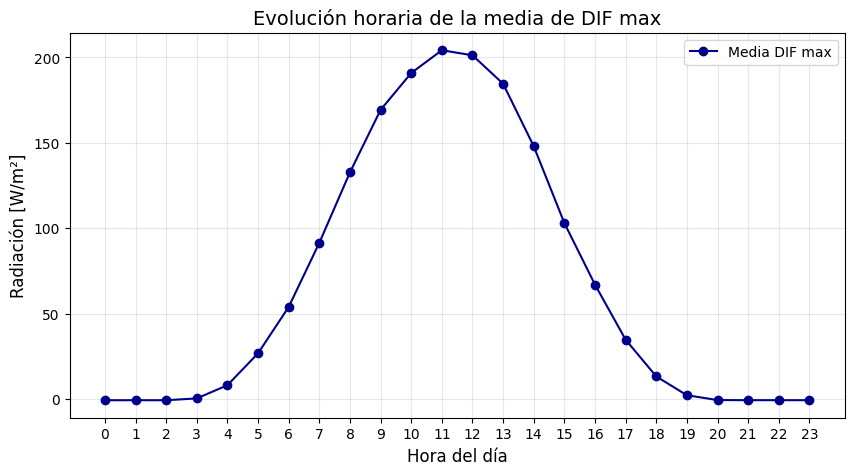

In [66]:
col_dif_max = 'DIF max [W/m**2]'

# 1. Resumen estadístico por hora
resumen_horario_dif_max = (
    df.groupby('hour')[col_dif_max]
    .agg(
        count='count',
        mean='mean',
        median='median',
        min='min',
        max='max'
    )
    .reindex(range(24))
)

print("Resumen estadístico horario para DIF max:")
display(resumen_horario_dif_max)

# 2. Visualización de la media horaria
plt.figure(figsize=(10, 5))
plt.plot(resumen_horario_dif_max.index, resumen_horario_dif_max['mean'], marker='o', color='darkblue', label='Media DIF max')
plt.title("Evolución horaria de la media de DIF max", fontsize=14)
plt.xlabel("Hora del día", fontsize=12)
plt.ylabel("Radiación [W/m²]", fontsize=12)
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

### Coherencia entre los estadísticos del bloque DIF

Registros analizados DIF: 558635
Violaciones de la lógica min <= media <= max: 0


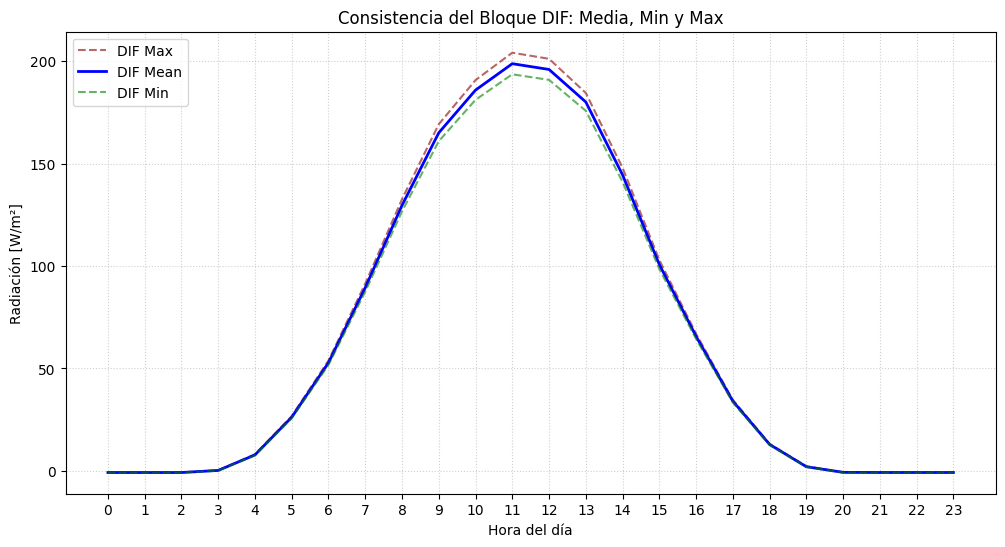

In [67]:
# Coherencia entre estadísticos del bloque DIF
cols_dif = ['DIF [W/m**2]', 'DIF min [W/m**2]', 'DIF max [W/m**2]', 'DIF std dev [W/m**2]']
df_dif_valid = df[cols_dif].dropna()

violaciones_dif = df_dif_valid[~((df_dif_valid['DIF min [W/m**2]'] <= df_dif_valid['DIF [W/m**2]']) &
                                 (df_dif_valid['DIF [W/m**2]'] <= df_dif_valid['DIF max [W/m**2]']))]

print(f"Registros analizados DIF: {len(df_dif_valid)}")
print(f"Violaciones de la lógica min <= media <= max: {len(violaciones_dif)}")

perfil_dif = df.groupby('hour')[cols_dif].mean()

fig, ax1 = plt.subplots(figsize=(12, 6))
ax1.plot(perfil_dif.index, perfil_dif['DIF max [W/m**2]'], label='DIF Max', color='darkred', linestyle='--', alpha=0.6)
ax1.plot(perfil_dif.index, perfil_dif['DIF [W/m**2]'], label='DIF Mean', color='blue', linewidth=2)
ax1.plot(perfil_dif.index, perfil_dif['DIF min [W/m**2]'], label='DIF Min', color='green', linestyle='--', alpha=0.6)

ax1.set_xlabel('Hora del día')
ax1.set_ylabel('Radiación [W/m²]')
ax1.set_xticks(range(24))
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend(loc='upper left')
plt.title('Consistencia del Bloque DIF: Media, Min y Max')
plt.show()

### Distribución mensual del bloque DIF

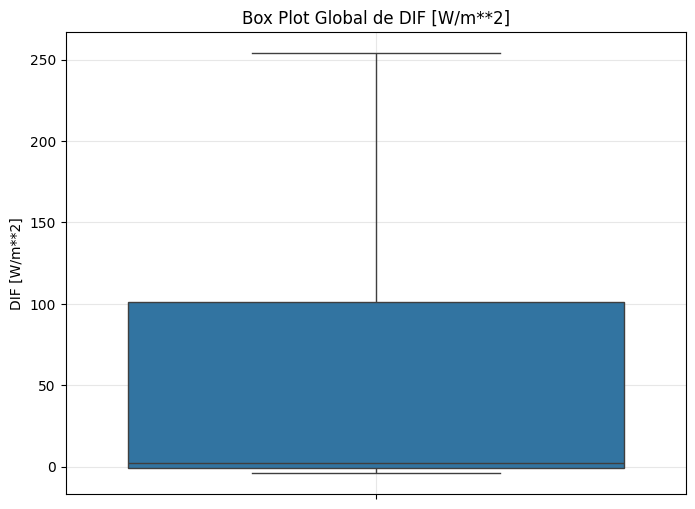

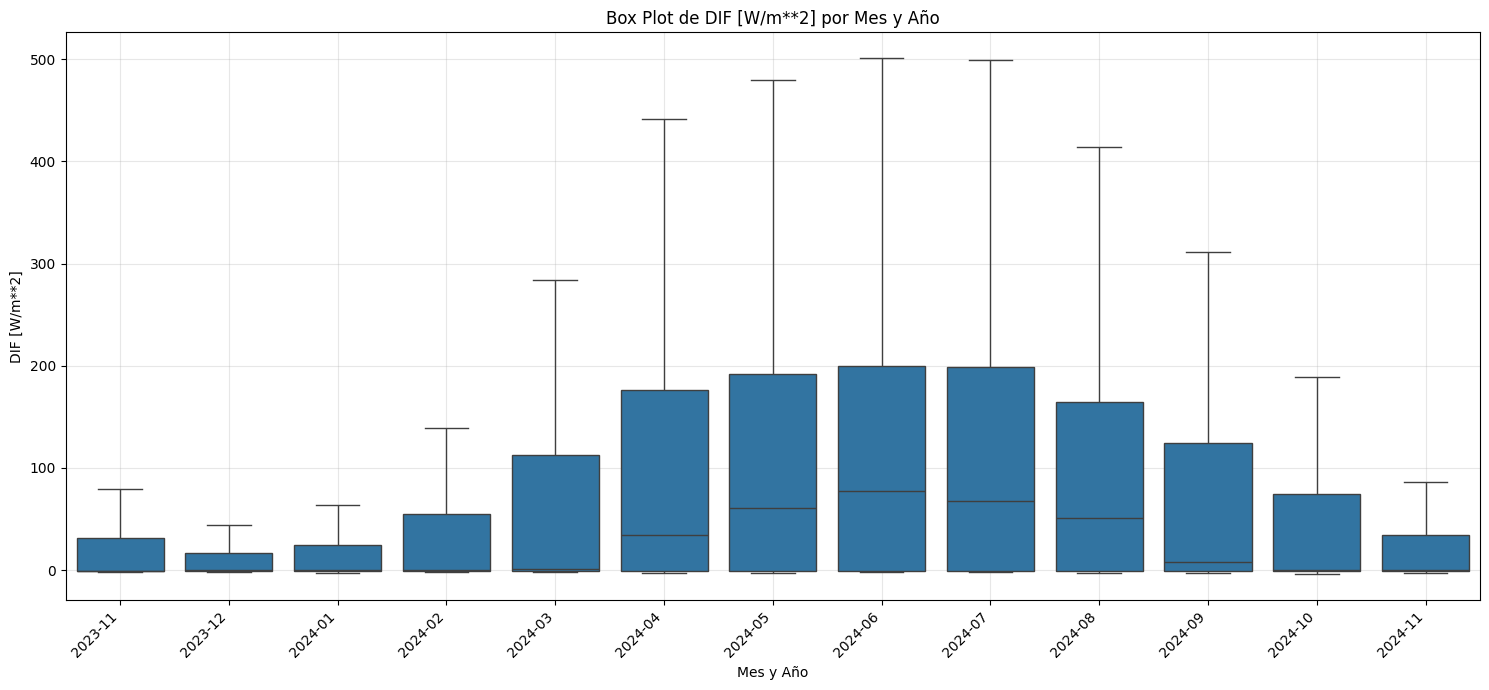

In [68]:
# Box plot global para DIF
plt.figure(figsize=(8, 6))
sns.boxplot(y=df["DIF [W/m**2]"], showfliers=False)
plt.title("Box Plot Global de DIF [W/m**2]")
plt.ylabel("DIF [W/m**2]")
plt.grid(True, alpha=0.3)
plt.show()

# Box plot de DIF por agregación mensual y anual
plt.figure(figsize=(15, 7))
sns.boxplot(data=df, x="year_month", y="DIF [W/m**2]", showfliers=False, order=sorted(df['year_month'].unique()))
plt.title("Box Plot de DIF [W/m**2] por Mes y Año")
plt.xlabel("Mes y Año")
plt.ylabel("DIF [W/m**2]")
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

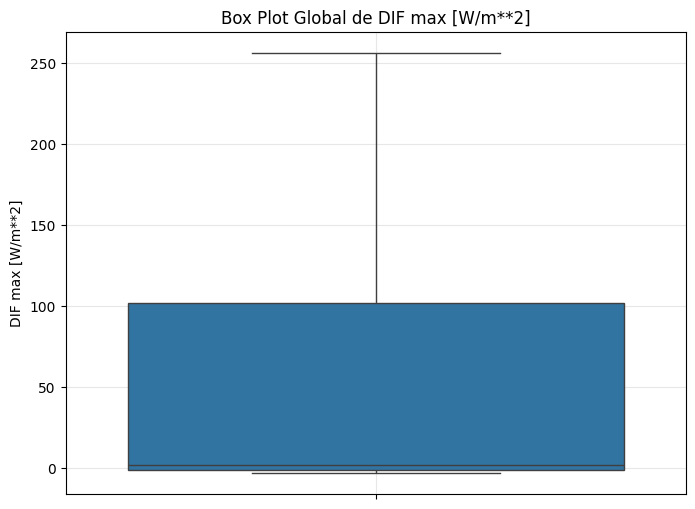

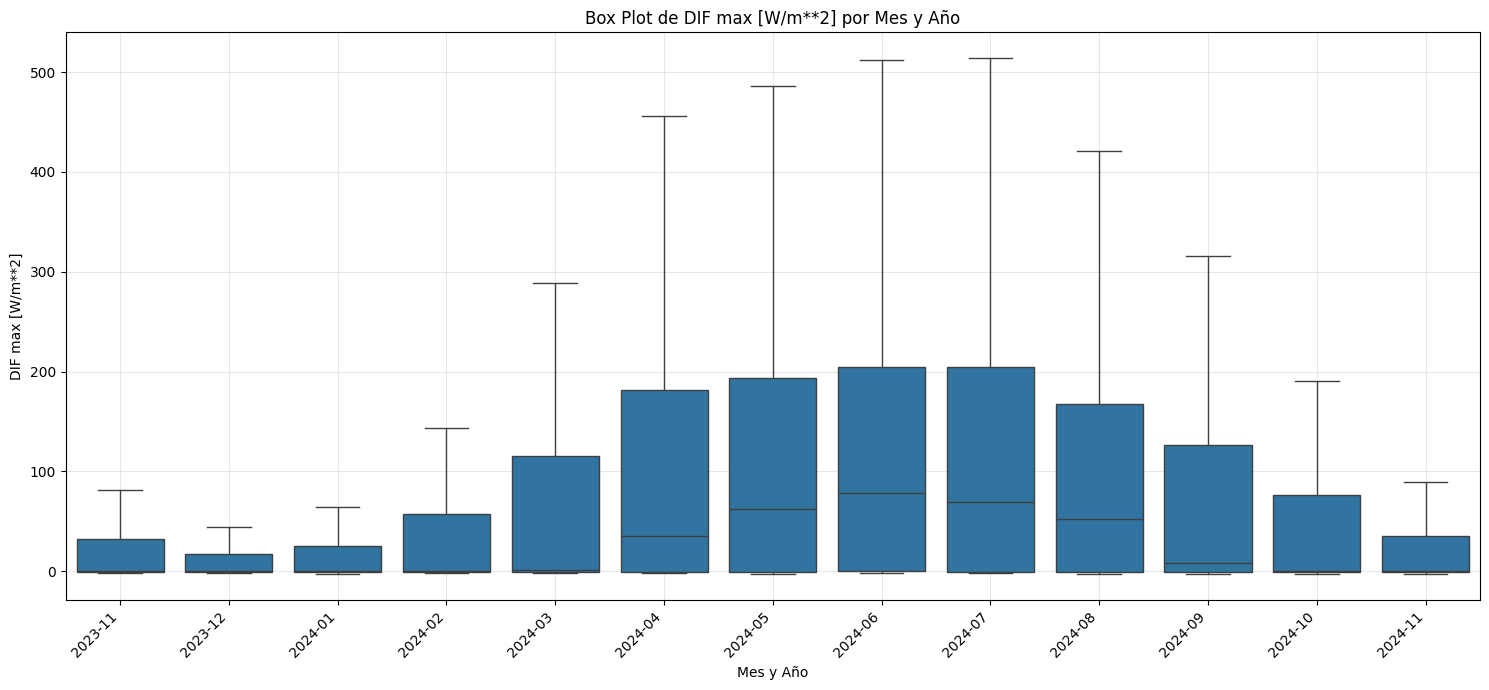

In [69]:
col_dif_max = "DIF max [W/m**2]"

# Box plot global para DIF MAX
plt.figure(figsize=(8, 6))
sns.boxplot(y=df[col_dif_max], showfliers=False)
plt.title(f"Box Plot Global de {col_dif_max}")
plt.ylabel(col_dif_max)
plt.grid(True, alpha=0.3)
plt.show()

# Box plot de DIF MAX por agregación mensual y anual
plt.figure(figsize=(15, 7))
sns.boxplot(data=df, x="year_month", y=col_dif_max, showfliers=False, order=sorted(df['year_month'].unique()))
plt.title(f"Box Plot de {col_dif_max} por Mes y Año")
plt.xlabel("Mes y Año")
plt.ylabel(col_dif_max)
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

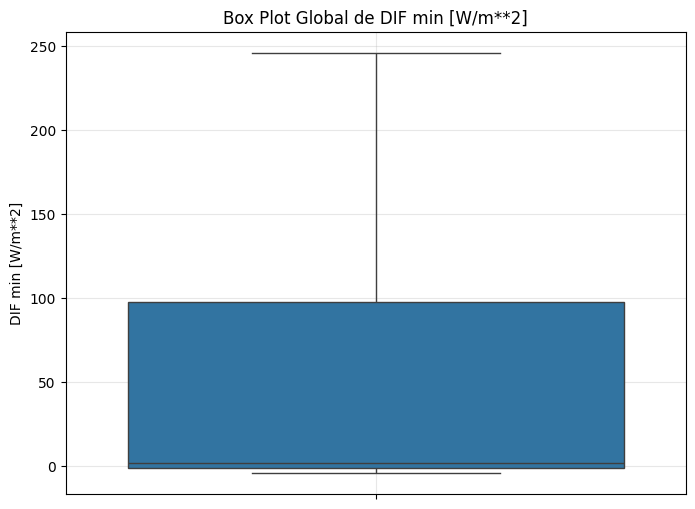

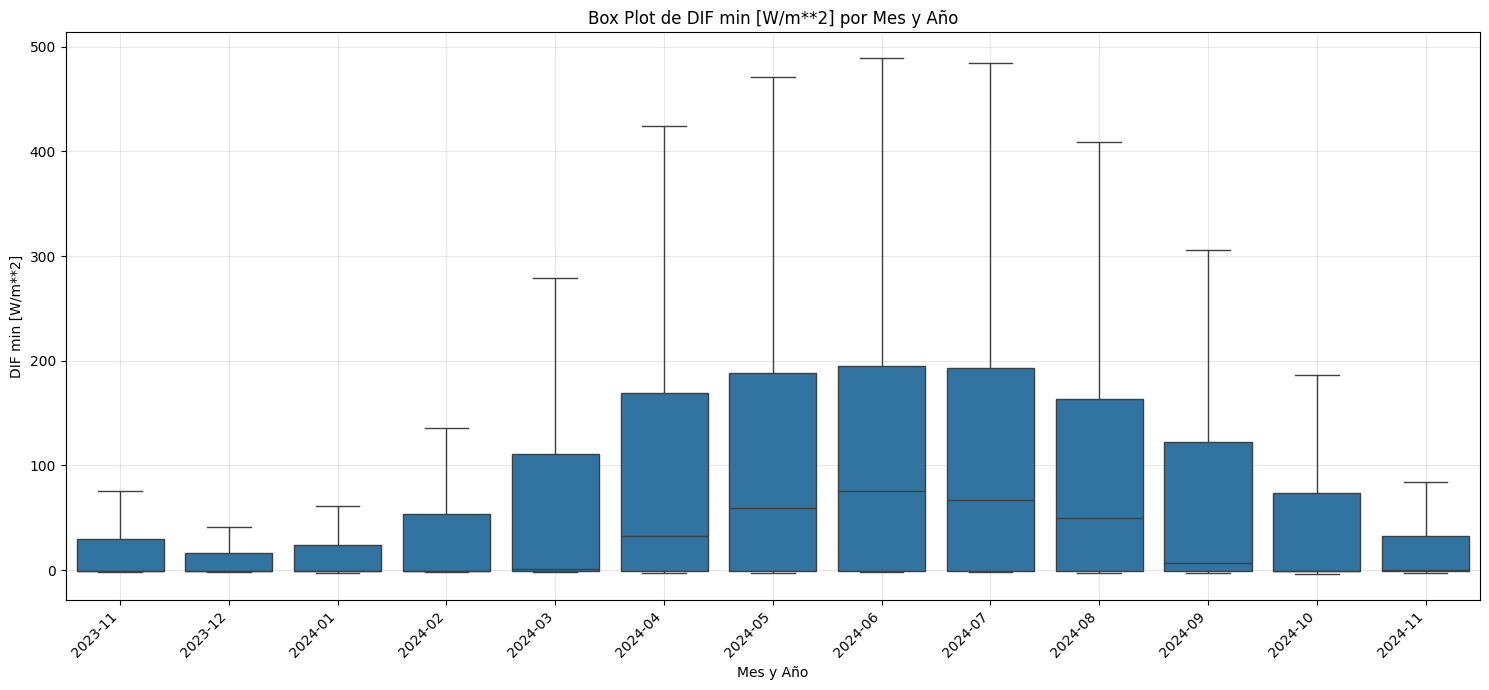

In [70]:
col_dif_min = "DIF min [W/m**2]"

# Box plot global para DIF MIN
plt.figure(figsize=(8, 6))
sns.boxplot(y=df[col_dif_min], showfliers=False)
plt.title(f"Box Plot Global de {col_dif_min}")
plt.ylabel(col_dif_min)
plt.grid(True, alpha=0.3)
plt.show()

# Box plot de DIF MIN por agregación mensual y anual
plt.figure(figsize=(15, 7))
sns.boxplot(data=df, x="year_month", y=col_dif_min, showfliers=False, order=sorted(df['year_month'].unique()))
plt.title(f"Box Plot de {col_dif_min} por Mes y Año")
plt.xlabel("Mes y Año")
plt.ylabel(col_dif_min)
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

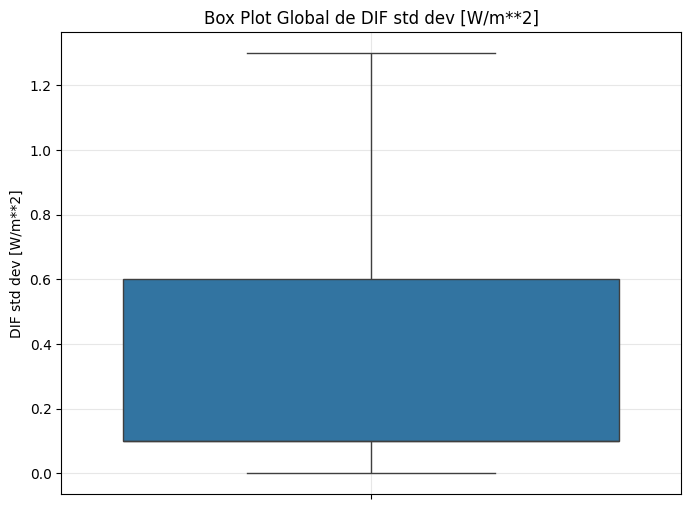

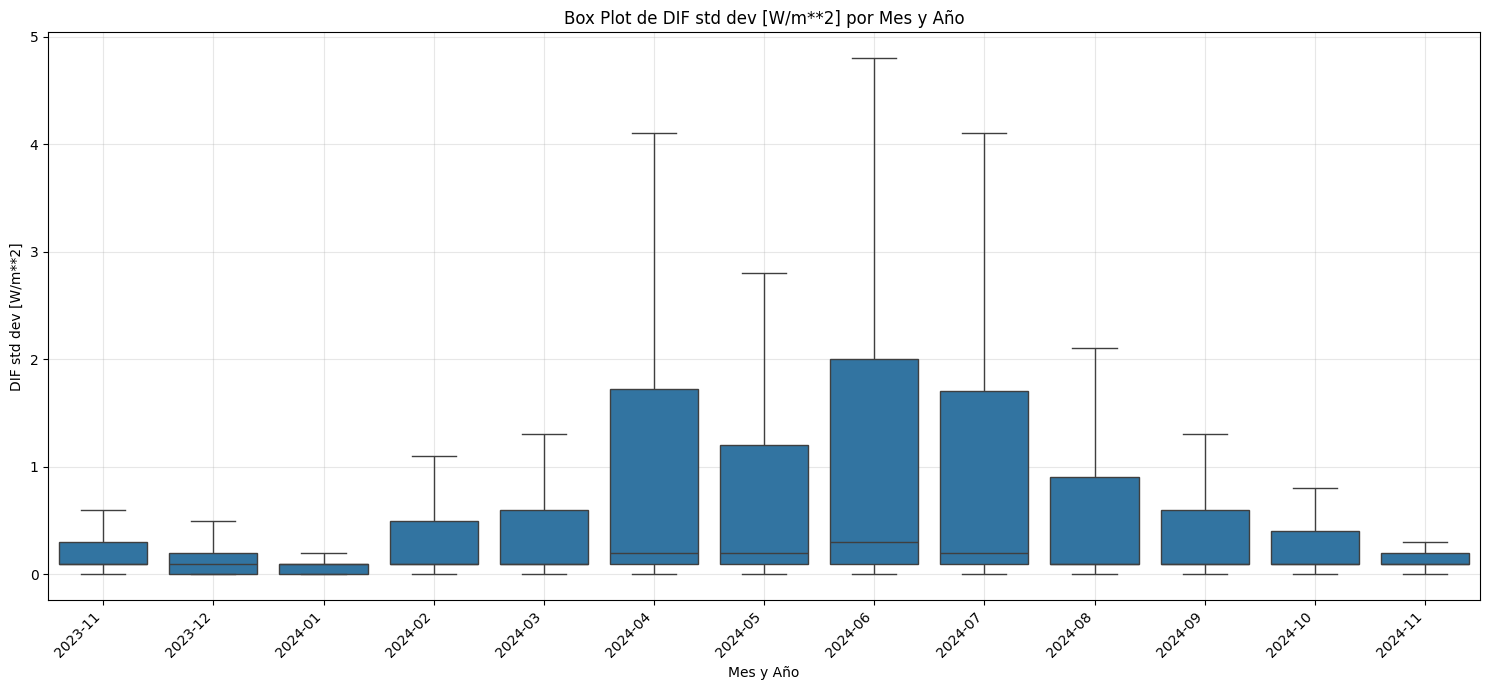

In [71]:
col_dif_std = "DIF std dev [W/m**2]"

# Box plot global para DIF std dev
plt.figure(figsize=(8, 6))
sns.boxplot(y=df[col_dif_std], showfliers=False)
plt.title(f"Box Plot Global de {col_dif_std}")
plt.ylabel(col_dif_std)
plt.grid(True, alpha=0.3)
plt.show()

# Box plot de DIF std dev por agregación mensual y anual
plt.figure(figsize=(15, 7))
sns.boxplot(data=df, x="year_month", y=col_dif_std, showfliers=False, order=sorted(df['year_month'].unique()))
plt.title(f"Box Plot de {col_dif_std} por Mes y Año")
plt.xlabel("Mes y Año")
plt.ylabel(col_dif_std)
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Radiación de onda larga descendente (LWD)

In [72]:
resumen_horario_lwd = (
    df.groupby("hour")["LWD [W/m**2]"]
    .agg(
        count="count",
        mean="mean",
        median="median",
        min="min",
        max="max"
    )
    .reindex(range(24))
)

resumen_horario_lwd

,count,mean,median,min,max
hour,,,,,
0,23760,325.580640,330.0,201.0,426.0
1,23755,325.462134,333.0,199.0,415.0
2,23760,324.944992,332.0,199.0,411.0
3,23760,325.161911,331.0,198.0,410.0
4,23726,325.142713,331.0,198.0,412.0
5,23752,325.689963,332.0,199.0,410.0
6,23726,326.057827,332.0,197.0,413.0
7,23654,327.736070,333.0,194.0,412.0
8,23631,330.117134,335.0,194.0,418.0


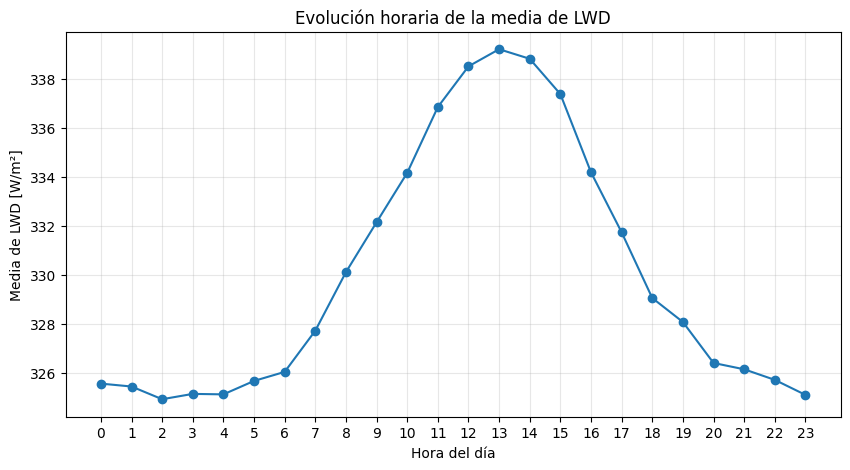

In [73]:
plt.figure(figsize=(10, 5))

plt.plot(
    resumen_horario_lwd.index,
    resumen_horario_lwd["mean"],
    marker="o"
)

plt.title("Evolución horaria de la media de LWD")
plt.xlabel("Hora del día")
plt.ylabel("Media de LWD [W/m²]")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)

plt.show()

El análisis horario de LWD [W/m²] muestra una evolución diaria suave, con valores medios más bajos durante la noche y un incremento progresivo a partir de las primeras horas de la mañana hasta alcanzar el máximo en torno a las 13:00–14:00. Posteriormente, la media desciende de forma gradual durante la tarde y la noche. A diferencia de las variables de radiación de onda corta, este patrón no implica una desaparición de la radiación durante el periodo nocturno, sino una variación moderada asociada previsiblemente al ciclo térmico diario de la atmósfera. La amplitud del cambio horario es reducida, pasando aproximadamente de 325 W/m² en las horas nocturnas a unos 339 W/m² en las horas centrales, lo que confirma el carácter estable de la variable. Por tanto, LWD no presenta un comportamiento problemático, sino una variación diaria suave y físicamente coherente.

La variable `LWD [W/m²]`, correspondiente a la radiación de onda larga descendente, presenta un comportamiento claramente más estable que las variables de radiación de onda corta analizadas previamente. A diferencia de `SWD`, `DIR` o `DIF`, esta variable no muestra una elevada concentración de valores próximos a cero, ni presenta valores negativos o nulos. Esto resulta coherente con su naturaleza física, ya que la radiación de onda larga descendente está asociada principalmente a la emisión térmica de la atmósfera y no desaparece durante la noche.

Desde el punto de vista estadístico, `LWD` presenta un valor mínimo de 194 W/m² y un máximo de 461 W/m², con una media de 329,97 W/m² y una mediana de 336 W/m². La proximidad entre la media y la mediana indica una distribución relativamente equilibrada, aunque con una ligera asimetría hacia la izquierda, reflejada en un coeficiente de asimetría negativo. El primer cuartil se sitúa en 306 W/m² y el tercer cuartil en 358 W/m², dando lugar a un rango intercuartílico de 52 W/m². Esto muestra que la mayor parte de las observaciones se concentran en un intervalo relativamente estrecho en comparación con las variables solares de onda corta.

El histograma de la variable muestra una distribución aproximadamente acampanada, con la mayor concentración de registros en torno a valores comprendidos entre 330 y 350 W/m². Aunque no puede afirmarse que siga una distribución normal perfecta, sí presenta una forma mucho más próxima a una distribución simétrica y estable que las variables `SWD`, `DIR` y `DIF`, que estaban dominadas por valores nulos, negativos o muy próximos a cero. La ligera asimetría negativa sugiere la existencia de una cola algo más extendida hacia valores bajos, posiblemente asociada a condiciones atmosféricas más frías o secas.

En cuanto a la calidad de los datos, `LWD` no presenta valores negativos ni valores iguales a cero, lo cual es coherente con el comportamiento físico esperado de la radiación atmosférica de onda larga. Además, únicamente se observan 815 valores ausentes, equivalentes aproximadamente al 0,1 % del total de registros. Por tanto, la completitud de esta variable es elevada y no parece presentar problemas relevantes de calidad en comparación con otras variables del conjunto de datos.

En conjunto, `LWD [W/m²]` puede considerarse una variable estable, físicamente coherente y con una distribución razonablemente concentrada. Su comportamiento sugiere que no requiere tratamientos específicos relacionados con valores negativos o ceros anómalos. No obstante, sus valores ausentes deberán revisarse posteriormente dentro del análisis conjunto de completitud del dataset, con el objetivo de comprobar si coinciden temporalmente con ausencias en otras variables.

### Bloque LWD: mínimo, máximo y coherencia

Resumen Estadístico: LWD min


,count,mean,median,min,max
hour,,,,,
0,23760,324.992214,329.0,201.0,425.0
1,23755,324.902000,332.0,199.0,414.0
2,23760,324.373022,332.0,198.0,411.0
3,23760,324.583291,330.0,198.0,410.0
4,23726,324.548554,331.0,198.0,411.0



Resumen Estadístico: LWD max


,count,mean,median,min,max
hour,,,,,
0,23760,326.168013,330.0,201.0,427.0
1,23755,326.030057,334.0,199.0,415.0
2,23760,325.533333,333.0,199.0,411.0
3,23760,325.756902,331.0,198.0,411.0
4,23726,325.729284,332.0,199.0,412.0


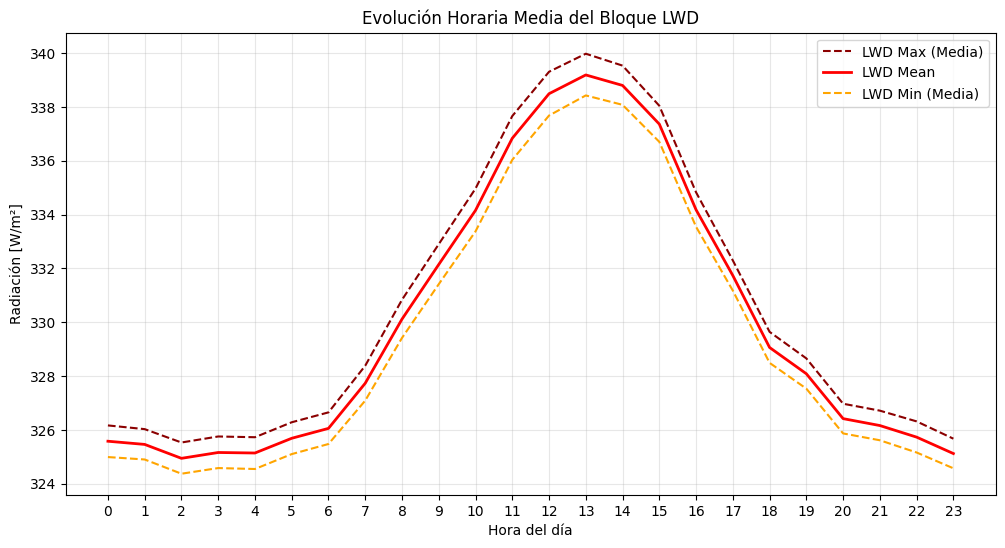


Análisis de consistencia sobre 569425 registros:
Violaciones de la lógica min <= media <= max: 0


In [74]:
# Variables del bloque LWD
col_lwd = 'LWD [W/m**2]'
col_lwd_min = 'LWD min [W/m**2]'
col_lwd_max = 'LWD max [W/m**2]'
col_lwd_std = 'LWD std dev [W/m**2]'
cols_lwd = [col_lwd, col_lwd_min, col_lwd_max, col_lwd_std]

# 1. Resumen estadístico horario para LWD min
resumen_horario_lwd_min = df.groupby('hour')[col_lwd_min].agg(['count', 'mean', 'median', 'min', 'max'])
print("Resumen Estadístico: LWD min")
display(resumen_horario_lwd_min.head())

# 2. Resumen estadístico horario para LWD max
resumen_horario_lwd_max = df.groupby('hour')[col_lwd_max].agg(['count', 'mean', 'median', 'min', 'max'])
print("\nResumen Estadístico: LWD max")
display(resumen_horario_lwd_max.head())

# 3. Visualización de la evolución horaria de las medias
plt.figure(figsize=(12, 6))
perfil_lwd = df.groupby('hour')[cols_lwd].mean()

plt.plot(perfil_lwd.index, perfil_lwd[col_lwd_max], label='LWD Max (Media)', color='darkred', linestyle='--')
plt.plot(perfil_lwd.index, perfil_lwd[col_lwd], label='LWD Mean', color='red', linewidth=2)
plt.plot(perfil_lwd.index, perfil_lwd[col_lwd_min], label='LWD Min (Media)', color='orange', linestyle='--')

plt.title("Evolución Horaria Media del Bloque LWD")
plt.xlabel("Hora del día")
plt.ylabel("Radiación [W/m²]")
plt.xticks(range(24))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 4. Verificación de consistencia matemática (min <= mean <= max)
df_lwd_valid = df[cols_lwd].dropna()
violaciones_lwd = df_lwd_valid[~((df_lwd_valid[col_lwd_min] <= df_lwd_valid[col_lwd]) &
                                 (df_lwd_valid[col_lwd] <= df_lwd_valid[col_lwd_max]))]

print(f"\nAnálisis de consistencia sobre {len(df_lwd_valid)} registros:")
print(f"Violaciones de la lógica min <= media <= max: {len(violaciones_lwd)}")

## 8. Radiación de onda corta ascendente (SWU)

,count,mean,median,min,max
hour,,,,,
0,23760,-0.051936,0.0,-1.0,0.0
1,23755,-0.054515,0.0,-1.0,0.0
2,23760,-0.047559,0.0,-2.0,2.0
3,23760,0.228367,0.0,-2.0,17.0
4,23760,3.090067,0.0,-2.0,63.0
5,23755,11.198695,0.0,-1.0,128.0
6,23742,23.920647,6.0,-1.0,172.0
7,23673,41.162928,22.0,-1.0,238.0
8,23628,59.395167,42.0,0.0,269.0


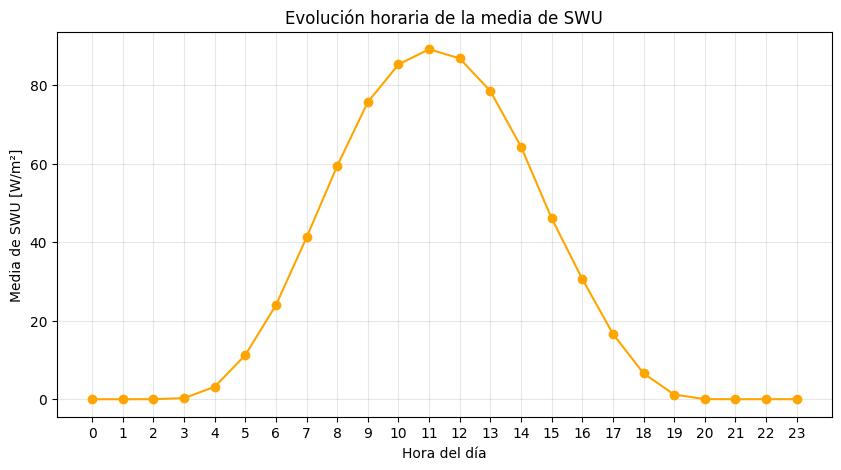

In [75]:
col_swu = "SWU [W/m**2]"

# 1. Resumen estadístico por hora
resumen_horario_swu = (
    df.groupby("hour")[col_swu]
    .agg(
        count="count",
        mean="mean",
        median="median",
        min="min",
        max="max"
    )
    .reindex(range(24))
)

display(resumen_horario_swu)

# 2. Evolución horaria de la media
plt.figure(figsize=(10, 5))
plt.plot(resumen_horario_swu.index, resumen_horario_swu["mean"], marker="o", color='orange')
plt.title("Evolución horaria de la media de SWU")
plt.xlabel("Hora del día")
plt.ylabel("Media de SWU [W/m²]")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.show()

In [76]:
# Proporción horaria de valores negativos, nulos y positivos
df["estado_swu"] = np.select(
    [
        df[col_swu] < 0,
        df[col_swu] == 0,
        df[col_swu] > 0
    ],
    [
        "Negativo",
        "Cero",
        "Positivo"
    ],
    default="Missing"
)

tabla_estado_hora_swu = (
    df.groupby(["hour", "estado_swu"])
    .size()
    .unstack(fill_value=0)
    .reindex(range(24), fill_value=0)
)

tabla_estado_hora_pct_swu = (
    tabla_estado_hora_swu
    .div(tabla_estado_hora_swu.sum(axis=1), axis=0)
    * 100
)

display(tabla_estado_hora_pct_swu)

estado_swu,Cero,Missing,Negativo,Positivo
hour,,,,
0,94.806397,0.000000,5.193603,0.000000
1,94.528620,0.021044,5.450337,0.000000
2,95.231481,0.000000,4.739057,0.029461
3,84.705387,0.000000,3.968855,11.325758
4,66.725589,0.000000,3.152357,30.122054
5,50.000000,0.021044,3.691077,46.287879
6,34.305556,0.075758,2.613636,63.005051
7,13.265993,0.366162,1.127946,85.239899
8,1.287879,0.555556,0.000000,98.156566


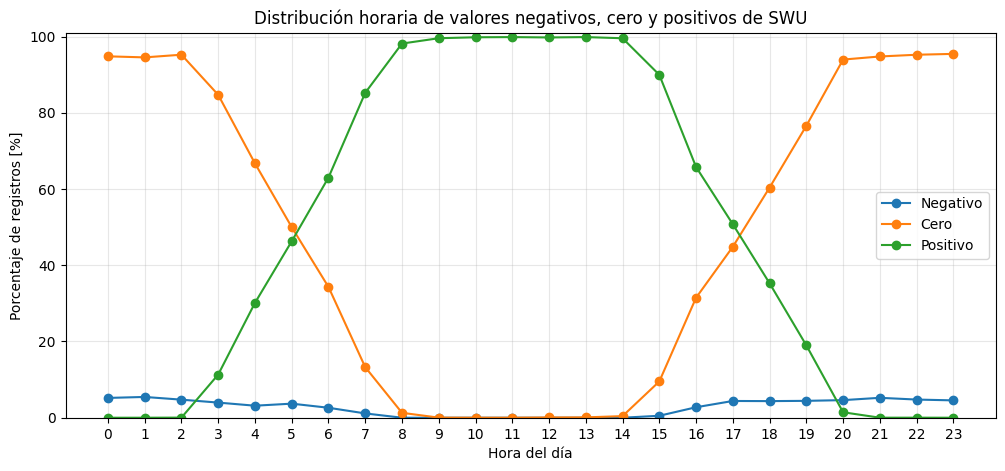

In [77]:
plt.figure(figsize=(12, 5))

for estado in ["Negativo", "Cero", "Positivo"]:
    if estado in tabla_estado_hora_pct_swu.columns:
        plt.plot(tabla_estado_hora_pct_swu.index, tabla_estado_hora_pct_swu[estado], marker="o", label=estado)

plt.title("Distribución horaria de valores negativos, cero y positivos de SWU")
plt.xlabel("Hora del día")
plt.ylabel("Porcentaje de registros [%]")
plt.xticks(range(24))
plt.ylim(0, 101)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

La variable `SWU [W/m²]`, correspondiente a la radiación de onda corta ascendente o reflejada por la superficie, presenta una distribución fuertemente asimétrica hacia la derecha, con una elevada concentración de valores nulos y una cola prolongada hacia valores positivos. Este comportamiento es coherente con la naturaleza física de la variable, ya que la radiación de onda corta ascendente depende directamente de la radiación solar incidente y, por tanto, tiende a ser nula durante la noche o en periodos sin radiación solar significativa.

Desde el punto de vista estadístico, `SWU` presenta un valor mínimo de -2 W/m² y un máximo de 329 W/m². La media se sitúa en 29,94 W/m², mientras que la mediana es igual a 0 W/m². Esta diferencia entre media y mediana refleja la presencia de un gran número de registros nulos, combinados con valores positivos durante las horas diurnas. El primer cuartil y la mediana son iguales a 0 W/m², mientras que el tercer cuartil alcanza 39 W/m² y el percentil 95 se sitúa en 153 W/m². Estos resultados indican que la variable permanece en valores bajos durante una parte importante del periodo analizado, pero puede alcanzar valores más elevados en las horas de mayor radiación solar.

En cuanto a los valores más frecuentes, destaca el valor 0 W/m², que representa aproximadamente el 47,4 % de los registros. Esta elevada proporción de ceros no debe interpretarse como un problema de calidad, sino como un comportamiento esperable siempre que dichos registros se concentren en periodos nocturnos o de baja irradiancia. El análisis horario confirma esta interpretación, ya que los ceros predominan durante la noche, mientras que desaparecen prácticamente en las horas centrales del día.

La evolución horaria de la media de `SWU` muestra un patrón diario claramente asociado al ciclo solar. La variable permanece próxima a cero durante la noche, comienza a aumentar a partir de las primeras horas de la mañana, alcanza su máximo alrededor de las 11:00–12:00 y desciende progresivamente durante la tarde hasta volver a valores cercanos a cero. Este comportamiento es coherente con la radiación de onda corta reflejada, ya que su magnitud depende de la radiación solar descendente y de las propiedades reflectantes de la superficie.

Respecto a los valores negativos, se observan 15.569 registros negativos, equivalentes aproximadamente al 2,7 % del total. No obstante, estos valores son de muy baja magnitud, con un mínimo de -2 W/m², y se concentran principalmente en torno a -1 W/m². Desde un punto de vista físico, la radiación de onda corta ascendente no debería adoptar valores negativos, por lo que estos registros pueden interpretarse como pequeñas desviaciones instrumentales alrededor del cero, posiblemente asociadas a ruido de medición, calibración o redondeo en momentos de irradiancia muy baja. Dado que su magnitud es reducida, no parecen representar errores graves de medición.

La variable presenta únicamente 492 valores ausentes, equivalentes aproximadamente al 0,1 % del total de registros, lo que indica una completitud muy elevada. En comparación con otras variables analizadas, `SWU` muestra una buena calidad general, ya que apenas presenta valores perdidos, los valores negativos son escasos y de baja magnitud, y los ceros aparecen de forma coherente con el ciclo solar.

En conjunto, `SWU [W/m²]` puede considerarse una variable físicamente coherente y de buena calidad dentro del conjunto de datos. Su comportamiento horario confirma la relación esperada con la radiación solar incidente, mientras que los pocos valores negativos detectados pueden tratarse posteriormente mediante truncamiento a cero para respetar la restricción física de no negatividad.

### Bloque SWU: perfil horario y coherencia

Estadísticas horarias medias para el bloque SWU:


,count,mean,std,min,max
hour,,,,,
0,23760,-0.051936,0.221903,-1.0,0.0
1,23755,-0.054515,0.227036,-1.0,0.0
2,23760,-0.047559,0.216949,-2.0,2.0
3,23760,0.228367,1.075086,-2.0,17.0
4,23760,3.090067,7.464966,-2.0,63.0


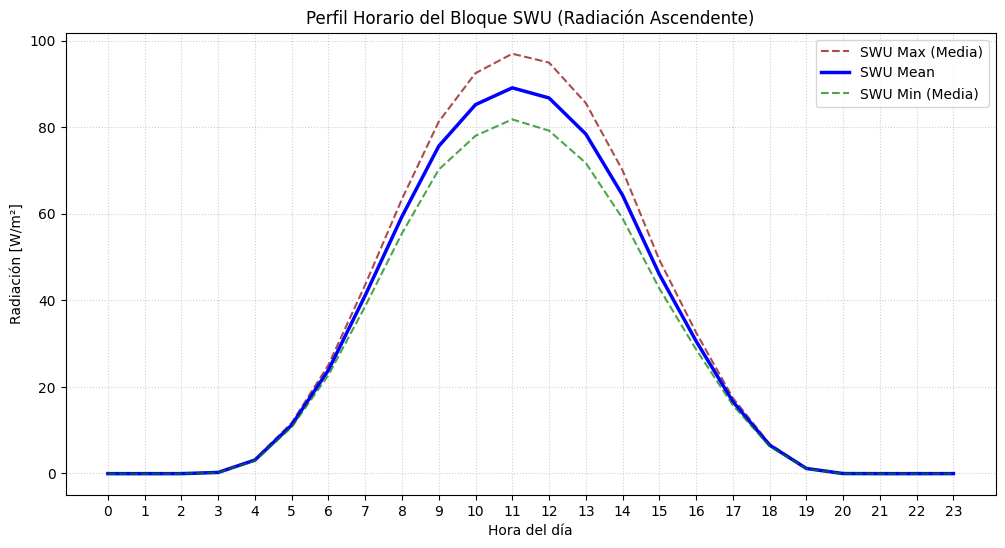

--- Análisis de Coherencia (Total registros: 569748) ---
Violaciones de la lógica min <= media <= max: 0
Violaciones de std dev >= 0: 0


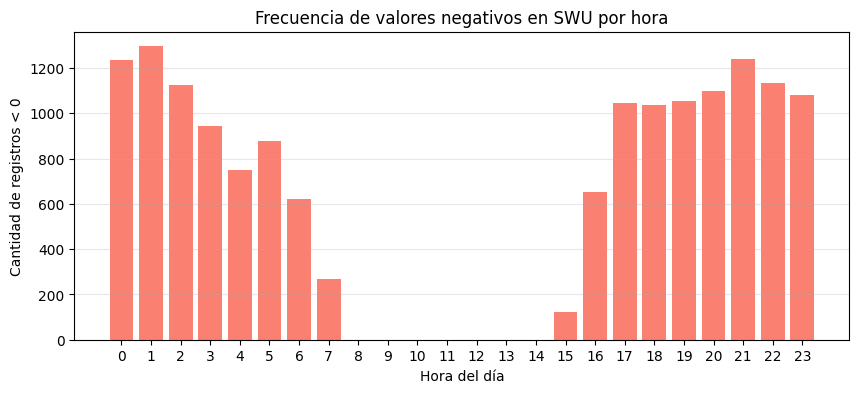

In [78]:
# Variables del bloque SWU
col_swu = 'SWU [W/m**2]'
col_swu_min = 'SWU min [W/m**2]'
col_swu_max = 'SWU max [W/m**2]'
col_swu_std = 'SWU std dev [W/m**2]'
cols_swu = [col_swu, col_swu_min, col_swu_max, col_swu_std]

# 2. Resumen estadístico horario del bloque
resumen_swu = df.groupby('hour')[cols_swu].mean()

print("Estadísticas horarias medias para el bloque SWU:")
display(df.groupby('hour')[col_swu].agg(['count', 'mean', 'std', 'min', 'max']).head())

# 3. Perfil horario comparativo
plt.figure(figsize=(12, 6))

plt.plot(resumen_swu.index, resumen_swu[col_swu_max], label='SWU Max (Media)', color='darkred', linestyle='--', alpha=0.7)
plt.plot(resumen_swu.index, resumen_swu[col_swu], label='SWU Mean', color='blue', linewidth=2.5)
plt.plot(resumen_swu.index, resumen_swu[col_swu_min], label='SWU Min (Media)', color='green', linestyle='--', alpha=0.7)

plt.title("Perfil Horario del Bloque SWU (Radiación Ascendente)")
plt.xlabel("Hora del día")
plt.ylabel("Radiación [W/m²]")
plt.xticks(range(24))
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()
plt.show()

# 4. Coherencia entre estadísticos (min <= media <= max)
df_swu_valid = df[cols_swu].dropna()
violaciones_rango = df_swu_valid[~((df_swu_valid[col_swu_min] <= df_swu_valid[col_swu]) &
                                 (df_swu_valid[col_swu] <= df_swu_valid[col_swu_max]))]

violaciones_std = df_swu_valid[df_swu_valid[col_swu_std] < 0]

print(f"--- Análisis de Coherencia (Total registros: {len(df_swu_valid)}) ---")
print(f"Violaciones de la lógica min <= media <= max: {len(violaciones_rango)}")
print(f"Violaciones de std dev >= 0: {len(violaciones_std)}")

# 5. Valores negativos
negativos_swu = df[df[col_swu] < 0].groupby('hour').size().reindex(range(24), fill_value=0)

plt.figure(figsize=(10, 4))
plt.bar(negativos_swu.index, negativos_swu.values, color='salmon')
plt.title("Frecuencia de valores negativos en SWU por hora")
plt.xlabel("Hora del día")
plt.ylabel("Cantidad de registros < 0")
plt.xticks(range(24))
plt.grid(True, axis='y', alpha=0.3)
plt.show()

## 9. Radiación de onda larga ascendente (LWU)

,count,mean,median,min,max
hour,,,,,
0,23760,356.958460,357.0,277.0,432.0
1,23755,356.745906,358.0,274.0,429.0
2,23760,355.870539,357.0,267.0,418.0
3,23760,355.878788,357.0,266.0,418.0
4,23760,356.958880,359.0,267.0,418.0
5,23756,360.404740,361.0,267.0,430.0
6,23741,365.447327,363.0,267.0,448.0
7,23672,372.138053,366.0,272.0,473.0
8,23633,379.432954,373.0,272.0,489.0


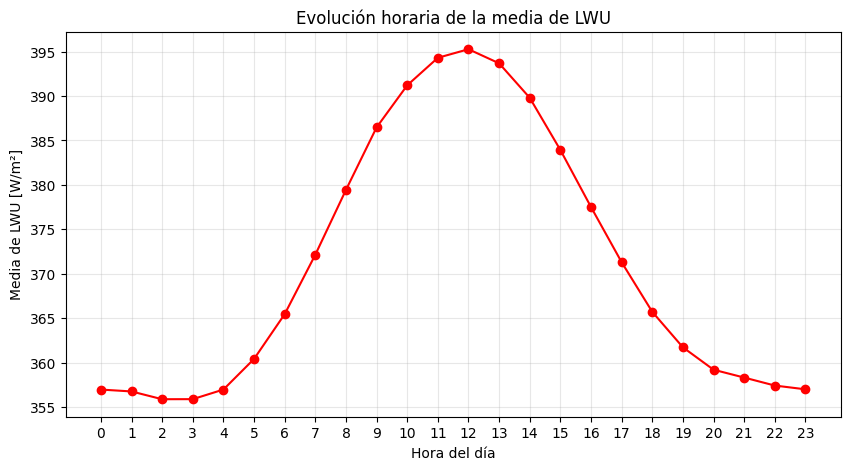

In [79]:
col_lwu = "LWU [W/m**2]"

# 1. Resumen estadístico por hora
resumen_horario_lwu = (
    df.groupby("hour")[col_lwu]
    .agg(
        count="count",
        mean="mean",
        median="median",
        min="min",
        max="max"
    )
    .reindex(range(24))
)

display(resumen_horario_lwu)

# 2. Evolución horaria de la media
plt.figure(figsize=(10, 5))
plt.plot(
    resumen_horario_lwu.index,
    resumen_horario_lwu["mean"],
    marker="o",
    color='red'
)

plt.title("Evolución horaria de la media de LWU")
plt.xlabel("Hora del día")
plt.ylabel("Media de LWU [W/m²]")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.show()

La variable `LWU [W/m²]`, correspondiente a la radiación de onda larga ascendente, presenta un comportamiento estable y físicamente coherente dentro del conjunto de datos. A diferencia de las variables de radiación de onda corta, como `SWD`, `DIR`, `DIF` o `SWU`, esta variable no presenta valores nulos ni negativos. Este comportamiento resulta esperable, ya que la radiación de onda larga ascendente está asociada a la emisión térmica de la superficie terrestre, por lo que no desaparece durante la noche y debe mantenerse siempre en valores positivos.

Desde el punto de vista estadístico, `LWU` presenta un valor mínimo de 266 W/m² y un máximo de 540 W/m². La media se sitúa en 370,93 W/m² y la mediana en 366 W/m², valores relativamente próximos entre sí, lo que indica una distribución bastante equilibrada. El primer cuartil se sitúa en 347 W/m² y el tercer cuartil en 392 W/m², con un rango intercuartílico de 45 W/m². Además, el percentil 5 es de 315 W/m² y el percentil 95 alcanza 441 W/m², lo que muestra que la mayor parte de las observaciones se concentran en un intervalo relativamente acotado.

El histograma muestra una distribución unimodal y aproximadamente acampanada, con la mayor concentración de registros alrededor de los 350–370 W/m². No obstante, se aprecia una ligera asimetría hacia la derecha, coherente con el coeficiente de asimetría positivo observado. Esta cola hacia valores altos puede estar asociada a episodios de mayor calentamiento de la superficie, especialmente durante periodos diurnos con mayor radiación solar incidente. Aun así, no se observan valores extremos claramente anómalos, ya que los máximos aparecen con muy baja frecuencia y se mantienen dentro de un rango físicamente razonable.

El análisis horario muestra un patrón diario claro y coherente. La media de `LWU` se mantiene en valores más bajos durante la noche, alrededor de 356–357 W/m², y aumenta progresivamente desde las primeras horas de la mañana hasta alcanzar su máximo en torno a las horas centrales del día, con valores cercanos a 395 W/m². Posteriormente, la variable desciende de forma gradual durante la tarde y vuelve a estabilizarse durante la noche. Este comportamiento es esperable, ya que la emisión de onda larga ascendente está relacionada con la temperatura de la superficie, la cual aumenta durante el día por efecto de la radiación solar y disminuye posteriormente durante el periodo nocturno.

En cuanto a la calidad de los datos, `LWU` presenta únicamente 500 valores ausentes, equivalentes aproximadamente al 0,1 % del total de registros. Además, no se detectan valores negativos, valores iguales a cero ni valores infinitos. Esto indica una elevada completitud y una buena coherencia física de la variable. En comparación con otras variables del dataset, `LWU` no requiere tratamientos específicos relacionados con ceros o valores negativos, aunque sus valores ausentes deberán revisarse posteriormente dentro del análisis conjunto de completitud.

En conjunto, `LWU [W/m²]` puede considerarse una variable de buena calidad, estable y físicamente consistente. Su distribución es mucho más regular que la de las variables de onda corta y su evolución horaria refleja adecuadamente el ciclo térmico diario de la superficie. Por tanto, se trata de una variable potencialmente útil para el modelado, especialmente como indicador indirecto del estado térmico de la superficie y de las condiciones energéticas del entorno.

### Bloque LWU: perfil horario y coherencia

Estadísticas horarias para LWU (Mean):


,count,mean,std,min,max
hour,,,,,
0,23760,356.958460,26.895285,277.0,432.0
1,23755,356.745906,26.862637,274.0,429.0
2,23760,355.870539,26.810892,267.0,418.0
3,23760,355.878788,26.580189,266.0,418.0
4,23760,356.958880,27.125411,267.0,418.0
5,23756,360.404740,29.575234,267.0,430.0
6,23741,365.447327,32.877458,267.0,448.0
7,23672,372.138053,36.650554,272.0,473.0
8,23633,379.432954,39.553102,272.0,489.0


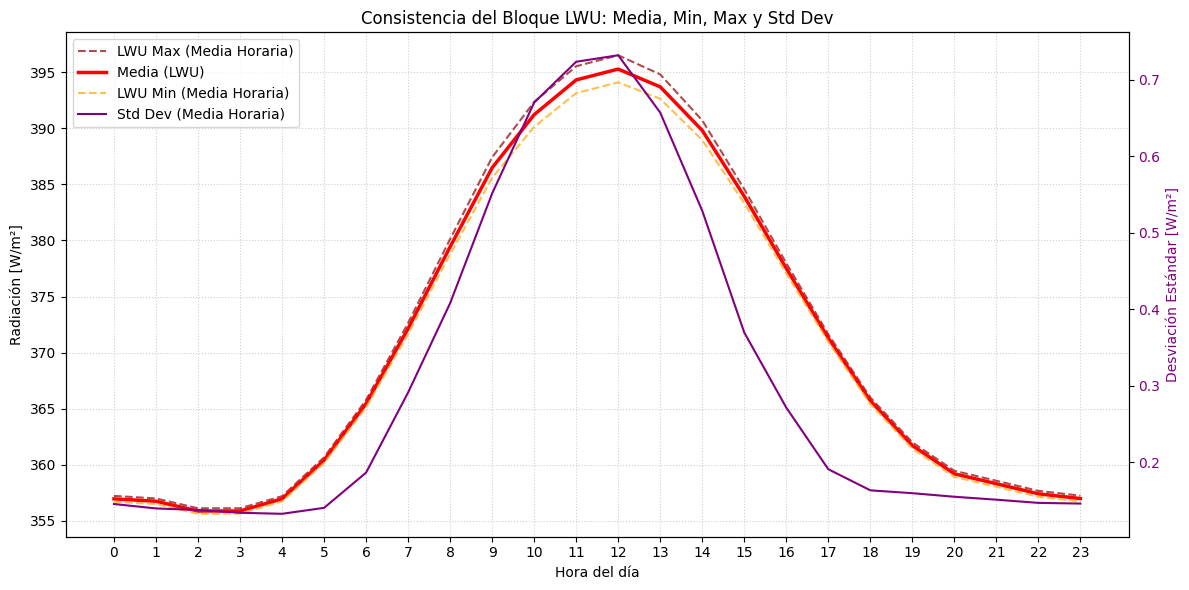


--- Análisis de Coherencia LWU (Registros válidos: 569740) ---
Violaciones de la lógica min <= media <= max: 0
Violaciones de std dev >= 0: 0
CONCLUSIÓN: Se confirma la coherencia matemática en el bloque LWU.


In [80]:
# Variables del bloque LWU
col_lwu = 'LWU [W/m**2]'
col_lwu_min = 'LWU min [W/m**2]'
col_lwu_max = 'LWU max [W/m**2]'
col_lwu_std = 'LWU std dev [W/m**2]'
cols_lwu = [col_lwu, col_lwu_min, col_lwu_max, col_lwu_std]

# 2. Resumen estadístico horario del bloque
resumen_lwu_stats = df.groupby('hour')[col_lwu].agg(['count', 'mean', 'std', 'min', 'max'])
print("Estadísticas horarias para LWU (Mean):")
display(resumen_lwu_stats)

# 3. Perfil horario comparativo
perfil_lwu = df.groupby('hour')[cols_lwu].mean()

fig, ax1 = plt.subplots(figsize=(12, 6))

# Eje principal: media, mínimo y máximo
ax1.plot(perfil_lwu.index, perfil_lwu[col_lwu_max], label='LWU Max (Media Horaria)', color='darkred', linestyle='--', alpha=0.7)
ax1.plot(perfil_lwu.index, perfil_lwu[col_lwu], label='Media (LWU)', color='red', linewidth=2.5)
ax1.plot(perfil_lwu.index, perfil_lwu[col_lwu_min], label='LWU Min (Media Horaria)', color='orange', linestyle='--', alpha=0.7)

ax1.set_xlabel('Hora del día')
ax1.set_ylabel('Radiación [W/m²]')
ax1.set_xticks(range(24))
ax1.grid(True, linestyle=':', alpha=0.6)

# Eje secundario para la desviación típica
ax2 = ax1.twinx()
ax2.plot(perfil_lwu.index, perfil_lwu[col_lwu_std], label='Std Dev (Media Horaria)', color='purple', linewidth=1.5)
ax2.set_ylabel('Desviación Estándar [W/m²]', color='purple')
ax2.tick_params(axis='y', labelcolor='purple')

plt.title('Consistencia del Bloque LWU: Media, Min, Max y Std Dev')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

plt.tight_layout()
plt.show()

# 4. Coherencia entre estadísticos (min <= media <= max)
df_lwu_valid = df[cols_lwu].dropna()
violaciones_rango_lwu = df_lwu_valid[~((df_lwu_valid[col_lwu_min] <= df_lwu_valid[col_lwu]) &
                                     (df_lwu_valid[col_lwu] <= df_lwu_valid[col_lwu_max]))]

violaciones_std_lwu = df_lwu_valid[df_lwu_valid[col_lwu_std] < 0]

print(f"\n--- Análisis de Coherencia LWU (Registros válidos: {len(df_lwu_valid)}) ---")
print(f"Violaciones de la lógica min <= media <= max: {len(violaciones_rango_lwu)}")
print(f"Violaciones de std dev >= 0: {len(violaciones_std_lwu)}")

if len(violaciones_rango_lwu) == 0 and len(violaciones_std_lwu) == 0:
    print("CONCLUSIÓN: Se confirma la coherencia matemática en el bloque LWU.")

## 10. Temperatura del aire (T2)

La variable `T2 [°C]`, correspondiente a la temperatura del aire medida a dos metros de altura, presenta una distribución aproximadamente simétrica y con una forma cercana a la acampanada. La media se sitúa en 11,54 °C y la mediana en 11,1 °C, mostrando una diferencia reducida entre ambas medidas de tendencia central. Asimismo, el coeficiente de asimetría, con un valor de 0,11, indica una ligera asimetría positiva que no resulta especialmente relevante.

La variable presenta una desviación típica de 6,10 °C. El primer cuartil se sitúa en 7,5 °C y el tercer cuartil en 15,7 °C, por lo que el 50 % central de las observaciones se encuentra comprendido en un intervalo de 8,2 °C. Por su parte, el percentil 5 es de 1,6 °C y el percentil 95 de 21,9 °C, indicando que la mayor parte de los registros se concentra dentro de un intervalo térmico relativamente moderado.

Los valores registrados oscilan entre un mínimo de −7,8 °C y un máximo de 31,2 °C. A diferencia de lo observado en las variables radiométricas, los valores negativos no deben interpretarse como errores instrumentales, ya que las temperaturas inferiores a 0 °C son físicamente posibles. En concreto, se observan 14.608 registros negativos, equivalentes aproximadamente al 2,6 % del total. Los valores iguales a cero, que representan únicamente alrededor del 0,1 %, también corresponden a mediciones válidas.

El histograma muestra una distribución global relativamente regular, aunque no perfectamente normal. Esta diferencia puede explicarse porque la distribución conjunta integra observaciones correspondientes a diferentes estaciones del año y franjas horarias. La temperatura presenta tanto un ciclo diario como una marcada componente estacional, por lo que la distribución global constituye una combinación de distintos regímenes térmicos.

La variable dispone de 391 valores distintos dentro de un rango de 39 °C, lo que resulta compatible con una resolución instrumental o un redondeo de 0,1 °C. No se observan valores infinitos y únicamente se registran 360 valores ausentes, equivalentes aproximadamente al 0,1 % del conjunto de datos. Por tanto, la variable presenta una elevada completitud y no muestra, en este análisis inicial, indicios evidentes de problemas relevantes de calidad.

En conjunto, `T2 [°C]` puede considerarse una variable de buena calidad, con una distribución estadística estable y valores físicamente plausibles. No obstante, será necesario estudiar su evolución temporal, especialmente sus ciclos horario y estacional, y comprobar si los valores extremos corresponden a episodios meteorológicos reales o a posibles anomalías puntuales.

### Perfil horario

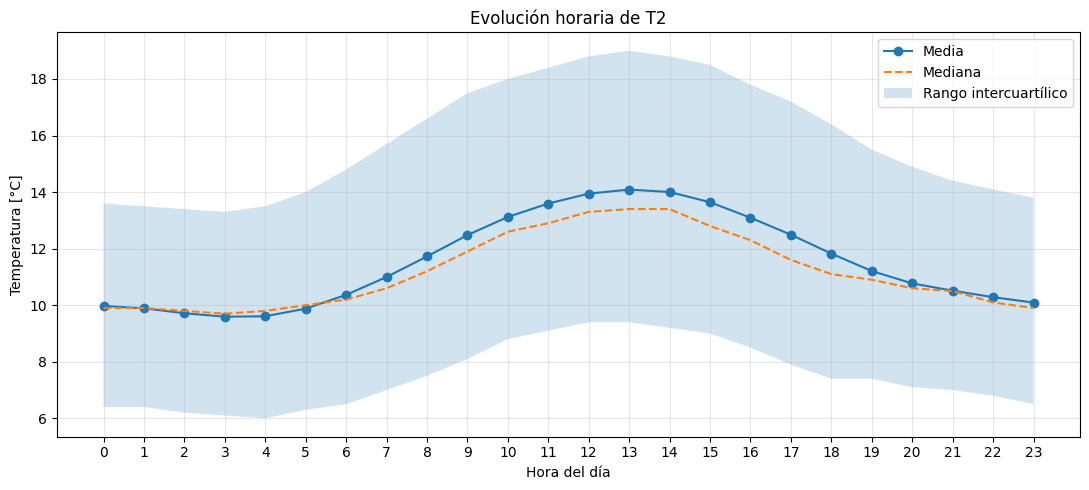

In [81]:
date_col = "Date/Time"
t2_col = "T2 [°C]"

df[date_col] = pd.to_datetime(df[date_col])
df["hour"] = df[date_col].dt.hour

t2_hourly = (
    df.groupby("hour")[t2_col]
    .agg(
        media="mean",
        mediana="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

plt.figure(figsize=(11, 5))

plt.plot(
    t2_hourly["hour"],
    t2_hourly["media"],
    marker="o",
    label="Media"
)

plt.plot(
    t2_hourly["hour"],
    t2_hourly["mediana"],
    linestyle="--",
    label="Mediana"
)

plt.fill_between(
    t2_hourly["hour"],
    t2_hourly["q25"],
    t2_hourly["q75"],
    alpha=0.2,
    label="Rango intercuartílico"
)

plt.title("Evolución horaria de T2")
plt.xlabel("Hora del día")
plt.ylabel("Temperatura [°C]")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Distribución mensual

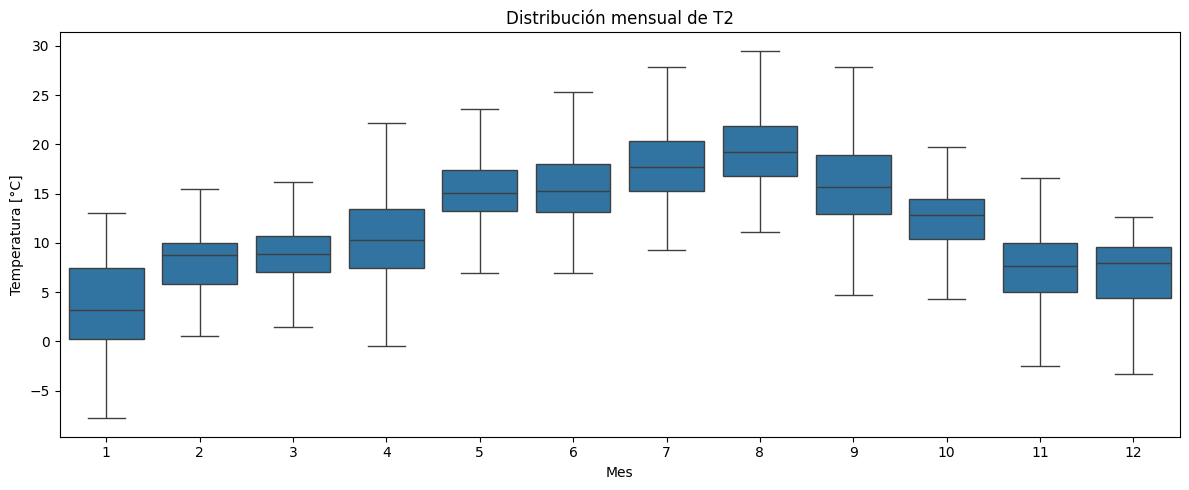

In [82]:
df["month"] = df[date_col].dt.month

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=df,
    x="month",
    y=t2_col,
    showfliers=False
)

plt.title("Distribución mensual de T2")
plt.xlabel("Mes")
plt.ylabel("Temperatura [°C]")
plt.tight_layout()
plt.show()

### Evolución diaria

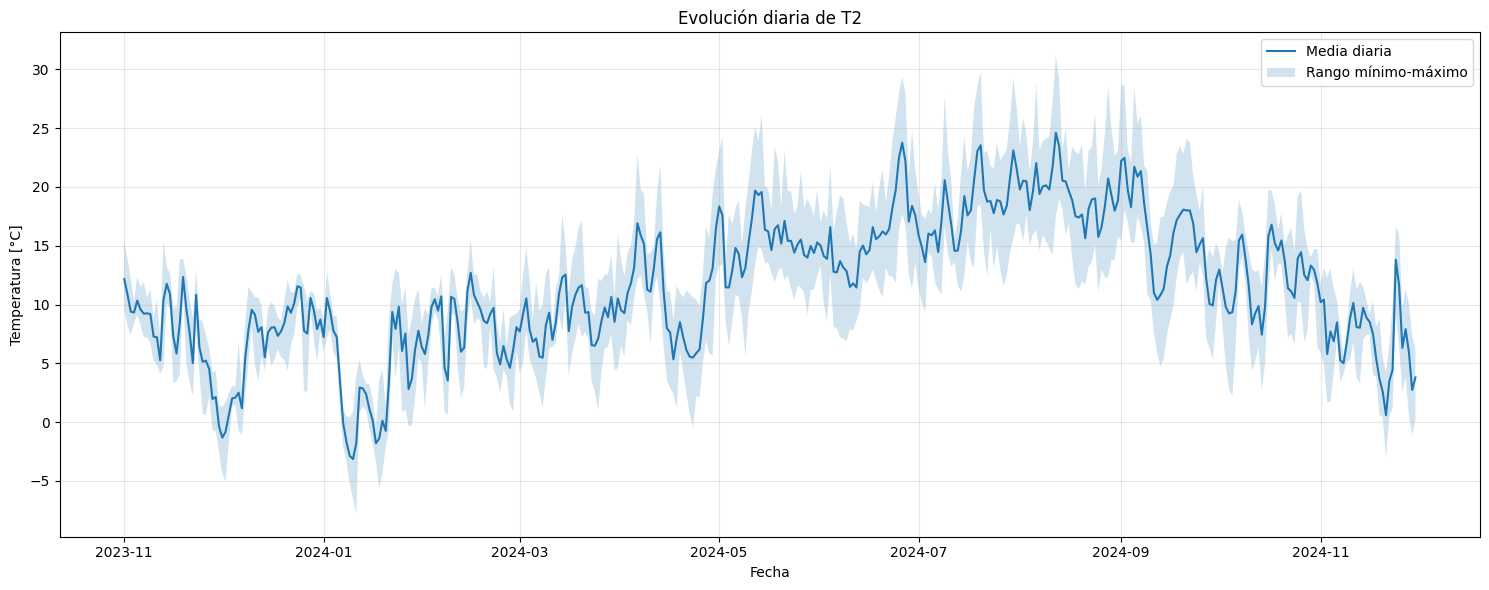

In [83]:
t2_daily = (
    df.set_index(date_col)[t2_col]
    .resample("D")
    .agg(
        media="mean",
        minima="min",
        maxima="max"
    )
)

plt.figure(figsize=(15, 6))

plt.plot(t2_daily.index, t2_daily["media"], label="Media diaria")
plt.fill_between(
    t2_daily.index,
    t2_daily["minima"],
    t2_daily["maxima"],
    alpha=0.2,
    label="Rango mínimo-máximo"
)

plt.title("Evolución diaria de T2")
plt.xlabel("Fecha")
plt.ylabel("Temperatura [°C]")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Valores extremos

Los valores fuera de 1,5 veces el rango intercuartílico se examinan, sin eliminarlos, para comprobar si responden a episodios meteorológicos plausibles.

In [84]:
q1 = df[t2_col].quantile(0.25)
q3 = df[t2_col].quantile(0.75)
iqr = q3 - q1

lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

t2_extremes = df.loc[
    (df[t2_col] < lower_limit) |
    (df[t2_col] > upper_limit),
    [date_col, t2_col]
].copy()

print(f"Límite inferior: {lower_limit:.2f} °C")
print(f"Límite superior: {upper_limit:.2f} °C")
print(f"Número de observaciones extremas: {len(t2_extremes)}")

t2_extremes.head()

Límite inferior: -4.80 °C
Límite superior: 28.00 °C
Número de observaciones extremas: 3323


,Date/Time,T2 [°C]
44849,2023-12-02 03:29:00,-4.9
44850,2023-12-02 03:30:00,-4.9
44851,2023-12-02 03:31:00,-4.8
44854,2023-12-02 03:34:00,-4.8
44855,2023-12-02 03:35:00,-4.8


month
1     1209
6      284
7      730
8      802
9      269
12      29
dtype: int64


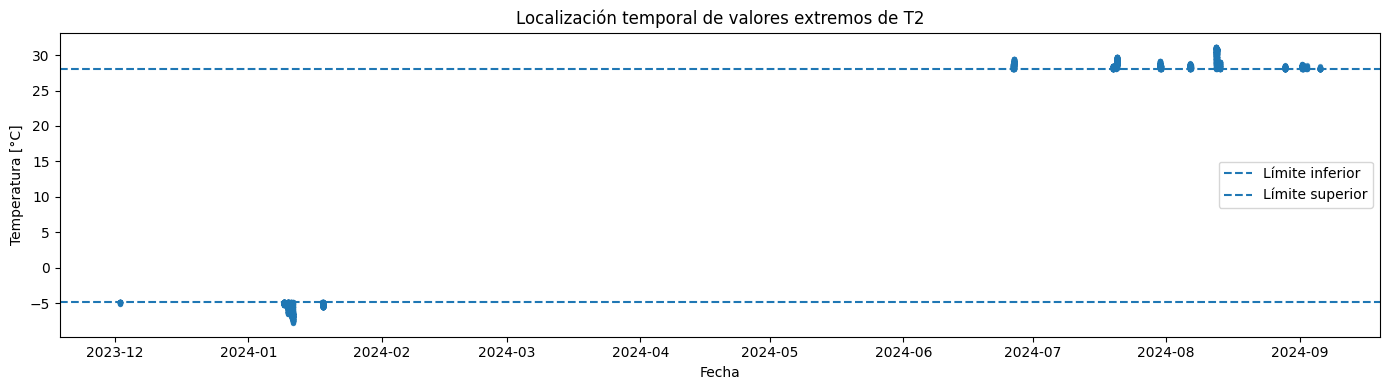

In [85]:
t2_extremes["month"] = t2_extremes[date_col].dt.month

print(t2_extremes.groupby("month").size())

plt.figure(figsize=(14, 4))
plt.scatter(
    t2_extremes[date_col],
    t2_extremes[t2_col],
    s=8,
    alpha=0.6
)

plt.axhline(lower_limit, linestyle="--", label="Límite inferior")
plt.axhline(upper_limit, linestyle="--", label="Límite superior")

plt.title("Localización temporal de valores extremos de T2")
plt.xlabel("Fecha")
plt.ylabel("Temperatura [°C]")
plt.legend()
plt.tight_layout()
plt.show()

El análisis temporal de la variable `T2 [°C]` muestra la existencia de patrones diarios y estacionales claramente definidos. En primer lugar, la evolución horaria presenta un ciclo térmico diario coherente: la temperatura media disminuye durante la noche hasta alcanzar sus valores mínimos aproximadamente entre las 03:00 y las 04:00, momento a partir del cual comienza a aumentar progresivamente. Los valores medios máximos se registran entre las 13:00 y las 14:00, alcanzando aproximadamente 14 °C, tras lo cual se observa un descenso gradual durante la tarde y la noche.

El hecho de que el máximo de temperatura se produzca después de las horas de máxima radiación solar puede explicarse por la inercia térmica de la superficie terrestre y de la atmósfera. Aunque la energía solar incidente comienza a disminuir después del mediodía, la superficie continúa acumulando y liberando calor durante varias horas. La amplitud media del ciclo diario es moderada, con una diferencia aproximada de 4,5 °C entre las horas más frías y más cálidas.

La proximidad entre la media y la mediana horarias confirma que la distribución de la temperatura es relativamente equilibrada en las distintas franjas del día. No obstante, durante las horas centrales la media se sitúa ligeramente por encima de la mediana, lo que puede indicar la presencia de algunos episodios de temperaturas elevadas. El rango intercuartílico muestra además una dispersión considerable, explicable porque cada hora agrupa observaciones pertenecientes a diferentes estaciones del año.

El análisis mensual evidencia una marcada estacionalidad anual. Las temperaturas más bajas se registran durante los meses de invierno, especialmente en enero, cuya mediana se sitúa alrededor de 3 °C y donde aparecen registros inferiores a 0 °C. Desde febrero se observa un aumento progresivo de la temperatura, que continúa durante la primavera y alcanza sus valores máximos en verano. Agosto es el mes más cálido, con una mediana próxima a 19 °C y valores máximos cercanos a 30 °C. A partir de septiembre, las temperaturas vuelven a descender gradualmente hasta alcanzar los niveles propios del periodo invernal.

Por tanto, durante el invierno no necesariamente disminuye la variabilidad de la temperatura, sino principalmente su nivel central. Algunos meses fríos, especialmente enero, presentan una amplitud térmica considerable, combinando episodios de temperaturas negativas con otros de carácter más moderado. Durante el verano también se observa dispersión, aunque la distribución completa se desplaza hacia valores más altos.

La evolución de las medias diarias confirma el patrón estacional identificado. Al inicio del periodo analizado se observan episodios fríos durante diciembre de 2023 y enero de 2024, con medias diarias próximas o inferiores a 0 °C. Posteriormente, la temperatura aumenta progresivamente durante la primavera, alcanza sus valores más elevados entre julio y agosto y comienza a descender a partir de septiembre. Sobre esta tendencia anual aparecen fluctuaciones de corta duración, atribuibles a la variabilidad meteorológica diaria.

La aplicación del criterio del rango intercuartílico identifica 3.323 observaciones situadas fuera de los límites globales de −4,8 °C y 28 °C. Sin embargo, estos valores extremos presentan una clara agrupación estacional. Las temperaturas inferiores al límite se concentran durante diciembre y enero, mientras que las superiores a 28 °C aparecen principalmente durante los meses de verano. Esta concentración temporal sugiere que una parte importante de los valores identificados como atípicos corresponde a episodios meteorológicos reales y no a errores del sensor.

En consecuencia, no se considera adecuado eliminar automáticamente estas observaciones utilizando únicamente límites calculados sobre la distribución global. Para evaluar posibles anomalías de forma más precisa, sería preferible aplicar criterios específicos por mes o estación del año, así como comprobar la continuidad temporal de los registros extremos. En conjunto, `T2 [°C]` presenta un comportamiento temporal coherente, una estacionalidad marcada y una calidad de datos elevada.

## 11. Humedad relativa (RH)

La variable `RH [%]`, correspondiente a la humedad relativa del aire, presenta una elevada calidad general. Los valores registrados se encuentran comprendidos entre el 37 % y el 100 %, por lo que no se detectan observaciones fuera de sus límites físicos. Asimismo, la variable no presenta valores negativos, infinitos ni iguales a cero, y únicamente contiene 394 valores ausentes, equivalentes aproximadamente al 0,1 % del conjunto de datos.

La media de la humedad relativa es del 85,0 %, mientras que la mediana se sitúa en el 88 %. El primer cuartil alcanza el 78 % y el tercer cuartil el 95 %, por lo que el 50 % central de los registros se encuentra concentrado en niveles elevados de humedad. Estos resultados indican que durante el periodo analizado predominan condiciones ambientales húmedas.

La distribución presenta una marcada asimetría hacia la izquierda, con un coeficiente de asimetría de −0,93. La mayor parte de las observaciones se concentra en valores altos, mientras que la cola de la distribución se extiende hacia humedades más bajas. Por tanto, la variable no sigue una distribución normal, sino una distribución limitada superiormente por el 100 % y caracterizada por una acumulación de observaciones próximas a la saturación.

El valor más frecuente es el 100 %, que representa aproximadamente el 6,6 % de los registros. Esta concentración puede estar asociada a condiciones atmosféricas reales próximas a la saturación, como niebla, rocío, precipitación o elevada humedad nocturna. No obstante, también debe considerarse el posible efecto techo del sensor, ya que los valores que alcanzan el límite superior quedan registrados exactamente como 100 %. Por este motivo, resulta conveniente estudiar su distribución horaria y mensual, así como la duración de los periodos consecutivos de saturación.

Aunque la variable muestra una dispersión moderada y una elevada concentración de valores entre el 78 % y el 95 %, su estabilidad temporal deberá evaluarse mediante el análisis de sus ciclos diario y estacional. Se espera que la humedad relativa alcance valores más elevados durante la noche y primeras horas de la mañana, y disminuya durante las horas de mayor temperatura. En conjunto, la variable presenta una elevada completitud, valores físicamente plausibles y ausencia de anomalías evidentes en esta primera fase del análisis exploratorio.

### Perfil horario

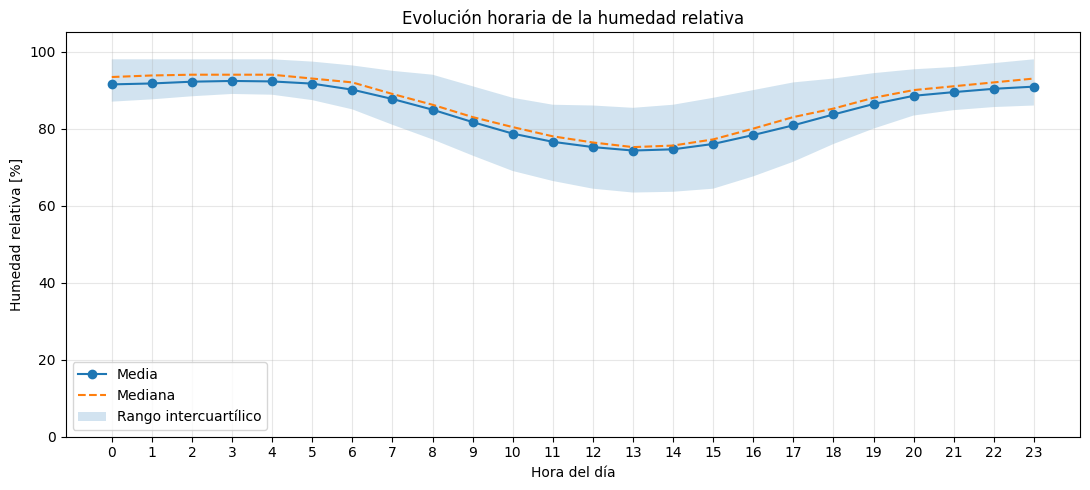

In [86]:
date_col = "Date/Time"
rh_col = "RH [%]"

df[date_col] = pd.to_datetime(df[date_col])
df["hour"] = df[date_col].dt.hour

rh_hourly = (
    df.groupby("hour")[rh_col]
    .agg(
        media="mean",
        mediana="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75)
    )
    .reset_index()
)

plt.figure(figsize=(11, 5))

plt.plot(
    rh_hourly["hour"],
    rh_hourly["media"],
    marker="o",
    label="Media"
)

plt.plot(
    rh_hourly["hour"],
    rh_hourly["mediana"],
    linestyle="--",
    label="Mediana"
)

plt.fill_between(
    rh_hourly["hour"],
    rh_hourly["q25"],
    rh_hourly["q75"],
    alpha=0.2,
    label="Rango intercuartílico"
)

plt.title("Evolución horaria de la humedad relativa")
plt.xlabel("Hora del día")
plt.ylabel("Humedad relativa [%]")
plt.xticks(range(24))
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Distribución mensual

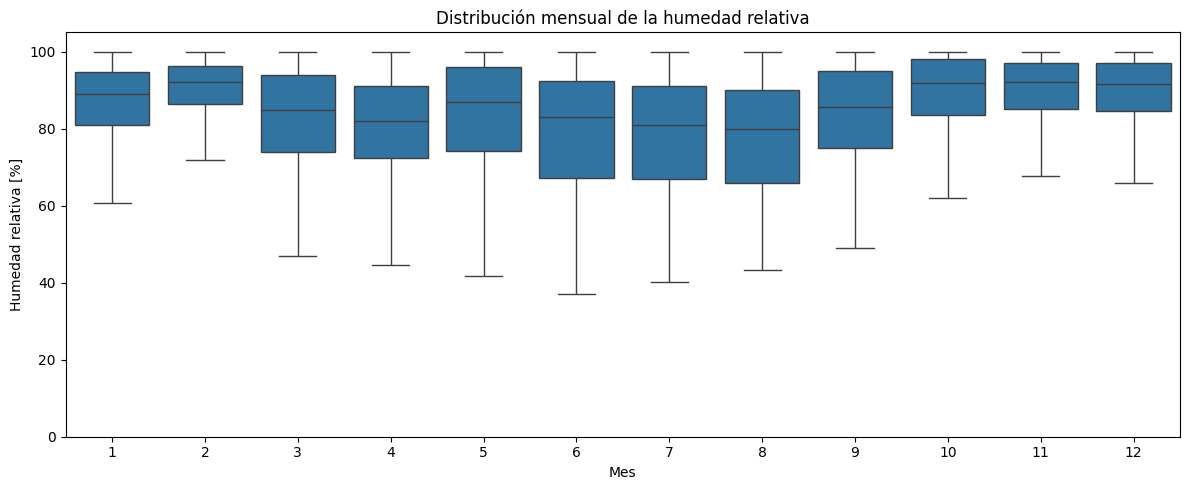

In [87]:
df["month"] = df[date_col].dt.month

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=df,
    x="month",
    y=rh_col,
    showfliers=False
)

plt.title("Distribución mensual de la humedad relativa")
plt.xlabel("Mes")
plt.ylabel("Humedad relativa [%]")
plt.ylim(0, 105)
plt.tight_layout()
plt.show()

### Registros próximos a la saturación por hora

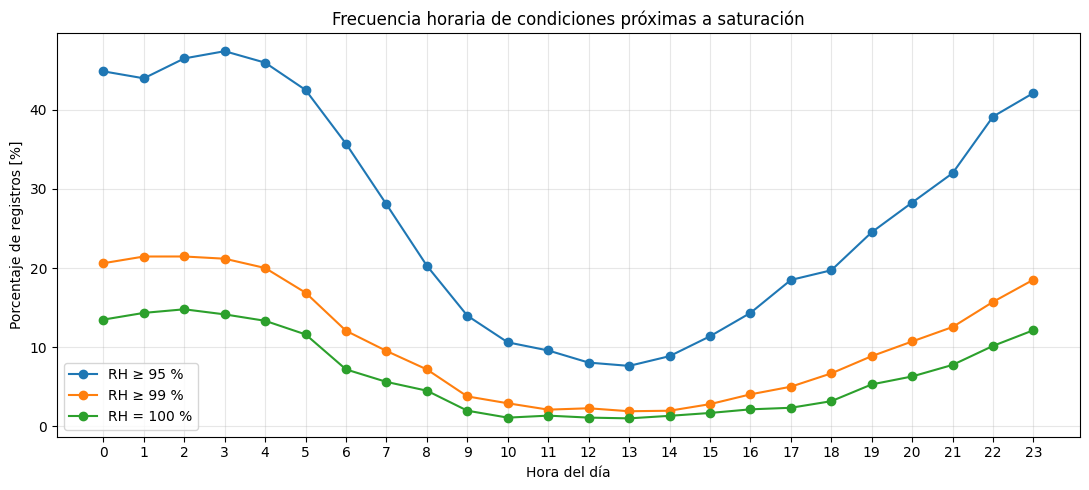

In [88]:
rh_saturation = (
    df.groupby("hour")[rh_col]
    .agg(
        pct_95=lambda x: (x >= 95).mean() * 100,
        pct_99=lambda x: (x >= 99).mean() * 100,
        pct_100=lambda x: (x == 100).mean() * 100
    )
    .reset_index()
)

plt.figure(figsize=(11, 5))

plt.plot(
    rh_saturation["hour"],
    rh_saturation["pct_95"],
    marker="o",
    label="RH ≥ 95 %"
)

plt.plot(
    rh_saturation["hour"],
    rh_saturation["pct_99"],
    marker="o",
    label="RH ≥ 99 %"
)

plt.plot(
    rh_saturation["hour"],
    rh_saturation["pct_100"],
    marker="o",
    label="RH = 100 %"
)

plt.title("Frecuencia horaria de condiciones próximas a saturación")
plt.xlabel("Hora del día")
plt.ylabel("Porcentaje de registros [%]")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Saturación por mes

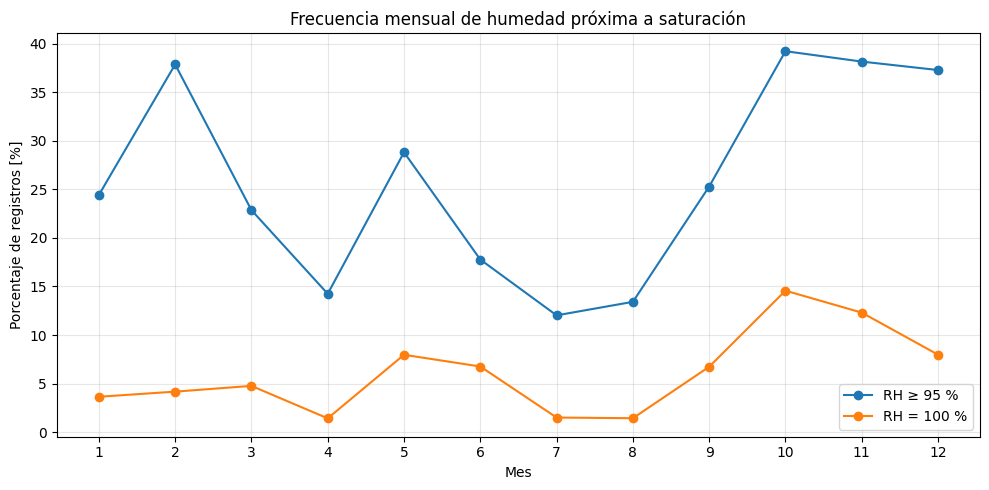

In [89]:
rh_monthly_saturation = (
    df.groupby("month")[rh_col]
    .agg(
        pct_95=lambda x: (x >= 95).mean() * 100,
        pct_100=lambda x: (x == 100).mean() * 100
    )
    .reset_index()
)

plt.figure(figsize=(10, 5))

plt.plot(
    rh_monthly_saturation["month"],
    rh_monthly_saturation["pct_95"],
    marker="o",
    label="RH ≥ 95 %"
)

plt.plot(
    rh_monthly_saturation["month"],
    rh_monthly_saturation["pct_100"],
    marker="o",
    label="RH = 100 %"
)

plt.title("Frecuencia mensual de humedad próxima a saturación")
plt.xlabel("Mes")
plt.ylabel("Porcentaje de registros [%]")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Evolución diaria

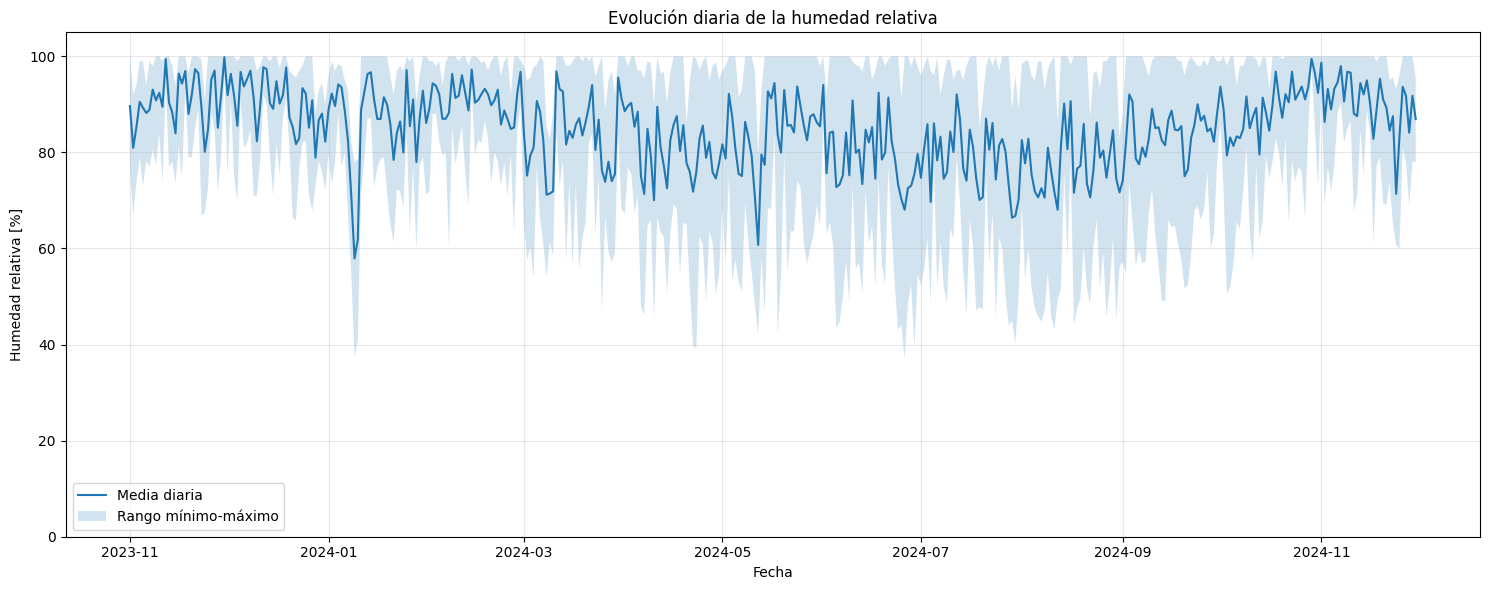

In [90]:
rh_daily = (
    df.set_index(date_col)[rh_col]
    .resample("D")
    .agg(
        media="mean",
        minima="min",
        maxima="max"
    )
)

plt.figure(figsize=(15, 6))

plt.plot(
    rh_daily.index,
    rh_daily["media"],
    label="Media diaria"
)

plt.fill_between(
    rh_daily.index,
    rh_daily["minima"],
    rh_daily["maxima"],
    alpha=0.2,
    label="Rango mínimo-máximo"
)

plt.title("Evolución diaria de la humedad relativa")
plt.xlabel("Fecha")
plt.ylabel("Humedad relativa [%]")
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Rachas de saturación (RH = 100 %)

In [91]:
date_col = "Date/Time"
rh_col = "RH [%]"

df[date_col] = pd.to_datetime(df[date_col], errors="coerce")

df_rh = (
    df[[date_col, rh_col]]
    .dropna(subset=[date_col])
    .sort_values(date_col)
    .reset_index(drop=True)
    .copy()
)

print(f"Número de registros: {len(df_rh):,}")
print(f"Valores ausentes de RH: {df_rh[rh_col].isna().sum():,}")

Número de registros: 570,240
Valores ausentes de RH: 394


In [92]:
time_diffs = df_rh[date_col].diff().dropna()

# Intervalo temporal más frecuente
expected_step = time_diffs.mode().iloc[0]

print("Frecuencia temporal detectada:", expected_step)

Frecuencia temporal detectada: 0 days 00:01:00


In [93]:
# Saturación: RH = 100 %
df_rh["is_rh_100"] = np.isclose(
    df_rh[rh_col],
    100,
    atol=1e-8,
    equal_nan=False
)

# Diferencia temporal respecto al registro anterior
df_rh["time_diff"] = df_rh[date_col].diff()

# Una observación continúa la racha anterior si:
# 1. La observación actual es RH = 100
# 2. La anterior también era RH = 100
# 3. La separación temporal es la esperada
continues_previous_run = (
    df_rh["is_rh_100"]
    & df_rh["is_rh_100"].shift(fill_value=False)
    & df_rh["time_diff"].eq(expected_step)
)

# Inicio de una nueva racha
df_rh["run_start"] = (
    df_rh["is_rh_100"]
    & ~continues_previous_run
)

# Identificador de racha
df_rh["run_id"] = df_rh["run_start"].cumsum()

In [94]:
rh_100_runs = (
    df_rh.loc[df_rh["is_rh_100"]]
    .groupby("run_id")
    .agg(
        inicio=(date_col, "min"),
        fin=(date_col, "max"),
        numero_registros=(rh_col, "size")
    )
    .reset_index(drop=True)
)

# Duración incluyendo el intervalo correspondiente al último registro
rh_100_runs["duracion"] = (
    rh_100_runs["fin"]
    - rh_100_runs["inicio"]
    + expected_step
)

rh_100_runs["duracion_minutos"] = (
    rh_100_runs["duracion"].dt.total_seconds() / 60
)

rh_100_runs["duracion_horas"] = (
    rh_100_runs["duracion_minutos"] / 60
)

rh_100_runs = rh_100_runs.sort_values(
    "duracion_minutos",
    ascending=False
).reset_index(drop=True)

print(f"Número total de rachas con RH = 100 %: {len(rh_100_runs):,}")
print(
    "Duración máxima:",
    round(rh_100_runs["duracion_horas"].max(), 2),
    "horas"
)
print(
    "Duración mediana:",
    round(rh_100_runs["duracion_minutos"].median(), 2),
    "minutos"
)
print(
    "Duración media:",
    round(rh_100_runs["duracion_minutos"].mean(), 2),
    "minutos"
)

rh_100_runs.head(20)

Número total de rachas con RH = 100 %: 2,070
Duración máxima: 8.3 horas
Duración mediana: 4.0 minutos
Duración media: 18.12 minutos


,inicio,fin,numero_registros,duracion,duracion_minutos,duracion_horas
0,2023-11-20 23:25:00,2023-11-21 07:42:00,498,0 days 08:18:00,498.0,8.300000
1,2023-12-07 04:19:00,2023-12-07 12:20:00,482,0 days 08:02:00,482.0,8.033333
2,2024-11-07 15:01:00,2024-11-07 23:00:00,480,0 days 08:00:00,480.0,8.000000
3,2024-10-23 22:03:00,2024-10-24 05:59:00,477,0 days 07:57:00,477.0,7.950000
4,2024-05-15 21:18:00,2024-05-16 05:11:00,474,0 days 07:54:00,474.0,7.900000
5,2024-01-12 23:15:00,2024-01-13 07:03:00,469,0 days 07:49:00,469.0,7.816667
6,2024-06-18 20:53:00,2024-06-19 04:19:00,447,0 days 07:27:00,447.0,7.450000
7,2024-05-23 22:40:00,2024-05-24 05:07:00,388,0 days 06:28:00,388.0,6.466667
8,2024-05-19 00:04:00,2024-05-19 06:29:00,386,0 days 06:26:00,386.0,6.433333
9,2023-11-30 20:46:00,2023-12-01 03:09:00,384,0 days 06:24:00,384.0,6.400000


In [95]:
run_duration_summary = pd.Series({
    "Rachas de 1 registro": (
        rh_100_runs["numero_registros"] == 1
    ).sum(),

    "Hasta 10 minutos": (
        (rh_100_runs["duracion_minutos"] > 1)
        & (rh_100_runs["duracion_minutos"] <= 10)
    ).sum(),

    "Entre 10 y 60 minutos": (
        (rh_100_runs["duracion_minutos"] > 10)
        & (rh_100_runs["duracion_minutos"] <= 60)
    ).sum(),

    "Entre 1 y 6 horas": (
        (rh_100_runs["duracion_horas"] > 1)
        & (rh_100_runs["duracion_horas"] <= 6)
    ).sum(),

    "Más de 6 horas": (
        rh_100_runs["duracion_horas"] > 6
    ).sum()
})

run_duration_summary

,0
Rachas de 1 registro,495
Hasta 10 minutos,949
Entre 10 y 60 minutos,504
Entre 1 y 6 horas,110
Más de 6 horas,12


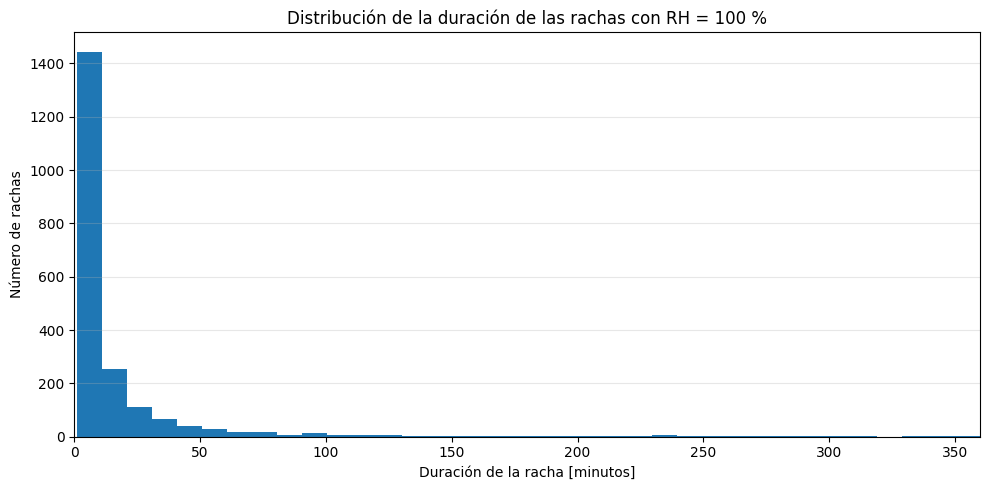

In [96]:
plt.figure(figsize=(10, 5))

plt.hist(
    rh_100_runs["duracion_minutos"],
    bins=50
)

plt.xlim(
    0,
    min(360, rh_100_runs["duracion_minutos"].max())
)

plt.title("Distribución de la duración de las rachas con RH = 100 %")
plt.xlabel("Duración de la racha [minutos]")
plt.ylabel("Número de rachas")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

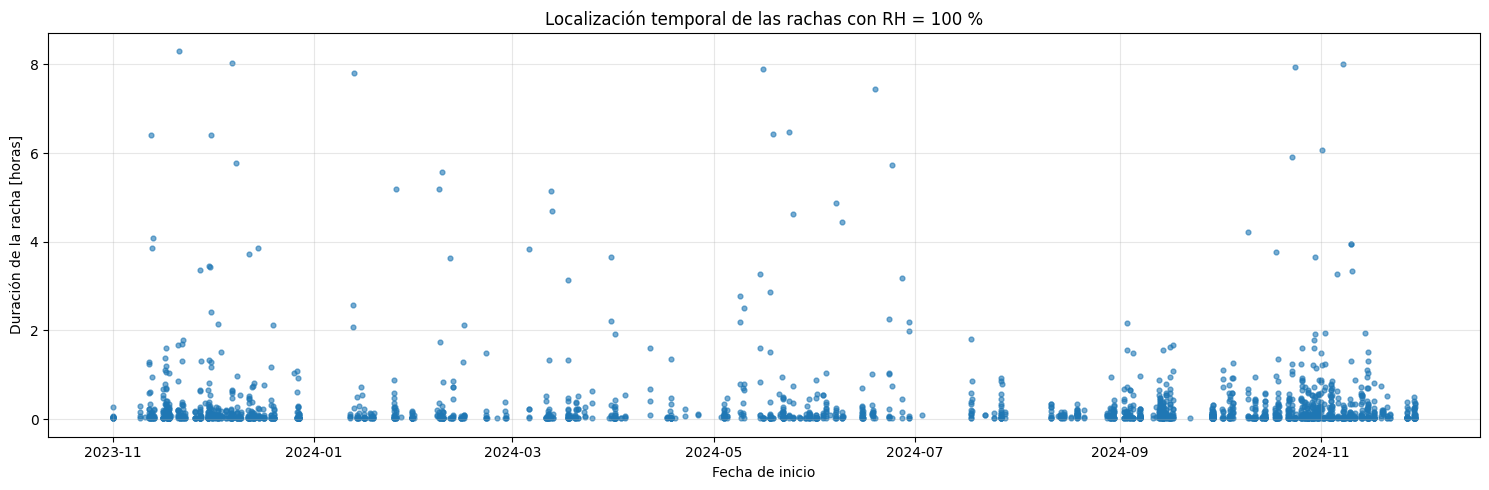

In [97]:
plt.figure(figsize=(15, 5))

plt.scatter(
    rh_100_runs["inicio"],
    rh_100_runs["duracion_horas"],
    s=12,
    alpha=0.6
)

plt.title("Localización temporal de las rachas con RH = 100 %")
plt.xlabel("Fecha de inicio")
plt.ylabel("Duración de la racha [horas]")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [98]:
long_runs = rh_100_runs.loc[
    rh_100_runs["duracion_horas"] >= 6
].copy()

print(
    f"Número de rachas de al menos 6 horas: "
    f"{len(long_runs)}"
)

long_runs

Número de rachas de al menos 6 horas: 12


,inicio,fin,numero_registros,duracion,duracion_minutos,duracion_horas
0,2023-11-20 23:25:00,2023-11-21 07:42:00,498,0 days 08:18:00,498.0,8.300000
1,2023-12-07 04:19:00,2023-12-07 12:20:00,482,0 days 08:02:00,482.0,8.033333
2,2024-11-07 15:01:00,2024-11-07 23:00:00,480,0 days 08:00:00,480.0,8.000000
3,2024-10-23 22:03:00,2024-10-24 05:59:00,477,0 days 07:57:00,477.0,7.950000
4,2024-05-15 21:18:00,2024-05-16 05:11:00,474,0 days 07:54:00,474.0,7.900000
5,2024-01-12 23:15:00,2024-01-13 07:03:00,469,0 days 07:49:00,469.0,7.816667
6,2024-06-18 20:53:00,2024-06-19 04:19:00,447,0 days 07:27:00,447.0,7.450000
7,2024-05-23 22:40:00,2024-05-24 05:07:00,388,0 days 06:28:00,388.0,6.466667
8,2024-05-19 00:04:00,2024-05-19 06:29:00,386,0 days 06:26:00,386.0,6.433333
9,2023-11-30 20:46:00,2023-12-01 03:09:00,384,0 days 06:24:00,384.0,6.400000


### Mapas de calor por mes y hora

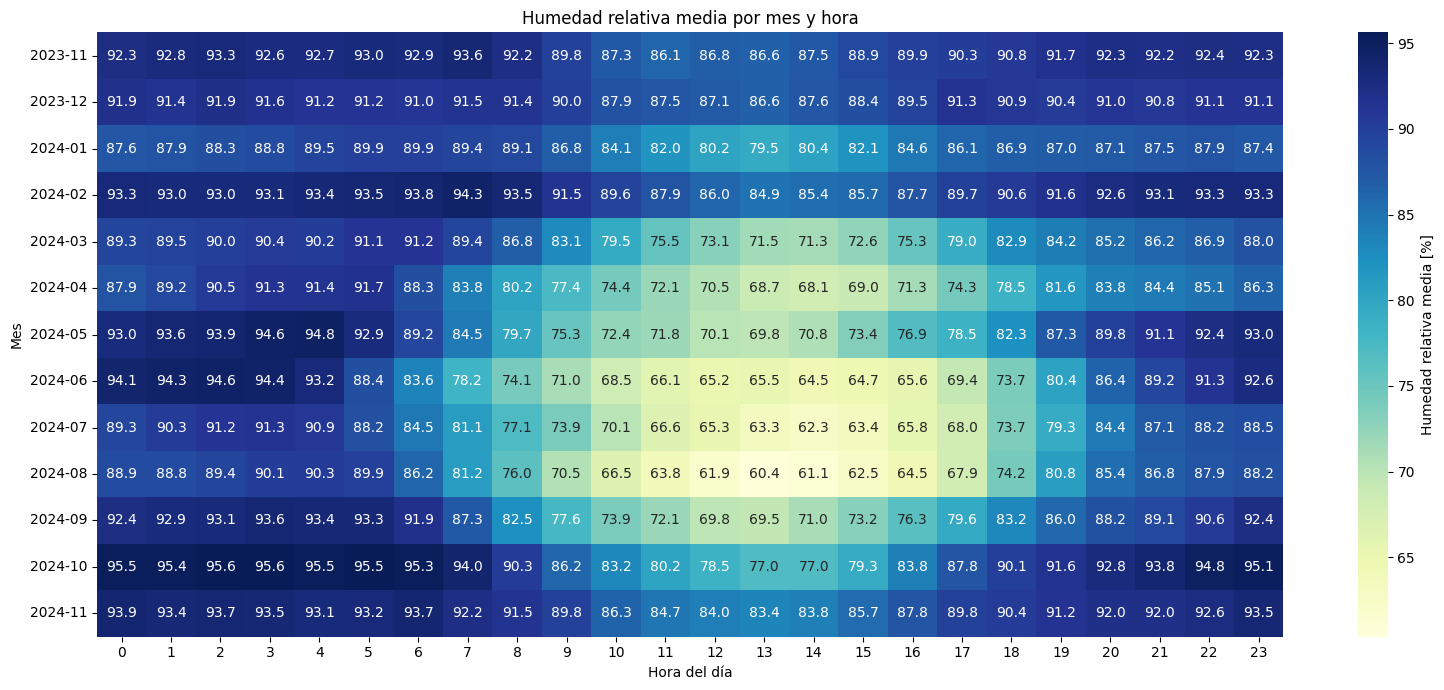

In [99]:
df_rh["hour"] = df_rh[date_col].dt.hour
df_rh["year_month"] = (
    df_rh[date_col]
    .dt.to_period("M")
    .astype(str)
)

rh_mean_heatmap = df_rh.pivot_table(
    index="year_month",
    columns="hour",
    values=rh_col,
    aggfunc="mean"
)

plt.figure(figsize=(16, 7))

sns.heatmap(
    rh_mean_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    cbar_kws={
        "label": "Humedad relativa media [%]"
    }
)

plt.title("Humedad relativa media por mes y hora")
plt.xlabel("Hora del día")
plt.ylabel("Mes")
plt.tight_layout()
plt.show()

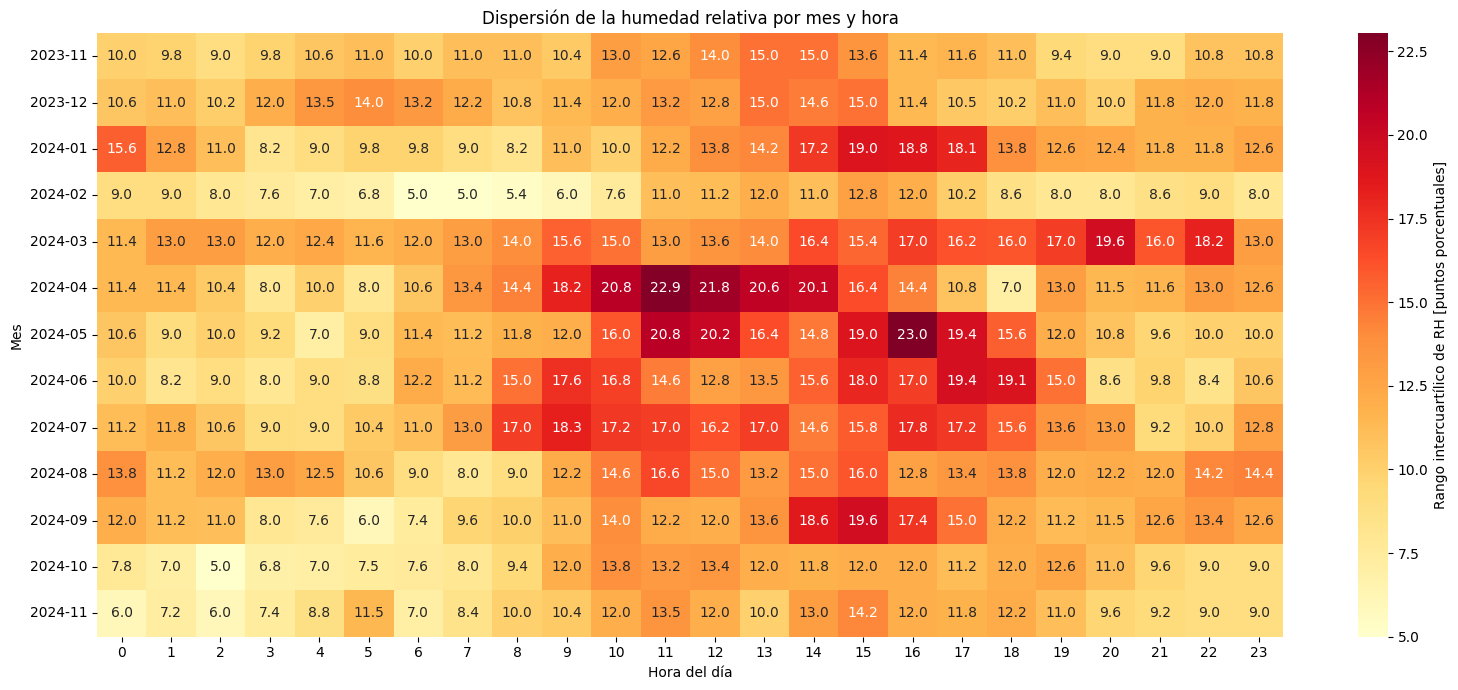

In [100]:
def interquartile_range(series):
    return series.quantile(0.75) - series.quantile(0.25)

rh_iqr_heatmap = df_rh.pivot_table(
    index="year_month",
    columns="hour",
    values=rh_col,
    aggfunc=interquartile_range
)

plt.figure(figsize=(16, 7))

sns.heatmap(
    rh_iqr_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    cbar_kws={
        "label": "Rango intercuartílico de RH [puntos porcentuales]"
    }
)

plt.title("Dispersión de la humedad relativa por mes y hora")
plt.xlabel("Hora del día")
plt.ylabel("Mes")
plt.tight_layout()
plt.show()

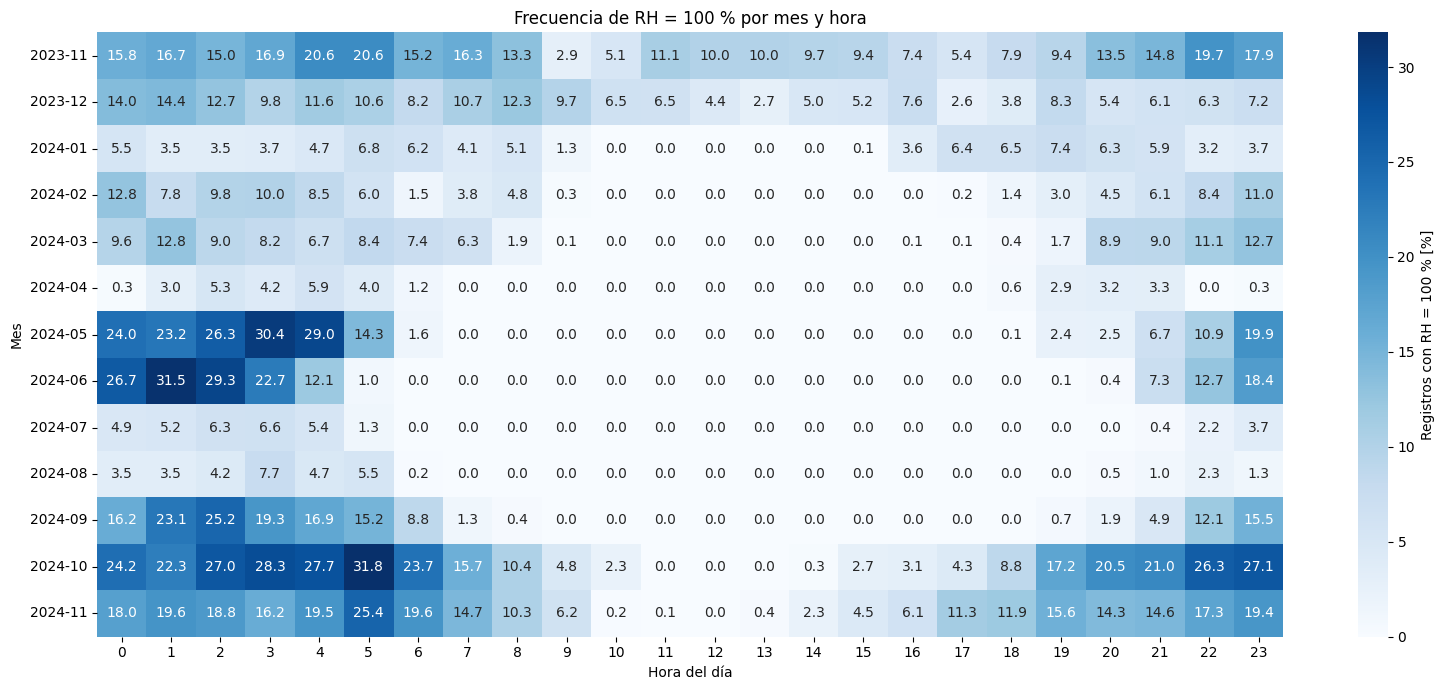

In [101]:
rh_100_heatmap = (
    df_rh
    .assign(rh_100=df_rh["is_rh_100"].astype(int))
    .pivot_table(
        index="year_month",
        columns="hour",
        values="rh_100",
        aggfunc="mean"
    )
    * 100
)

plt.figure(figsize=(16, 7))

sns.heatmap(
    rh_100_heatmap,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    cbar_kws={
        "label": "Registros con RH = 100 % [%]"
    }
)

plt.title("Frecuencia de RH = 100 % por mes y hora")
plt.xlabel("Hora del día")
plt.ylabel("Mes")
plt.tight_layout()
plt.show()

El análisis de las secuencias consecutivas con humedad relativa igual al 100 % muestra que la mayoría de los episodios de saturación son de corta duración. De las aproximadamente 2.070 rachas identificadas, la mayor parte dura menos de una hora y únicamente 12 episodios superan las seis horas. La duración máxima observada es de aproximadamente 8,3 horas, sin que se detecten periodos continuos de varios días con el sensor fijado en su límite superior. Este resultado reduce la posibilidad de un bloqueo prolongado del instrumento.

La mayoría de las rachas largas se produce durante la noche o se extiende desde la tarde hasta las primeras horas de la mañana, lo que resulta compatible con procesos de enfriamiento nocturno, formación de rocío, niebla o condiciones atmosféricas próximas a la saturación. No obstante, se identifican algunos episodios prolongados que abarcan horas diurnas, por lo que será necesario contrastarlos posteriormente con otras variables meteorológicas y radiométricas antes de confirmar su validez.

El análisis conjunto por mes y hora muestra que la humedad relativa mantiene valores elevados durante la noche en todo el periodo estudiado, mientras que durante el día se produce un descenso cuya intensidad depende de la estación. Este descenso es especialmente acusado entre abril y septiembre, alcanzándose los valores medios más bajos durante julio y agosto en las horas centrales del día. En cambio, durante febrero, octubre y noviembre la humedad permanece relativamente elevada incluso durante el periodo diurno.

La dispersión de la humedad presenta también una estructura temporal definida. El rango intercuartílico es generalmente menor durante la noche, cuando las observaciones se concentran en valores altos, y aumenta durante las horas centrales del día, especialmente en primavera y verano. Esta mayor dispersión refleja la coexistencia de jornadas con condiciones atmosféricas muy húmedas y otras considerablemente más secas, y no parece estar asociada a un comportamiento irregular del sensor.

La frecuencia de registros exactamente iguales al 100 % confirma este patrón. En mayo, junio y septiembre la saturación se concentra claramente durante la madrugada y prácticamente desaparece durante las horas centrales. Octubre y noviembre presentan una mayor persistencia de la saturación, incluyendo algunas horas de la tarde y de la noche. Aunque estos meses requieren una revisión más detallada, los patrones observados mantienen una estructura diaria y estacional coherente.

En conjunto, la variable `RH [%]` presenta una elevada calidad y una dinámica temporal físicamente plausible. No se detectan indicios claros de un bloqueo generalizado del sensor, aunque las rachas más prolongadas, especialmente aquellas que se extienden durante horas diurnas, deberán comprobarse posteriormente mediante su comparación con la temperatura, la radiación solar y otras variables meteorológicas disponibles.

## 12. Valores faltantes

In [102]:
missing_summary = (
    df
    .isna()
    .sum()
    .reset_index()
)

missing_summary.columns = ["Variable", "Missing values"]
missing_summary["Missing (%)"] = (
    missing_summary["Missing values"] / len(df) * 100
).round(3)

missing_summary

,Variable,Missing values,Missing (%)
0,Date/Time,0,0.000
1,SWD [W/m**2],929,0.163
2,SWD std dev [W/m**2],929,0.163
3,SWD min [W/m**2],929,0.163
4,SWD max [W/m**2],929,0.163
5,DIR [W/m**2],12300,2.157
6,DIR std dev [W/m**2],12300,2.157
7,DIR min [W/m**2],12300,2.157
8,DIR max [W/m**2],12300,2.157
9,DIF [W/m**2],11605,2.035


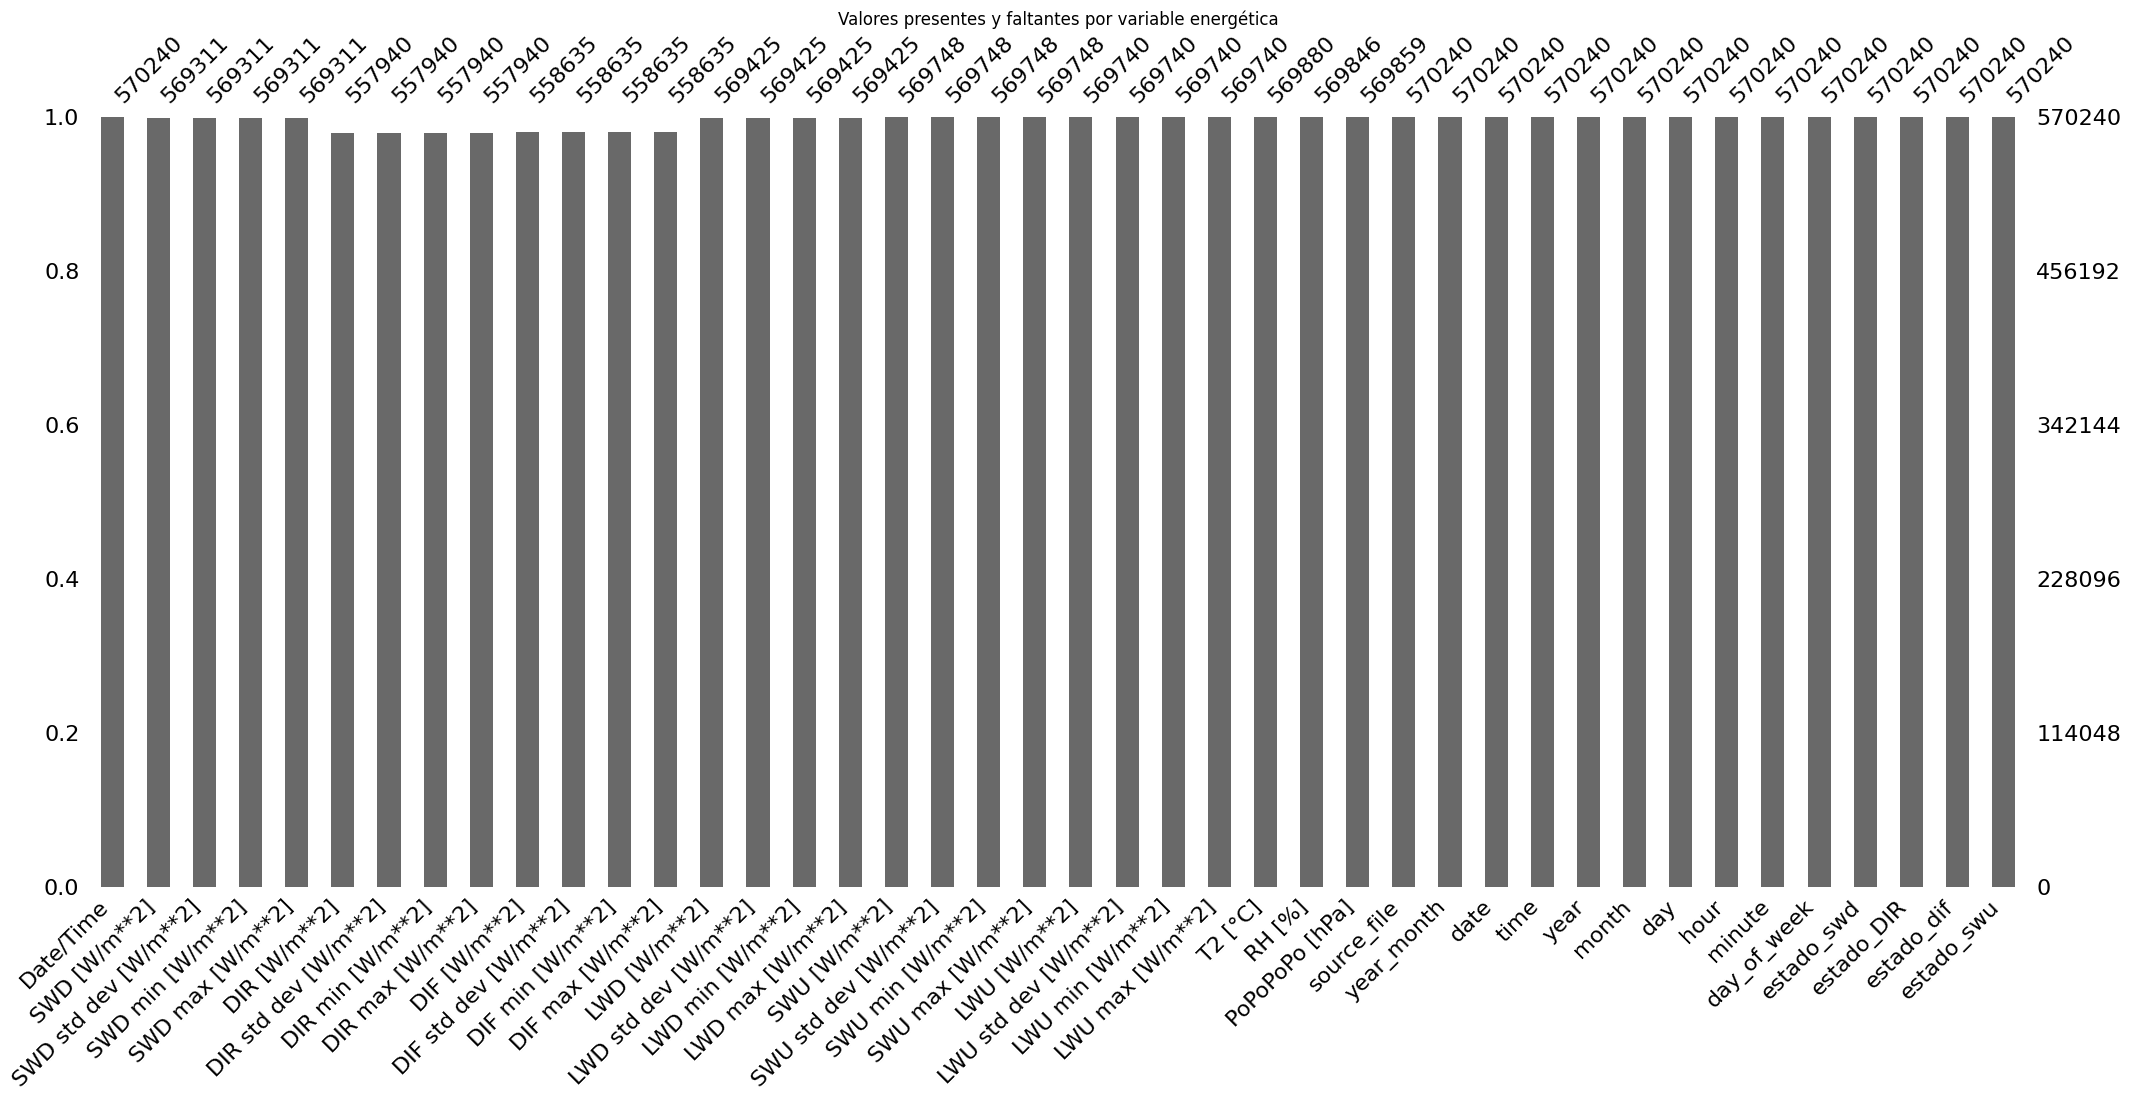

In [103]:
plt.figure(figsize=(10, 5))
msno.bar(df)
plt.title("Valores presentes y faltantes por variable energética")
plt.show()

<Figure size 1200x600 with 0 Axes>

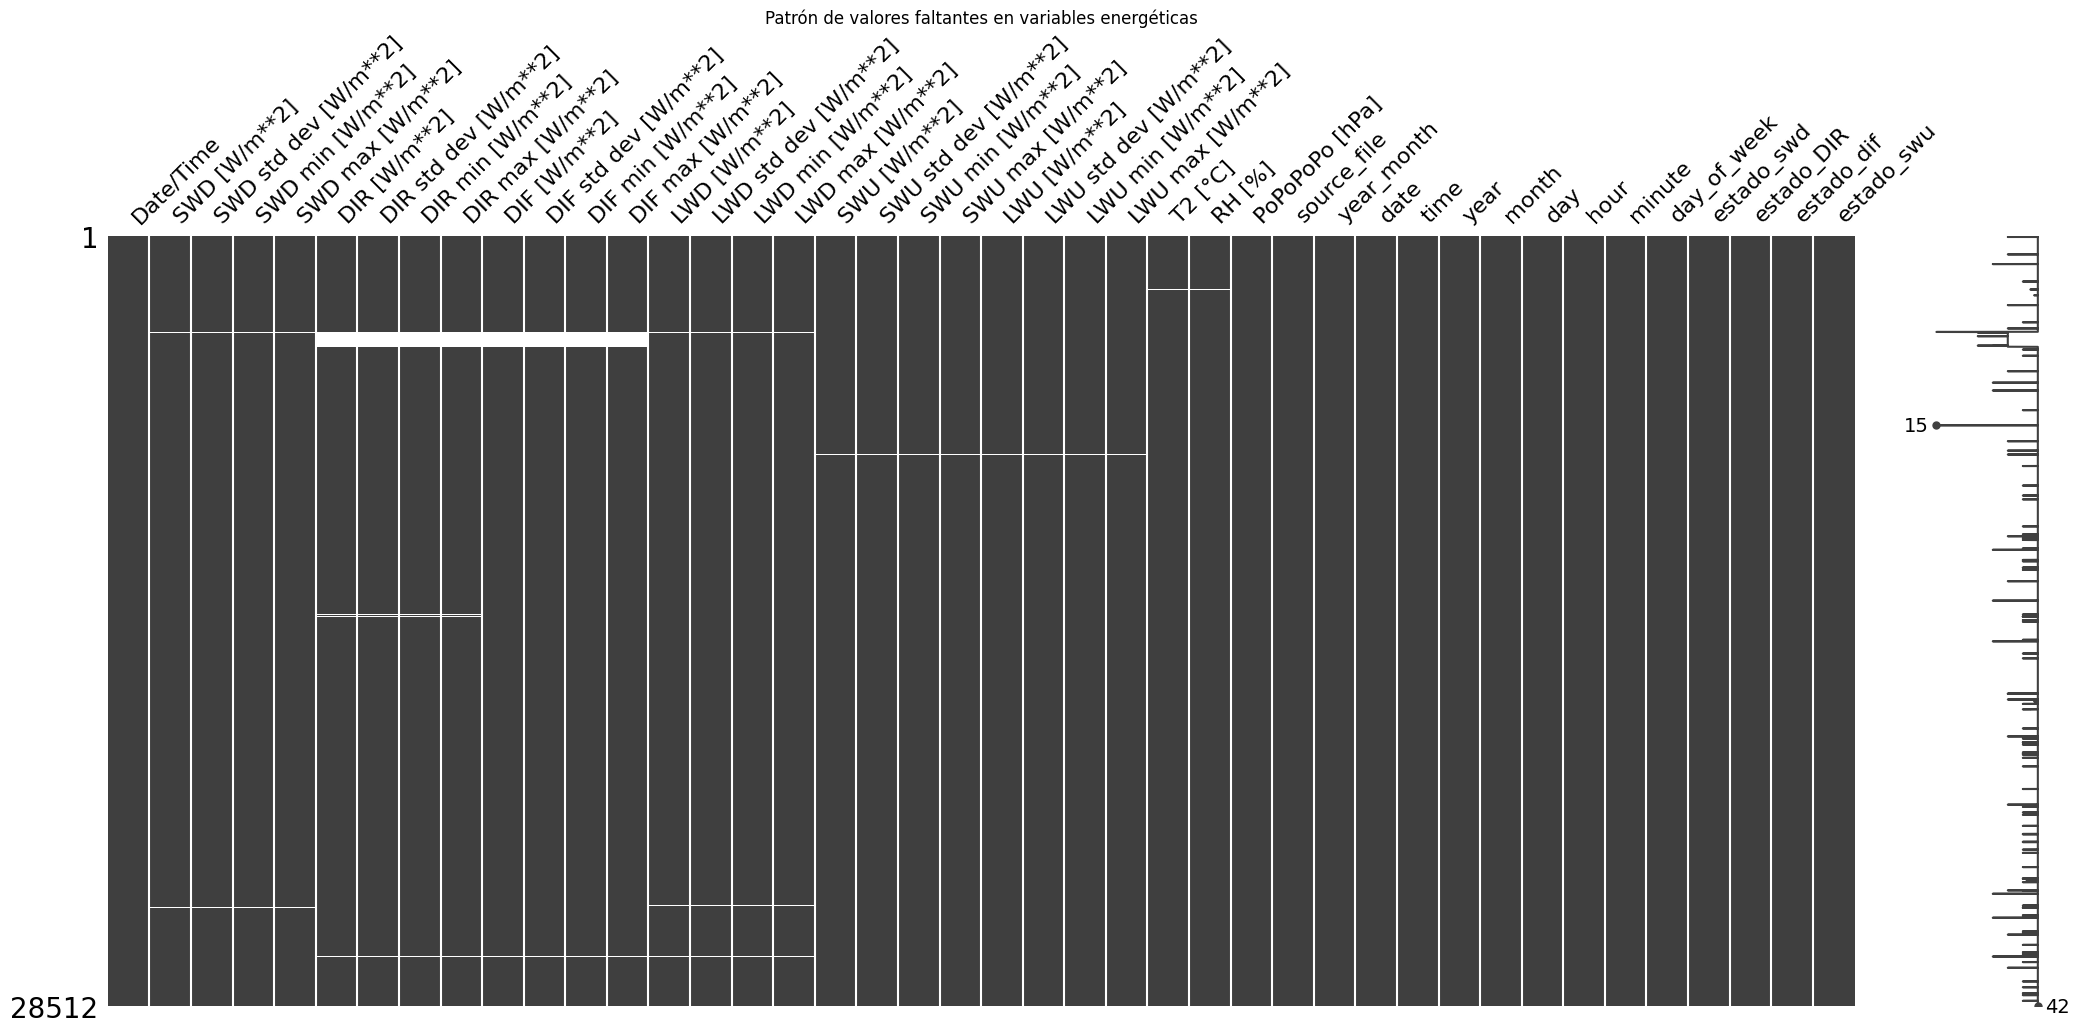

In [104]:
# Muestreo ordenado: mantiene la secuencia temporal
df_sample = df.iloc[::20, :].copy()

plt.figure(figsize=(12, 6))
msno.matrix(df_sample, sparkline=True)
plt.title("Patrón de valores faltantes en variables energéticas")
plt.show()

<Figure size 800x600 with 0 Axes>

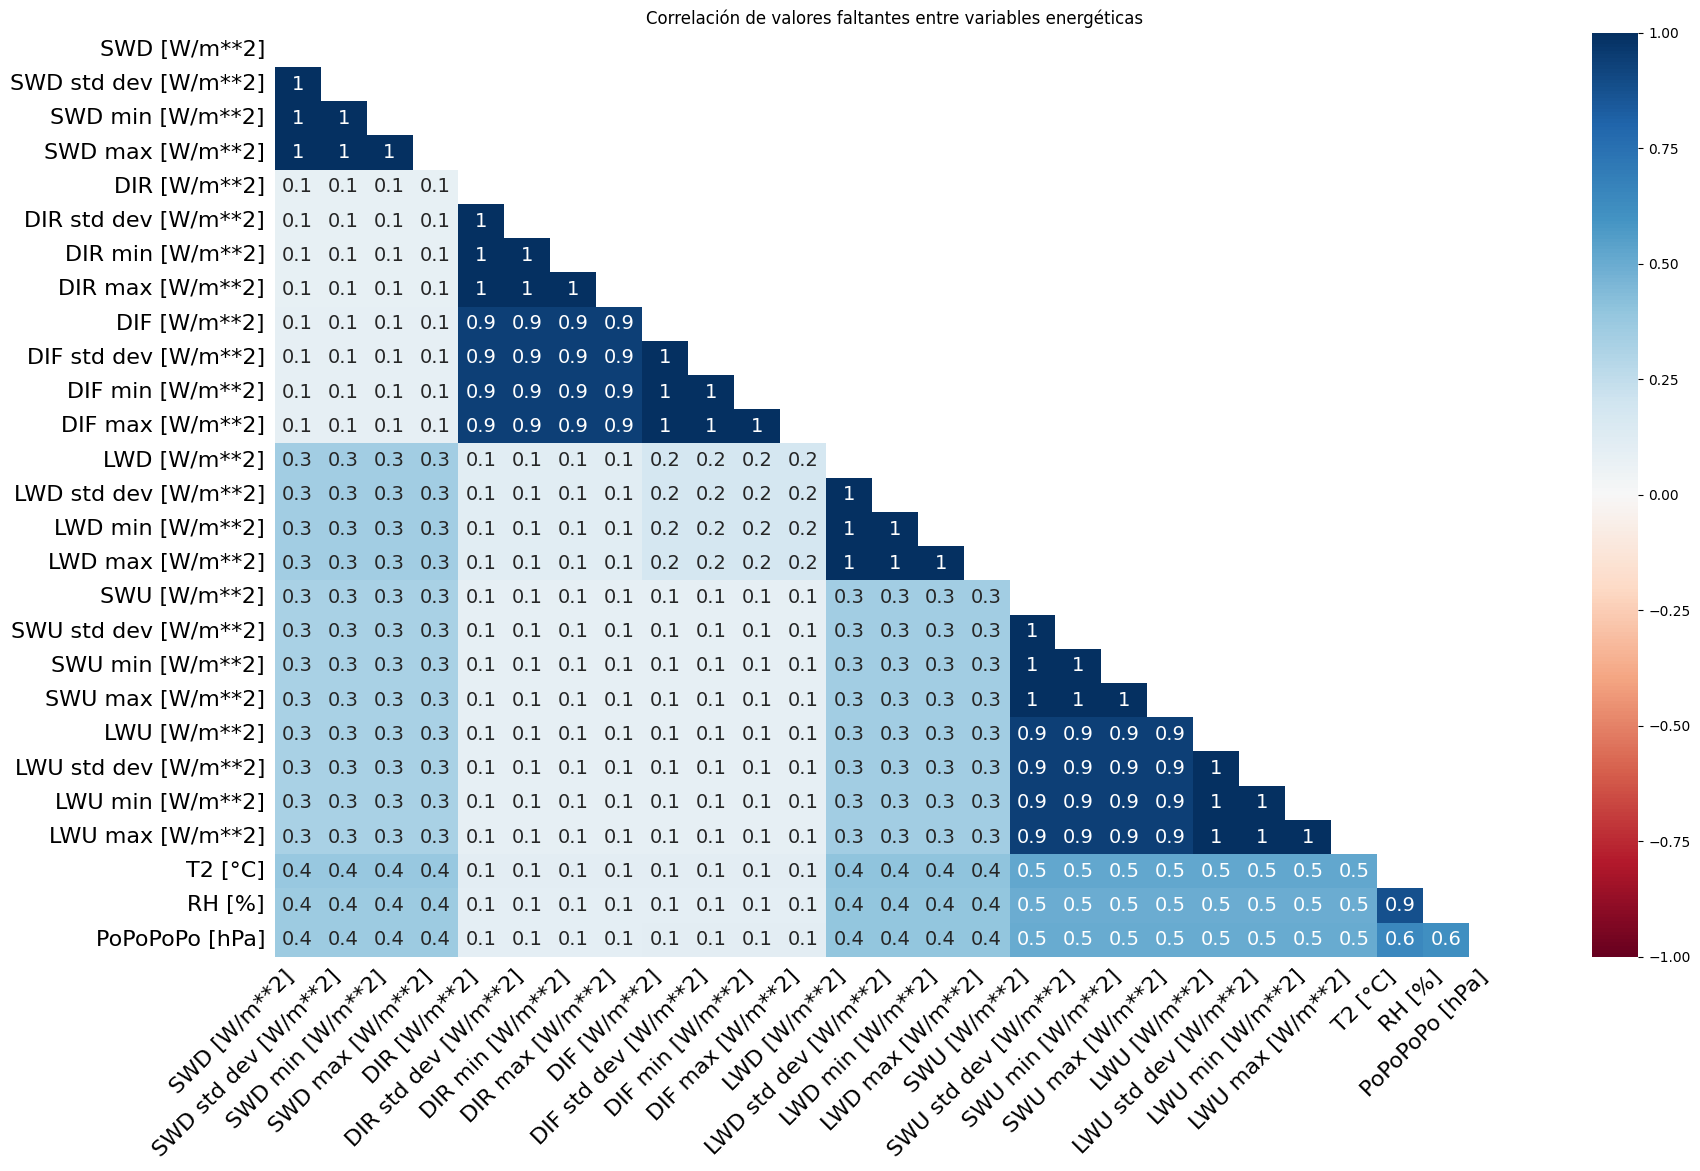

In [105]:
plt.figure(figsize=(8, 6))
msno.heatmap(df)
plt.title("Correlación de valores faltantes entre variables energéticas")
plt.show()

<Figure size 1000x600 with 0 Axes>

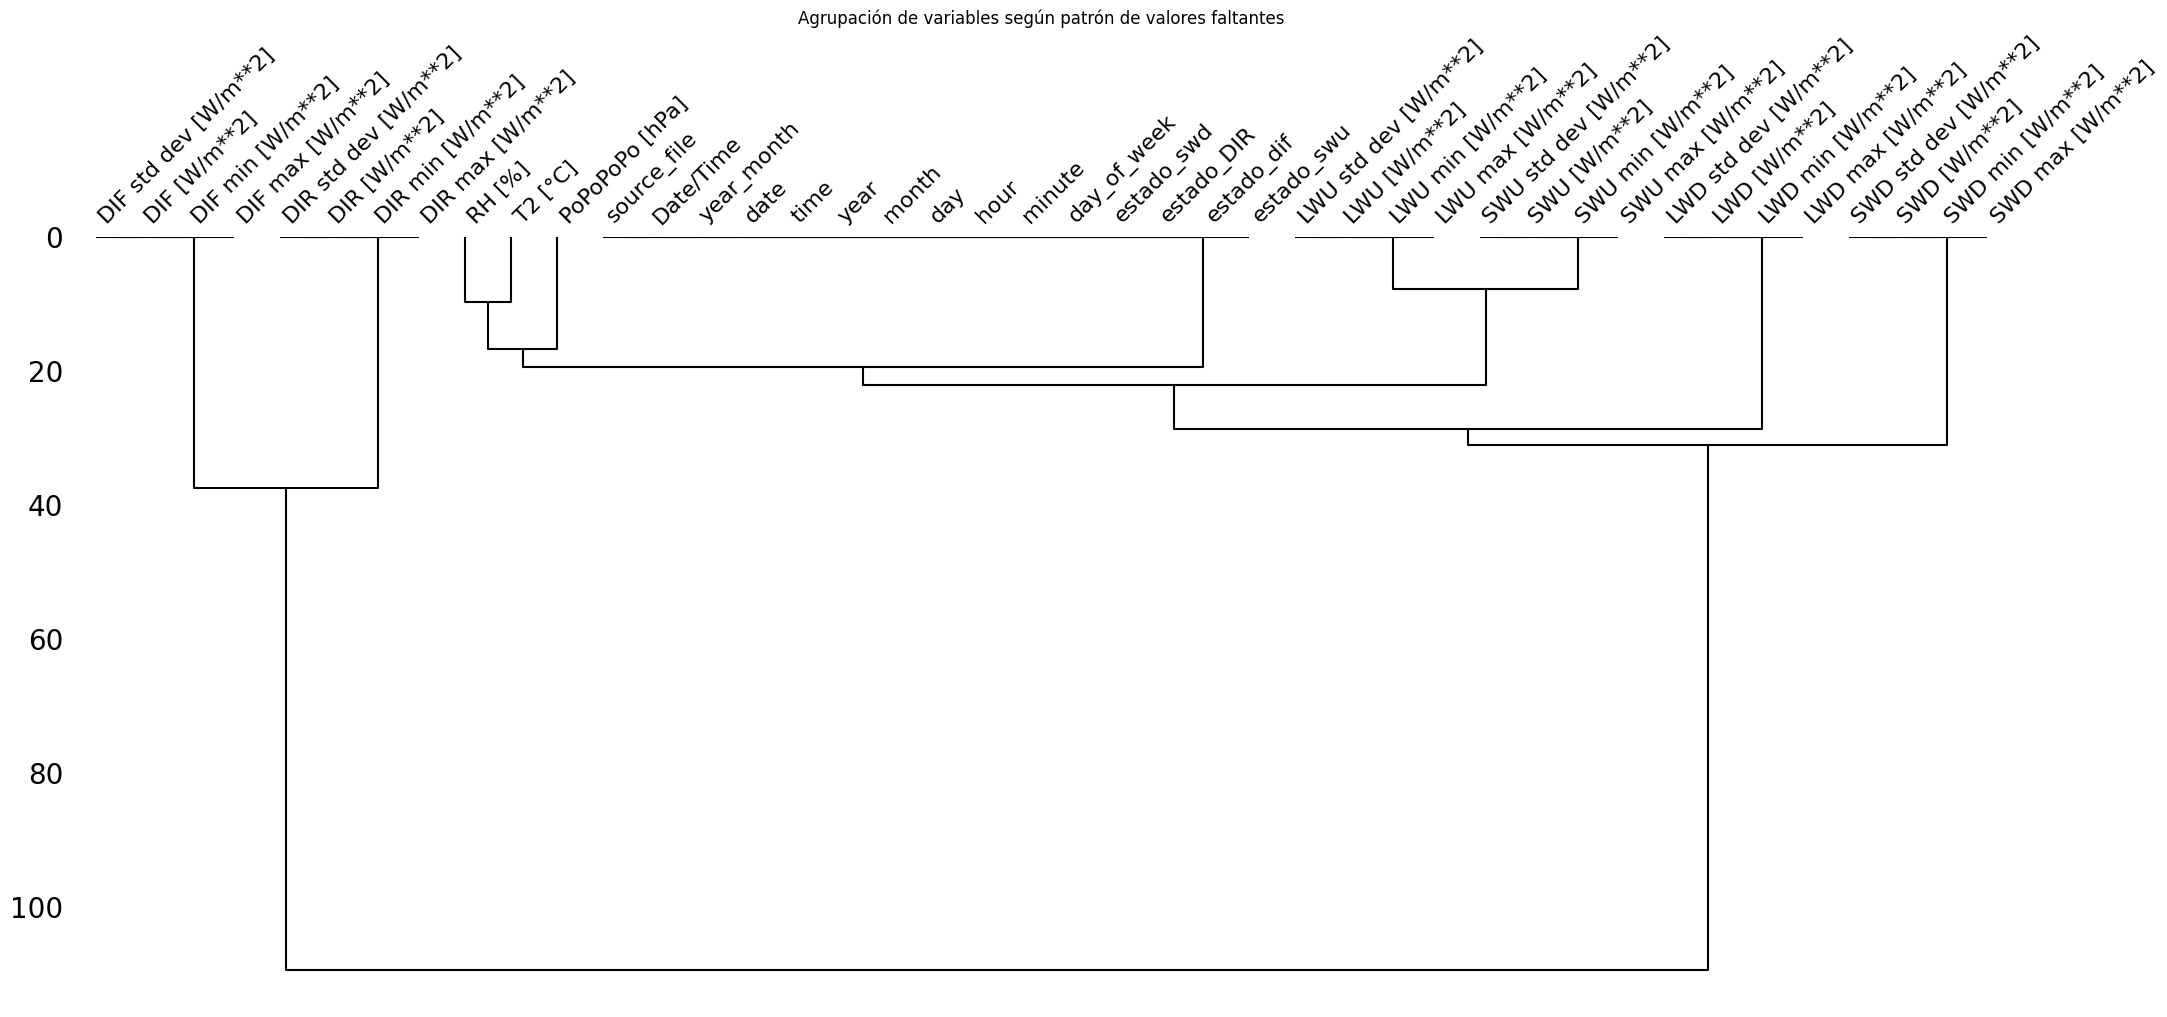

In [106]:
plt.figure(figsize=(10, 6))
msno.dendrogram(df)
plt.title("Agrupación de variables según patrón de valores faltantes")
plt.show()

In [107]:
df_missing = df.copy()
df_missing["any_missing"] = df.isna().any(axis=1)

missing_dates = df_missing[df_missing["any_missing"]]

print("Número de registros con al menos un missing:", len(missing_dates))
print("Primera fecha con missing:", missing_dates["Date/Time"].min())
print("Última fecha con missing:", missing_dates["Date/Time"].max())

missing_dates.head()

Número de registros con al menos un missing: 14070
Primera fecha con missing: 2023-11-01 12:00:00
Última fecha con missing: 2024-11-29 11:15:00


,Date/Time,SWD [W/m**2],SWD std dev [W/m**2],SWD min [W/m**2],SWD max [W/m**2],DIR [W/m**2],DIR std dev [W/m**2],DIR min [W/m**2],DIR max [W/m**2],DIF [W/m**2],...,month,day,hour,minute,day_of_week,estado_swd,estado_DIR,estado_dif,estado_swu,any_missing
720,2023-11-01 12:00:00,187.0,2.7,183.0,191.0,2.0,0.4,1.0,2.0,186.0,...,11,1,12,0,Wednesday,Positivo,Positivo,Positivo,Missing,True
721,2023-11-01 12:01:00,197.0,3.7,192.0,204.0,2.0,0.6,1.0,4.0,197.0,...,11,1,12,1,Wednesday,Positivo,Positivo,Positivo,Missing,True
722,2023-11-01 12:02:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,11,1,12,2,Wednesday,Missing,Missing,Missing,Positivo,True
723,2023-11-01 12:03:00,227.0,2.2,224.0,232.0,NaN,NaN,NaN,NaN,222.0,...,11,1,12,3,Wednesday,Positivo,Missing,Positivo,Positivo,True
3468,2023-11-03 09:48:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,193.0,...,11,3,9,48,Friday,Missing,Missing,Positivo,Positivo,True


In [108]:
df_missing_month = df.copy()
df_missing_month["month"] = df_missing_month["Date/Time"].dt.to_period("M").astype(str)

missing_by_month = (
    df_missing_month
    .groupby("month")
    .apply(lambda x: x.isna().sum())
)

missing_by_month

/tmp/ipykernel_3471/3357943490.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.isna().sum())


,Date/Time,SWD [W/m**2],SWD std dev [W/m**2],SWD min [W/m**2],SWD max [W/m**2],DIR [W/m**2],DIR std dev [W/m**2],DIR min [W/m**2],DIR max [W/m**2],DIF [W/m**2],...,year,month,day,hour,minute,day_of_week,estado_swd,estado_DIR,estado_dif,estado_swu
month,,,,,,,,,,,,,,,,,,,,,
2023-11,0,39,39,39,39,25,25,25,25,19,...,0,0,0,0,0,0,0,0,0,0
2023-12,0,197,197,197,197,11082,11082,11082,11082,11086,...,0,0,0,0,0,0,0,0,0,0
2024-01,0,24,24,24,24,48,48,48,48,30,...,0,0,0,0,0,0,0,0,0,0
2024-02,0,86,86,86,86,48,48,48,48,69,...,0,0,0,0,0,0,0,0,0,0
2024-03,0,56,56,56,56,21,21,21,21,55,...,0,0,0,0,0,0,0,0,0,0
2024-04,0,68,68,68,68,189,189,189,189,48,...,0,0,0,0,0,0,0,0,0,0
2024-05,0,26,26,26,26,179,179,179,179,34,...,0,0,0,0,0,0,0,0,0,0
2024-06,0,33,33,33,33,58,58,58,58,64,...,0,0,0,0,0,0,0,0,0,0
2024-07,0,100,100,100,100,112,112,112,112,74,...,0,0,0,0,0,0,0,0,0,0


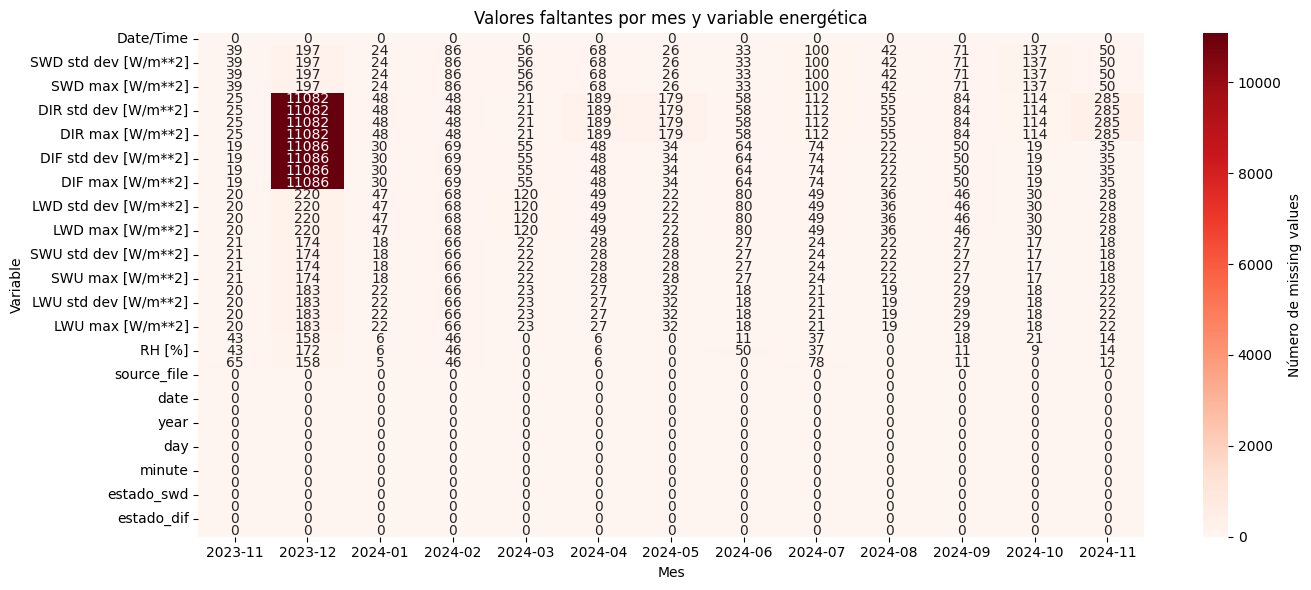

In [109]:
plt.figure(figsize=(14, 6))
sns.heatmap(
    missing_by_month.T,
    cmap="Reds",
    annot=True,
    fmt=".0f",
    cbar_kws={"label": "Número de missing values"}
)

plt.title("Valores faltantes por mes y variable energética")
plt.xlabel("Mes")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

## 13. Fracción difusa (DIF/SWD)

Cociente entre la difusa y la global, calculado solo cuando SWD > 0.

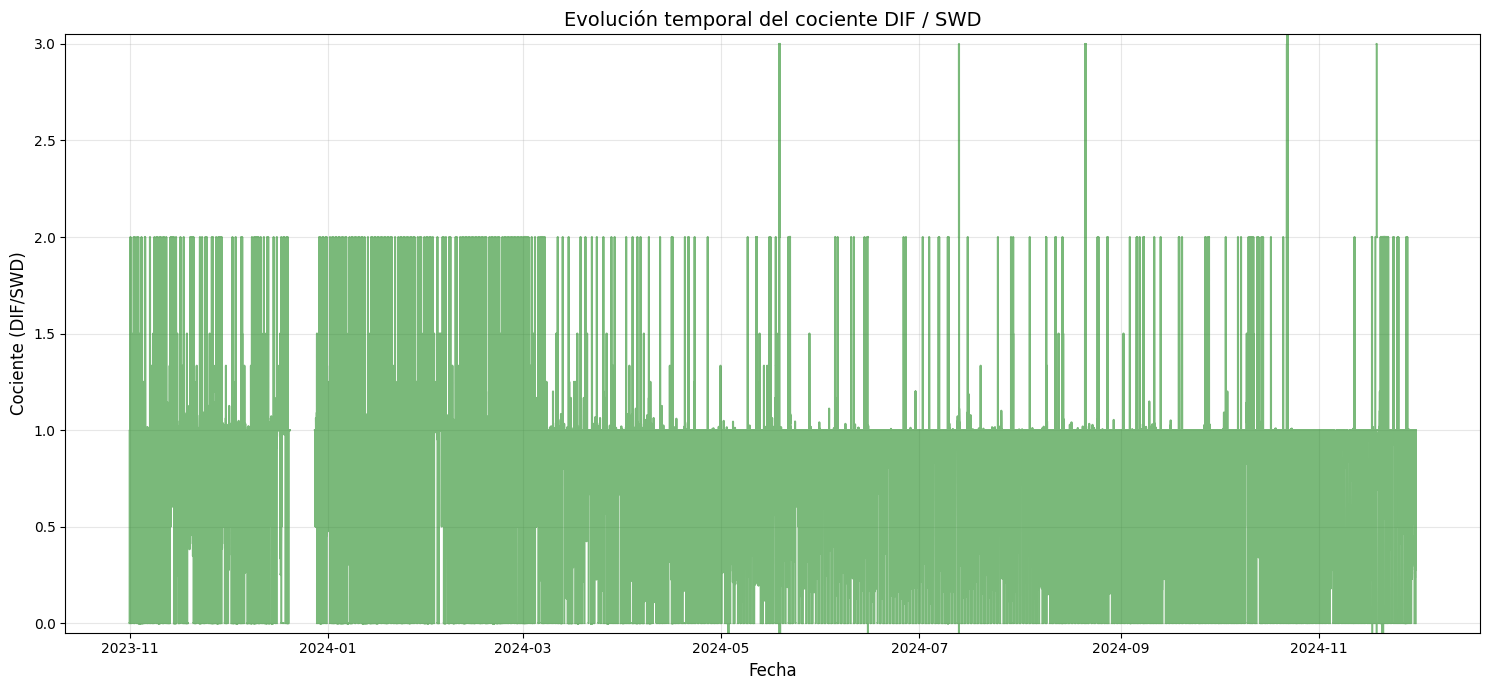

,Date/Time,DIF [W/m**2],SWD [W/m**2],ratio_dif_swd
0,2023-11-01 00:00:00,0.0,-1.0,-0.0
1,2023-11-01 00:01:00,0.0,-1.0,-0.0
2,2023-11-01 00:02:00,0.0,-1.0,-0.0
3,2023-11-01 00:03:00,0.0,-1.0,-0.0
4,2023-11-01 00:04:00,0.0,-1.0,-0.0


In [110]:
# 1. Columnas necesarias
df_cociente = df[['Date/Time', 'DIF [W/m**2]', 'SWD [W/m**2]']].copy()

# 2. Calcular el cociente DIF/SWD
# Solo se calcula con SWD > 0
df_cociente['ratio_dif_swd'] = df_cociente['DIF [W/m**2]'] / df_cociente['SWD [W/m**2]']

# 3. Visualizar la evolución temporal
plt.figure(figsize=(15, 7))
plt.plot(df_cociente['Date/Time'], df_cociente['ratio_dif_swd'], color='forestgreen', alpha=0.6)

plt.title("Evolución temporal del cociente DIF / SWD", fontsize=14)
plt.xlabel("Fecha", fontsize=12)
plt.ylabel("Cociente (DIF/SWD)", fontsize=12)
plt.grid(True, alpha=0.3)
plt.ylim(-0.05, 3.05)
plt.tight_layout()
plt.show()

df_cociente.head()